ANN: epoch 1/1500, loss=0.401814
ANN: epoch 301/1500, loss=0.012277
ANN: epoch 601/1500, loss=0.010902
ANN: epoch 901/1500, loss=0.008977
ANN: epoch 1201/1500, loss=0.005185
ANN: epoch 1500/1500, loss=0.003838
ANFIS: epoch 1/1500, loss=0.404596
ANFIS: epoch 301/1500, loss=0.046347
ANFIS: epoch 601/1500, loss=0.017277
ANFIS: epoch 901/1500, loss=0.014589
ANFIS: epoch 1201/1500, loss=0.013395
ANFIS: epoch 1500/1500, loss=0.012073
PINN lambda=0.001: epoch 1/1500, loss=0.551587
PINN lambda=0.001: epoch 301/1500, loss=0.165575
PINN lambda=0.001: epoch 601/1500, loss=0.160690
PINN lambda=0.001: epoch 901/1500, loss=0.158758
PINN lambda=0.001: epoch 1201/1500, loss=0.157867
PINN lambda=0.001: epoch 1500/1500, loss=0.152569

Comparison Results (Test Set)
Model       R2      MAE     RMSE     MAPE       WI
  ANN 0.989272 1.671001 2.617429 0.161852 0.997354
ANFIS 0.962632 2.389088 4.884955 0.230370 0.990820
 PINN 0.993786 0.993590 1.992099 0.095636 0.998469


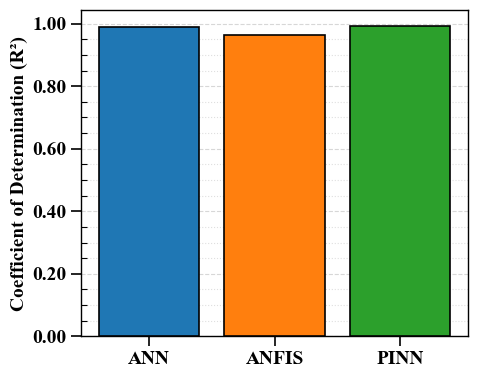

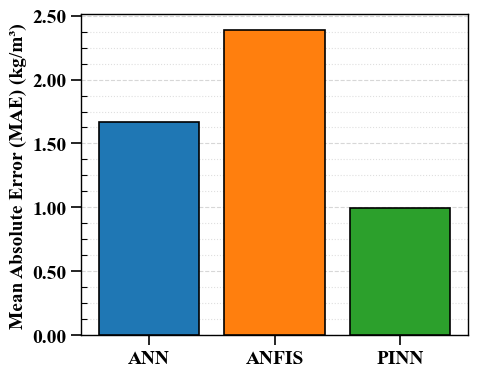

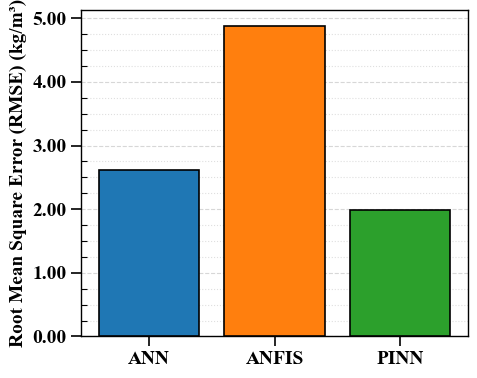

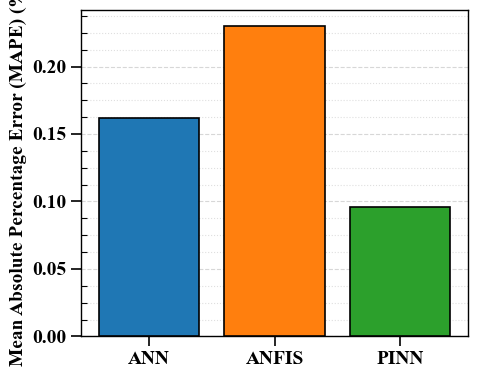

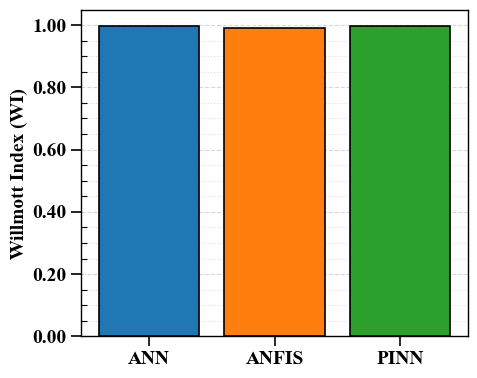

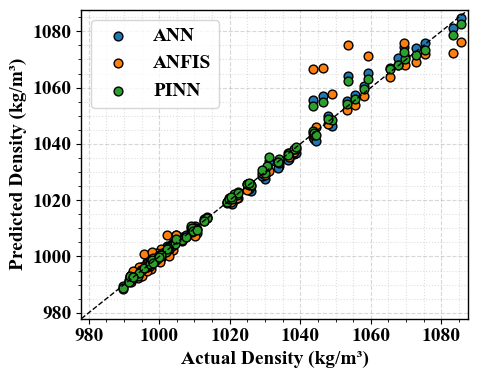


Done. Results saved in: C:\Users\masal\Desktop\ANN_ANFIS_PINN_Corrected


In [29]:
# ANN vs ANFIS vs PINN — corrected fair comparison
# Hybrid nanofluid density prediction; Jupyter compatible.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from matplotlib.ticker import AutoMinorLocator, FormatStrFormatter
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

SEED = 42
EPOCHS = 1500
LEARNING_RATE = 0.001
LAMBDA_PHY = 0.001  # Physics regularization weight
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass
plt.rcParams.update({'font.family':'Times New Roman','font.weight':'bold',
                     'axes.labelweight':'bold','axes.titleweight':'bold'})
output_dir = os.path.join(os.path.expanduser('~'), 'Desktop', 'ANN_ANFIS_PINN_Corrected')
try:
    os.makedirs(output_dir, exist_ok=True)
except OSError:
    output_dir = os.path.join(os.getcwd(), 'ANN_ANFIS_PINN_Corrected')
    os.makedirs(output_dir, exist_ok=True)

file_path = 'Density_Prediction_Dataset.csv'
if not os.path.isfile(file_path):
    raise FileNotFoundError(f'Place {file_path} in the current working directory: {os.getcwd()}')
df = pd.read_csv(file_path)
columns = ['NanoParticle','BaseFluid','Temperature','VolumeConcentration',
           'rho_np1','rho_np2','rho_bf','phi1','phi2','Density']
if len(df.columns) != len(columns):
    raise ValueError(f'Expected {len(columns)} columns, found {len(df.columns)}')
df.columns = columns
numeric_cols = ['Temperature','VolumeConcentration','rho_np1','rho_np2',
                'rho_bf','phi1','phi2','Density']
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df = df.dropna(subset=columns).reset_index(drop=True)
# The supplied dataset records phi1 and phi2 in percent.
df['phi1'] /= 100.0
df['phi2'] /= 100.0
if (df[['phi1','phi2']].lt(0).any().any() or
    (df['phi1']+df['phi2'] > 1).any()):
    raise ValueError('Invalid phi1/phi2 values after percent-to-fraction conversion.')
df['rho_physics'] = (df['phi1']*df['rho_np1'] + df['phi2']*df['rho_np2']
                     + (1-df['phi1']-df['phi2'])*df['rho_bf'])
features = ['NanoParticle','BaseFluid','Temperature','VolumeConcentration','phi1','phi2']
X = df[features]
y = df['Density'].to_numpy(dtype=np.float64).reshape(-1,1)
physics = df['rho_physics'].to_numpy(dtype=np.float64).reshape(-1,1)
indices = np.arange(len(df))
train_idx, test_idx = train_test_split(indices, test_size=0.2, random_state=SEED)
try:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)
preprocessor = ColumnTransformer([
    ('num',StandardScaler(),['Temperature','VolumeConcentration','phi1','phi2']),
    ('cat',encoder,['NanoParticle','BaseFluid'])
])
X_train = np.asarray(preprocessor.fit_transform(X.iloc[train_idx]),dtype=np.float32)
X_test = np.asarray(preprocessor.transform(X.iloc[test_idx]),dtype=np.float32)
y_scaler = StandardScaler().fit(y[train_idx])
y_train = y_scaler.transform(y[train_idx]).astype(np.float32)
y_test_true = y[test_idx]
phy_train = y_scaler.transform(physics[train_idx]).astype(np.float32)
X_train_tf = tf.convert_to_tensor(X_train)
y_train_tf = tf.convert_to_tensor(y_train)
phy_train_tf = tf.convert_to_tensor(phy_train)

# ANN and PINN have precisely the same architecture (64-32-16).
# Their only possible difference is the physics term in the loss.
def make_network(input_dim):
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(input_dim,)),
        tf.keras.layers.Dense(600, activation='tanh'),
        tf.keras.layers.Dense(200, activation='tanh'),
        tf.keras.layers.Dense(200, activation='tanh'),
        tf.keras.layers.Dense(1)
    ])

class ANFIS(tf.keras.Model):
    def __init__(self, input_dim, n_rules=12):
        super().__init__()
        self.centers = self.add_weight(name='centers',shape=(input_dim,n_rules),initializer='random_normal',trainable=True)
        self.sigmas = self.add_weight(name='sigmas',shape=(input_dim,n_rules),initializer='ones',trainable=True)
        self.consequents = self.add_weight(name='consequents',shape=(n_rules,input_dim),initializer='random_normal',trainable=True)
        self.bias = self.add_weight(name='bias',shape=(n_rules,),initializer='zeros',trainable=True)
    def call(self,x,training=False):
        x_exp = tf.expand_dims(x,axis=2)
        centers = tf.expand_dims(self.centers,axis=0)
        sigmas = tf.expand_dims(tf.nn.softplus(self.sigmas)+1e-6,axis=0)
        membership = tf.exp(-0.5*tf.square((x_exp-centers)/sigmas))
        firing = tf.reduce_prod(membership,axis=1)
        normalized = firing/(tf.reduce_sum(firing,axis=1,keepdims=True)+1e-6)
        rules = tf.matmul(x,self.consequents,transpose_b=True)+self.bias
        return tf.reduce_sum(normalized*rules,axis=1,keepdims=True)

huber = tf.keras.losses.Huber()

def train_model(model, name, lambda_phy=0.0):
    optimizer = tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE)
    history = []
    # Exactly the same training algorithm for ANN and PINN at lambda=0.
    @tf.function
    def step(x, target, rho):
        with tf.GradientTape() as tape:
            pred = model(x,training=True)
            data_loss = huber(target,pred)
            if lambda_phy == 0.0:
                loss = data_loss
            else:
                loss = data_loss + tf.cast(lambda_phy,tf.float32)*huber(rho,pred)
        gradients = tape.gradient(loss,model.trainable_variables)
        optimizer.apply_gradients(zip(gradients,model.trainable_variables))
        return loss
    for epoch in range(EPOCHS):
        loss = step(X_train_tf,y_train_tf,phy_train_tf)
        history.append(float(loss.numpy()))
        if epoch % 300 == 0 or epoch == EPOCHS-1:
            print(f'{name}: epoch {epoch+1}/{EPOCHS}, loss={history[-1]:.6f}')
    return history

input_dim = X_train.shape[1]
ann = make_network(input_dim)
initial_weights = ann.get_weights()
pinn = make_network(input_dim)
pinn.set_weights(initial_weights)
anfis = ANFIS(input_dim, n_rules=12)
_ = anfis(X_train_tf[:1])  # Build variables before training
history_ann = train_model(ann,'ANN',lambda_phy=0.0)
history_anfis = train_model(anfis,'ANFIS',lambda_phy=0.0)
history_pinn = train_model(pinn,f'PINN lambda={LAMBDA_PHY:g}',lambda_phy=LAMBDA_PHY)

def predict(model, x):
    return y_scaler.inverse_transform(model(x,training=False).numpy()).ravel()

predictions = {
    'ANN':predict(ann,X_test),
    'ANFIS':predict(anfis,X_test),
    'PINN':predict(pinn,X_test)
}
actual = y_test_true.ravel()

def metrics(true, pred):
    """R2, MAE, RMSE (kg/m3), MAPE (%), and Willmott index."""
    true = np.asarray(true, dtype=np.float64).ravel()
    pred = np.asarray(pred, dtype=np.float64).ravel()
    r2 = r2_score(true, pred)
    mae = mean_absolute_error(true, pred)
    rmse = np.sqrt(mean_squared_error(true, pred))
    # MAPE is undefined for a zero actual value: explicitly report NaN.
    mape = (100.0 * np.mean(np.abs((true - pred) / true))
            if np.all(true != 0) else np.nan)
    mean_true = np.mean(true)
    wi_denominator = np.sum((np.abs(pred - mean_true) + np.abs(true - mean_true)) ** 2)
    wi_numerator = np.sum((true - pred) ** 2)
    wi = (1.0 - wi_numerator / wi_denominator if wi_denominator > 0
          else (1.0 if wi_numerator == 0 else np.nan))
    return [r2, mae, rmse, mape, wi]

results_df = pd.DataFrame([
    [name, *metrics(actual, pred)] for name, pred in predictions.items()
], columns=['Model', 'R2', 'MAE', 'RMSE', 'MAPE', 'WI'])
print('\nComparison Results (Test Set)')
print(results_df.to_string(index=False,float_format=lambda v:f'{v:.6f}'))
if LAMBDA_PHY == 0.0:
    max_difference = float(np.max(np.abs(predictions['ANN']-predictions['PINN'])))
    print(f'\nANN vs PINN(lambda=0) max absolute prediction difference: {max_difference:.12g} kg/m³')
    np.testing.assert_allclose(predictions['ANN'],predictions['PINN'],rtol=1e-5,atol=1e-4,
        err_msg='ANN and PINN(lambda=0) should match: check environment determinism.')
    print('PASS: ANN and PINN(lambda=0) match within numerical tolerance.')

results_df.to_excel(os.path.join(output_dir,'ANN_ANFIS_PINN_Comparison.xlsx'),index=False)
predictions_df = pd.DataFrame({'Actual Density':actual,
                               **{f'{k} Prediction':v for k,v in predictions.items()}})
predictions_df.to_excel(os.path.join(output_dir,'ANN_ANFIS_PINN_Predictions.xlsx'),index=False)
pd.DataFrame({'Epoch':np.arange(1,EPOCHS+1),'ANN':history_ann,
              'ANFIS':history_anfis,'PINN':history_pinn}).to_csv(
                  os.path.join(output_dir,'Training_History.csv'),index=False)
colors={'ANN':'#1f77b4','ANFIS':'#ff7f0e','PINN':'#2ca02c'}

# Five matching metric bar charts: existing R2 + four new charts.
metric_labels = {
    'R2': 'Coefficient of Determination (R²)',
    'MAE': 'Mean Absolute Error (MAE) (kg/m³)',
    'RMSE': 'Root Mean Square Error (RMSE) (kg/m³)',
    'MAPE': 'Mean Absolute Percentage Error (MAPE) (%)',
    'WI': 'Willmott Index (WI)'
}
for metric, ylabel in metric_labels.items():
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.set_axisbelow(True)
    ax.bar(results_df['Model'], results_df[metric],
           color=[colors[k] for k in results_df['Model']],
           edgecolor='black', linewidth=1.2, zorder=3)
    ax.set_ylabel(ylabel, fontweight='bold')
    ax.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))
    ax.yaxis.set_minor_locator(AutoMinorLocator(4))
    ax.grid(True, which='major', axis='y', linestyle='--', alpha=.5, zorder=0)
    ax.grid(True, which='minor', axis='y', linestyle=':', alpha=.4, zorder=0)
    ax.tick_params(axis='both', which='major', direction='out', length=7, width=1.2)
    ax.tick_params(axis='y', which='minor', direction='in', length=4, width=.8)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight('bold')
    fig.tight_layout()
    filename = f'ANN_ANFIS_PINN_{metric}_Comparison.png'
    fig.savefig(os.path.join(output_dir, filename), dpi=300,
                bbox_inches='tight', pad_inches=.1)
    plt.show()

fig,ax=plt.subplots(figsize=(5,4))
ax.set_axisbelow(True)
for name,pred in predictions.items():
    ax.scatter(actual,pred,color=colors[name],edgecolor='black',label=name,s=40,zorder=3)
y_min = min(980.0,float(np.min(actual)),*(float(np.min(v)) for v in predictions.values()))
y_max = max(float(np.max(actual)),*(float(np.max(v)) for v in predictions.values()))
margin = max((y_max-y_min)*.02,1.0)
y_min -= margin
y_max += margin
ax.set_xlim(y_min,y_max)
ax.set_ylim(y_min,y_max)
ax.plot([y_min,y_max],[y_min,y_max],'k--',linewidth=1,zorder=3)
ax.set_xlabel('Actual Density (kg/m³)',fontweight='bold')
ax.set_ylabel('Predicted Density (kg/m³)',fontweight='bold')
ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))
ax.yaxis.set_major_formatter(FormatStrFormatter('%.0f'))
ax.xaxis.set_minor_locator(AutoMinorLocator(4))
ax.yaxis.set_minor_locator(AutoMinorLocator(4))
ax.grid(True,which='major',linestyle='--',alpha=.5,zorder=0)
ax.grid(True,which='minor',linestyle=':',alpha=.4,zorder=0)
ax.legend(prop={'weight':'bold','family':'Times New Roman'})
fig.tight_layout()
fig.savefig(os.path.join(output_dir,'ANN_ANFIS_PINN_Actual_vs_Predicted.png'),dpi=300,bbox_inches='tight')
plt.show()
print('\nDone. Results saved in:',output_dir)


In [16]:
"""Repeated 5-fold cross-validation (3 repeats, 15 test folds) for density models.
Fixed: eager GradientTape training with a fresh Adam optimizer for each model/fold.
Run in the folder containing Density_Prediction_Dataset.csv.
All preprocessing is fit inside each training fold. PINN physics weight = 0.001.
"""
import os
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import RepeatedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from matplotlib.ticker import AutoMinorLocator, FormatStrFormatter

SEED = 42
N_SPLITS = 5
N_REPEATS = 3
EPOCHS = 1500
LEARNING_RATE = 0.001
LAMBDA_PHY = 0.001
N_RULES = 12
FILE_NAME = 'Density_Prediction_Dataset.csv'
OUTPUT_DIR = os.path.join(os.getcwd(), 'Repeated_5Fold_CV_Results')
os.makedirs(OUTPUT_DIR, exist_ok=True)

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass
plt.rcParams.update({'font.family':'Times New Roman', 'font.weight':'bold',
                     'axes.labelweight':'bold', 'axes.titleweight':'bold'})

cols = ['NanoParticle','BaseFluid','Temperature','VolumeConcentration',
        'rho_np1','rho_np2','rho_bf','phi1','phi2','Density']
if not os.path.exists(FILE_NAME):
    raise FileNotFoundError(f'Place {FILE_NAME} in {os.getcwd()}')
df = pd.read_csv(FILE_NAME)
if len(df.columns) != len(cols):
    raise ValueError(f'Expected {len(cols)} columns, got {len(df.columns)}')
df.columns = cols
for c in cols[2:]:
    df[c] = pd.to_numeric(df[c], errors='coerce')
df = df.dropna(subset=cols).reset_index(drop=True)
# Original dataset expresses volume fractions as percentages.
df['phi1'] /= 100.0
df['phi2'] /= 100.0
if (df[['phi1','phi2']] < 0).any().any() or (df['phi1'] + df['phi2'] > 1).any():
    raise ValueError('Check whether phi1 and phi2 are expressed in percent.')
df['rho_physics'] = (df['phi1']*df['rho_np1'] + df['phi2']*df['rho_np2']
                     + (1-df['phi1']-df['phi2'])*df['rho_bf'])
feature_cols = ['NanoParticle','BaseFluid','Temperature','VolumeConcentration','phi1','phi2']
num_cols = ['Temperature','VolumeConcentration','phi1','phi2']
cat_cols = ['NanoParticle','BaseFluid']
X_raw = df[feature_cols]
y_raw = df['Density'].to_numpy(dtype=float).reshape(-1,1)
phy_raw = df['rho_physics'].to_numpy(dtype=float).reshape(-1,1)


def make_preprocessor():
    try:
        enc = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    except TypeError:
        enc = OneHotEncoder(handle_unknown='ignore', sparse=False)
    return ColumnTransformer([('num',StandardScaler(),num_cols),('cat',enc,cat_cols)])


def make_network(input_dim):
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(input_dim,)),
        tf.keras.layers.Dense(64, activation='tanh'),
        tf.keras.layers.Dense(32, activation='tanh'),
        tf.keras.layers.Dense(16, activation='tanh'),
        tf.keras.layers.Dense(1)
    ])


class ANFIS(tf.keras.Model):
    def __init__(self, input_dim, n_rules=12):
        super().__init__()
        self.centers = self.add_weight(name='centers',shape=(input_dim,n_rules),
                                       initializer='random_normal',trainable=True)
        self.sigmas = self.add_weight(name='sigmas',shape=(input_dim,n_rules),
                                      initializer='ones',trainable=True)
        self.consequents = self.add_weight(name='consequents',shape=(n_rules,input_dim),
                                           initializer='random_normal',trainable=True)
        self.bias = self.add_weight(name='bias',shape=(n_rules,),
                                    initializer='zeros',trainable=True)

    def call(self,x,training=False):
        expanded = tf.expand_dims(x,axis=2)
        sigma = tf.expand_dims(tf.nn.softplus(self.sigmas)+1e-6,axis=0)
        membership = tf.exp(-0.5*tf.square((expanded-tf.expand_dims(self.centers,axis=0))/sigma))
        firing = tf.reduce_prod(membership,axis=1)
        normalized = firing/(tf.reduce_sum(firing,axis=1,keepdims=True)+1e-6)
        consequent = tf.matmul(x,self.consequents,transpose_b=True)+self.bias
        return tf.reduce_sum(normalized*consequent,axis=1,keepdims=True)


def step(model, optimizer, x, y, p, lambda_phy):
    with tf.GradientTape() as tape:
        pred = model(x, training=True)
        loss_data = tf.reduce_mean(tf.keras.losses.huber(y,pred))
        loss_phy = tf.reduce_mean(tf.keras.losses.huber(p,pred))
        loss = loss_data + lambda_phy*loss_phy
    grads = tape.gradient(loss, model.trainable_variables)
    pairs = [(g, v) for g, v in zip(grads, model.trainable_variables) if g is not None]
    optimizer.apply_gradients(pairs)
    return loss


def train(model, x, y, p, weight):
    opt = tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE)
    x = tf.convert_to_tensor(x,dtype=tf.float32)
    y = tf.convert_to_tensor(y,dtype=tf.float32)
    p = tf.convert_to_tensor(p,dtype=tf.float32)
    w = tf.constant(weight,dtype=tf.float32)
    # Eager execution avoids Keras optimizer-variable creation inside a shared tf.function.
    # Each call uses a fresh optimizer and a separately built model.
    for _ in range(EPOCHS):
        step(model,opt,x,y,p,w)
    return model


def metrics(y_true,y_pred):
    a = np.asarray(y_true).reshape(-1)
    b = np.asarray(y_pred).reshape(-1)
    r2 = r2_score(a,b)
    mae = mean_absolute_error(a,b)
    rmse = np.sqrt(mean_squared_error(a,b))
    mape = np.mean(np.abs((a-b)/a))*100 if np.all(a != 0) else np.nan
    denom = np.sum((np.abs(b-np.mean(a))+np.abs(a-np.mean(a)))**2)
    wi = 1-np.sum((a-b)**2)/denom if denom > 0 else np.nan
    return dict(R2=r2,MAE=mae,RMSE=rmse,MAPE=mape,WI=wi)


rows = []
prediction_rows = []
rkf = RepeatedKFold(n_splits=N_SPLITS,n_repeats=N_REPEATS,random_state=SEED)
for fold_num,(train_idx,test_idx) in enumerate(rkf.split(X_raw),start=1):
    repetition = (fold_num-1)//N_SPLITS + 1
    fold = (fold_num-1)%N_SPLITS + 1
    preprocessor = make_preprocessor()
    x_train = np.asarray(preprocessor.fit_transform(X_raw.iloc[train_idx]),dtype=np.float32)
    x_test = np.asarray(preprocessor.transform(X_raw.iloc[test_idx]),dtype=np.float32)
    y_scaler = StandardScaler().fit(y_raw[train_idx])
    y_train = y_scaler.transform(y_raw[train_idx]).astype(np.float32)
    phy_train = y_scaler.transform(phy_raw[train_idx]).astype(np.float32)
    true = y_raw[test_idx].reshape(-1)
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED+fold_num)
    # ANN and PINN have exactly the same initial weights and architecture.
    baseline = make_network(x_train.shape[1])
    common_weights = baseline.get_weights()
    del baseline
    for name in ['ANN','ANFIS','PINN']:
        if name == 'ANFIS':
            tf.keras.utils.set_random_seed(SEED+1000+fold_num)
            model = ANFIS(x_train.shape[1],N_RULES)
            model(tf.convert_to_tensor(x_train[:1]))
        else:
            model = make_network(x_train.shape[1])
            model.set_weights(common_weights)
        lam = LAMBDA_PHY if name == 'PINN' else 0.0
        model = train(model,x_train,y_train,phy_train,lam)
        scaled_pred = model(tf.convert_to_tensor(x_test),training=False).numpy()
        pred = y_scaler.inverse_transform(scaled_pred).reshape(-1)
        rows.append(dict(Model=name,Repetition=repetition,Fold=fold,
                         Fold_ID=fold_num,N_train=len(train_idx),N_test=len(test_idx),
                         **metrics(true,pred)))
        prediction_rows.extend(dict(Model=name,Repetition=repetition,Fold=fold,
                                    Row_Index=int(idx),Actual=float(a),Predicted=float(b))
                               for idx,a,b in zip(test_idx,true,pred))
        print(f'Repetition {repetition}/3 | Fold {fold}/5 | {name:5s} | '
              f'R2={rows[-1]["R2"]:.4f} MAE={rows[-1]["MAE"]:.4f} RMSE={rows[-1]["RMSE"]:.4f}',flush=True)
        del model
        gc.collect()

fold_df = pd.DataFrame(rows)
pred_df = pd.DataFrame(prediction_rows)
summary_rows = []
for name in ['ANN','ANFIS','PINN']:
    subset = fold_df.loc[fold_df.Model==name]
    record = {'Model':name,'N_folds':len(subset)}
    for metric in ['R2','MAE','RMSE','MAPE','WI']:
        vals = subset[metric].to_numpy(dtype=float)
        record[f'{metric}_Mean'] = np.nanmean(vals)
        record[f'{metric}_SD'] = np.nanstd(vals,ddof=1)
        record[f'{metric}_Min'] = np.nanmin(vals)
        record[f'{metric}_Max'] = np.nanmax(vals)
        record[f'{metric}_Mean_SD'] = f'{np.nanmean(vals):.4f} ± {np.nanstd(vals,ddof=1):.4f}'
    record['R2_Range'] = f'{record["R2_Min"]:.4f}–{record["R2_Max"]:.4f}'
    summary_rows.append(record)
summary_df = pd.DataFrame(summary_rows)
table5 = summary_df[['Model','R2_Mean_SD','MAE_Mean_SD','RMSE_Mean_SD','R2_Range']].copy()
table5.columns = ['Model','R² Mean ± SD','MAE Mean ± SD (kg/m³)',
                  'RMSE Mean ± SD (kg/m³)','R² Range']
print('\nTable 5. Repeated five-fold cross-validation (3 repetitions; sample SD)')
print(table5.to_string(index=False))

ann = summary_df.set_index('Model').loc['ANN']
ans = summary_df.set_index('Model').loc['ANFIS']
pin = summary_df.set_index('Model').loc['PINN']
print('\nPINN relative error reductions:')
for other_name,other in [('ANN',ann),('ANFIS',ans)]:
    for metric in ['MAE','RMSE']:
        pct = 100*(other[f'{metric}_Mean']-pin[f'{metric}_Mean'])/other[f'{metric}_Mean']
        print(f'vs {other_name}, {metric}: {pct:.2f}%')

excel_path = os.path.join(OUTPUT_DIR,'Table_5_Repeated_5Fold_CV.xlsx')
with pd.ExcelWriter(excel_path) as writer:
    table5.to_excel(writer,sheet_name='Table_5',index=False)
    summary_df.to_excel(writer,sheet_name='All_Metrics_Summary',index=False)
    fold_df.to_excel(writer,sheet_name='15_Fold_Results',index=False)
    pred_df.to_excel(writer,sheet_name='Out_of_Fold_Predictions',index=False)
fold_df.to_csv(os.path.join(OUTPUT_DIR,'15_Fold_Results.csv'),index=False)
summary_df.to_csv(os.path.join(OUTPUT_DIR,'Summary_Mean_SD.csv'),index=False)

colors = {'ANN':'#1f77b4','ANFIS':'#ff7f0e','PINN':'#2ca02c'}
for metric,label in [('R2','R²'),('MAE','MAE (kg/m³)'),('RMSE','RMSE (kg/m³)'),
                     ('MAPE','MAPE (%)'),('WI','Willmott Index (WI)')]:
    fig,ax = plt.subplots(figsize=(5,4))
    ax.set_axisbelow(True)
    means = [summary_df.set_index('Model').loc[name,f'{metric}_Mean'] for name in colors]
    sds = [summary_df.set_index('Model').loc[name,f'{metric}_SD'] for name in colors]
    ax.bar(list(colors),means,yerr=sds,capsize=5,color=list(colors.values()),
           edgecolor='black',linewidth=1.2,zorder=3)
    ax.set_ylabel(label,fontweight='bold')
    ax.yaxis.set_minor_locator(AutoMinorLocator(4))
    ax.tick_params(axis='both',which='major',direction='out',length=7,width=1.2)
    ax.tick_params(axis='y',which='minor',direction='in',length=4,width=0.8)
    ax.grid(True,which='major',axis='y',linestyle='--',alpha=.5,zorder=0)
    ax.grid(True,which='minor',axis='y',linestyle=':',alpha=.4,zorder=0)
    for tick in ax.get_xticklabels()+ax.get_yticklabels():
        tick.set_fontweight('bold')
    fig.tight_layout()
    fig.savefig(os.path.join(OUTPUT_DIR,f'CV_{metric}_Mean_SD.png'),dpi=300,bbox_inches='tight',pad_inches=.1)
    plt.close(fig)
print(f'\nSaved results and five figures in: {OUTPUT_DIR}')
print('NOTE: These are newly computed results, not the previously reported Table 5 values.')
print('NOTE: Select hyperparameters without using the held-out CV folds; use nested CV for tuning.')


Repetition 1/3 | Fold 1/5 | ANN   | R2=0.9934 MAE=1.0642 RMSE=2.0466
Repetition 1/3 | Fold 1/5 | ANFIS | R2=0.9626 MAE=2.2306 RMSE=4.8871
Repetition 1/3 | Fold 1/5 | PINN  | R2=0.9919 MAE=1.1047 RMSE=2.2761
Repetition 1/3 | Fold 2/5 | ANN   | R2=0.9818 MAE=1.2465 RMSE=3.1197
Repetition 1/3 | Fold 2/5 | ANFIS | R2=0.9786 MAE=1.5779 RMSE=3.3816
Repetition 1/3 | Fold 2/5 | PINN  | R2=0.9811 MAE=1.2804 RMSE=3.1811
Repetition 1/3 | Fold 3/5 | ANN   | R2=0.9833 MAE=1.1660 RMSE=2.5759
Repetition 1/3 | Fold 3/5 | ANFIS | R2=0.9726 MAE=1.5537 RMSE=3.3000
Repetition 1/3 | Fold 3/5 | PINN  | R2=0.9839 MAE=1.1591 RMSE=2.5258
Repetition 1/3 | Fold 4/5 | ANN   | R2=0.9630 MAE=1.6442 RMSE=4.1207
Repetition 1/3 | Fold 4/5 | ANFIS | R2=0.9621 MAE=1.7789 RMSE=4.1696
Repetition 1/3 | Fold 4/5 | PINN  | R2=0.9631 MAE=1.6826 RMSE=4.1126
Repetition 1/3 | Fold 5/5 | ANN   | R2=0.9811 MAE=1.2540 RMSE=3.1159
Repetition 1/3 | Fold 5/5 | ANFIS | R2=0.9697 MAE=1.8842 RMSE=3.9466
Repetition 1/3 | Fold 5/5 | PINN  

   phi1  phi2      Density  rho_physics
0   0.2   0.8  1004.814815       2554.0
1   0.2   0.8  1002.222222       2554.0
2   0.2   0.8   997.037037       2554.0
3   0.2   0.8   994.444444       2554.0
4   0.2   0.8   990.000000       2554.0
ANN Epoch 0 | Loss = 0.368417
ANN Epoch 300 | Loss = 0.015042
ANN Epoch 600 | Loss = 0.012269
ANN Epoch 900 | Loss = 0.011400
ANN Epoch 1200 | Loss = 0.010925
ANFIS Epoch 0 | Loss = 0.393086
ANFIS Epoch 300 | Loss = 0.042072
ANFIS Epoch 600 | Loss = 0.016652
ANFIS Epoch 900 | Loss = 0.013237
ANFIS Epoch 1200 | Loss = 0.012043
PINN Epoch 0 | Loss = 0.502867
PINN Epoch 300 | Loss = 0.025329
PINN Epoch 600 | Loss = 0.023622
PINN Epoch 900 | Loss = 0.021586
PINN Epoch 1200 | Loss = 0.029684

TRAINING SET Comparison Results
   Model        R2       MAE      RMSE
0    ANN  0.977074  1.235856  3.305663
1  ANFIS  0.976667  1.418564  3.334862
2   PINN  0.997817  0.687621  1.019992


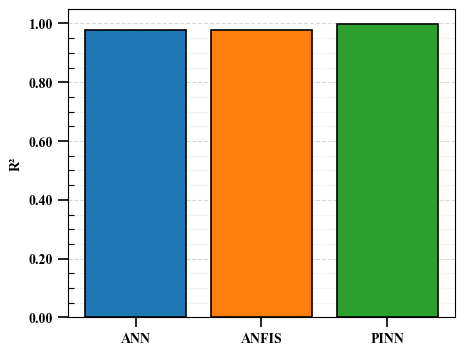

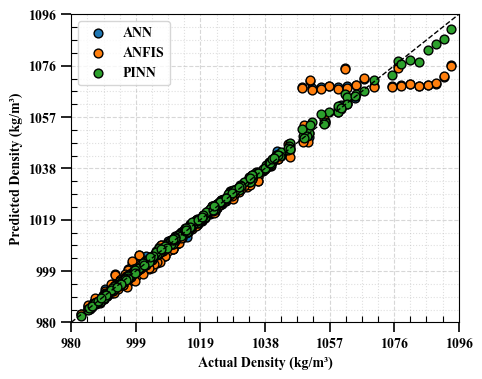


Done - metrics and plots are based on TRAINING data only


In [2]:
# =========================================================
# ANN vs ANFIS vs PINN - TRAINING SET EVALUATION
# Hybrid Nanofluid Density Prediction
# Figure Format Matched with Previous Style
# Grid Behind Plots
# =========================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from matplotlib.ticker import AutoMinorLocator, FormatStrFormatter
from tensorflow.keras import layers, Model

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# =========================================================
# Reproducibility
# =========================================================
np.random.seed(42)
tf.random.set_seed(42)

# =========================================================
# Font
# =========================================================
plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["font.weight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["axes.titleweight"] = "bold"

# =========================================================
# Desktop Path
# =========================================================
desktop_path = os.path.join(
    os.path.expanduser("~"),
    "Desktop"
)

# =========================================================
# Read Dataset
# =========================================================
df = pd.read_csv("Density_Prediction_Dataset.csv")

# =========================================================
# Rename Columns
# =========================================================
df.columns = [
    "NanoParticle",
    "BaseFluid",
    "Temperature",
    "VolumeConcentration",
    "rho_np1",
    "rho_np2",
    "rho_bf",
    "phi1",
    "phi2",
    "Density"
]

# =========================================================
# Numeric Conversion
# =========================================================
numeric_cols = [
    "Temperature",
    "VolumeConcentration",
    "rho_np1",
    "rho_np2",
    "rho_bf",
    "phi1",
    "phi2",
    "Density"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

# =========================================================
# Convert phi from Percentage to Fraction
# =========================================================
df["phi1"] = df["phi1"] / 100
df["phi2"] = df["phi2"] / 100

# =========================================================
# Remove Missing Values
# =========================================================
df = df.dropna()

# =========================================================
# Physics Equation
# =========================================================
df["rho_physics"] = (
    df["phi1"] * df["rho_np1"]
    + df["phi2"] * df["rho_np2"]
    + (1 - df["phi1"] - df["phi2"]) * df["rho_bf"]
)

print(df[["phi1", "phi2", "Density", "rho_physics"]].head())

# =========================================================
# Inputs and Output
# =========================================================
X = df[
    [
        "NanoParticle",
        "BaseFluid",
        "Temperature",
        "VolumeConcentration",
        "phi1",
        "phi2"
    ]
]

y = df["Density"].values.reshape(-1, 1)
rho_physics = df["rho_physics"].values.reshape(-1, 1)

# =========================================================
# Preprocessing
# =========================================================
categorical_cols = [
    "NanoParticle",
    "BaseFluid"
]

numerical_cols = [
    "Temperature",
    "VolumeConcentration",
    "phi1",
    "phi2"
]

preprocessor = ColumnTransformer([
    (
        "num",
        StandardScaler(),
        numerical_cols
    ),
    (
        "cat",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_cols
    )
])

X_processed = preprocessor.fit_transform(X)

if hasattr(X_processed, "toarray"):
    X_processed = X_processed.toarray()

# =========================================================
# Scale Target and Physics Target
# =========================================================
y_scaler = StandardScaler()

y_scaled = y_scaler.fit_transform(y)
rho_physics_scaled = y_scaler.transform(rho_physics)

# =========================================================
# Train-Test Split
# =========================================================
X_train, X_test, y_train, y_test, phy_train, phy_test = train_test_split(
    X_processed,
    y_scaled,
    rho_physics_scaled,
    test_size=0.20,
    random_state=42
)

# =========================================================
# Tensor Conversion
# =========================================================
X_train_tf = tf.convert_to_tensor(
    X_train,
    dtype=tf.float32
)

X_test_tf = tf.convert_to_tensor(
    X_test,
    dtype=tf.float32
)

y_train_tf = tf.convert_to_tensor(
    y_train,
    dtype=tf.float32
)

phy_train_tf = tf.convert_to_tensor(
    phy_train,
    dtype=tf.float32
)

# =========================================================
# Loss
# =========================================================
huber = tf.keras.losses.Huber()

# =========================================================
# ANN Model
# =========================================================
class ANN(Model):

    def __init__(self):
        super(ANN, self).__init__()

        self.hidden1 = layers.Dense(
            32,
            activation="tanh"
        )

        self.hidden2 = layers.Dense(
            16,
            activation="tanh"
        )

        self.output_layer = layers.Dense(1)

    def call(self, x, training=False):

        x = self.hidden1(x)
        x = self.hidden2(x)

        return self.output_layer(x)

# =========================================================
# ANFIS Model
# =========================================================
class ANFIS(Model):

    def __init__(self, input_dim, n_rules=12):
        super(ANFIS, self).__init__()

        self.input_dim = input_dim
        self.n_rules = n_rules

        self.centers = self.add_weight(
            shape=(input_dim, n_rules),
            initializer="random_normal",
            trainable=True,
            name="centers"
        )

        self.sigmas = self.add_weight(
            shape=(input_dim, n_rules),
            initializer="ones",
            trainable=True,
            name="sigmas"
        )

        self.consequents = self.add_weight(
            shape=(n_rules, input_dim),
            initializer="random_normal",
            trainable=True,
            name="consequents"
        )

        self.bias = self.add_weight(
            shape=(n_rules,),
            initializer="zeros",
            trainable=True,
            name="bias"
        )

    def call(self, x, training=False):

        x_expanded = tf.expand_dims(
            x,
            axis=2
        )

        centers = tf.expand_dims(
            self.centers,
            axis=0
        )

        sigmas = tf.nn.softplus(
            self.sigmas
        ) + 1e-6

        sigmas = tf.expand_dims(
            sigmas,
            axis=0
        )

        membership = tf.exp(
            -0.5 * tf.square(
                (x_expanded - centers) / sigmas
            )
        )

        firing_strength = tf.reduce_prod(
            membership,
            axis=1
        )

        firing_sum = tf.reduce_sum(
            firing_strength,
            axis=1,
            keepdims=True
        ) + 1e-6

        normalized_firing = firing_strength / firing_sum

        rule_outputs = tf.matmul(
            x,
            self.consequents,
            transpose_b=True
        ) + self.bias

        output = tf.reduce_sum(
            normalized_firing * rule_outputs,
            axis=1,
            keepdims=True
        )

        return output

# =========================================================
# PINN Model
# =========================================================
class PINN(Model):

    def __init__(self):
        super(PINN, self).__init__()

        self.hidden1 = layers.Dense(
            64,
            activation="tanh"
        )

        self.hidden2 = layers.Dense(
            32,
            activation="tanh"
        )

        self.hidden3 = layers.Dense(
            16,
            activation="tanh"
        )

        self.output_layer = layers.Dense(1)

    def call(self, x, training=False):

        x = self.hidden1(x)
        x = self.hidden2(x)
        x = self.hidden3(x)

        return self.output_layer(x)

# =========================================================
# Training Function for ANN and ANFIS
# =========================================================
def train_standard_model(model, model_name):

    optimizer = tf.keras.optimizers.Adam(
        learning_rate=0.001
    )

    epochs = 1500
    history = []

    @tf.function
    def train_step(x, y_true):

        with tf.GradientTape() as tape:

            y_pred = model(
                x,
                training=True
            )

            loss = huber(
                y_true,
                y_pred
            )

        gradients = tape.gradient(
            loss,
            model.trainable_variables
        )

        optimizer.apply_gradients(
            zip(
                gradients,
                model.trainable_variables
            )
        )

        return loss

    for epoch in range(epochs):

        loss = train_step(
            X_train_tf,
            y_train_tf
        )

        history.append(loss.numpy())

        if epoch % 300 == 0:
            print(
                f"{model_name} Epoch {epoch} | Loss = {loss.numpy():.6f}"
            )

    return history

# =========================================================
# Training Function for PINN
# =========================================================
def train_pinn_model(model):

    optimizer = tf.keras.optimizers.Adam(
        learning_rate=0.01
    )

    lambda_phy = 0.0001
    epochs = 1500
    history = []

    @tf.function
    def train_step(x, y_true, rho_phy):

        with tf.GradientTape() as tape:

            y_pred = model(
                x,
                training=True
            )

            loss_data = huber(
                y_true,
                y_pred
            )

            loss_physics = huber(
                rho_phy,
                y_pred
            )

            loss_total = (
                loss_data
                + lambda_phy * loss_physics
            )

        gradients = tape.gradient(
            loss_total,
            model.trainable_variables
        )

        optimizer.apply_gradients(
            zip(
                gradients,
                model.trainable_variables
            )
        )

        return loss_total

    for epoch in range(epochs):

        loss = train_step(
            X_train_tf,
            y_train_tf,
            phy_train_tf
        )

        history.append(loss.numpy())

        if epoch % 300 == 0:
            print(
                f"PINN Epoch {epoch} | Loss = {loss.numpy():.6f}"
            )

    return history

# =========================================================
# Build and Train Models
# =========================================================
input_dim = X_train.shape[1]

ann = ANN()

anfis = ANFIS(
    input_dim=input_dim,
    n_rules=12
)

pinn = PINN()

history_ann = train_standard_model(
    ann,
    "ANN"
)

history_anfis = train_standard_model(
    anfis,
    "ANFIS"
)

history_pinn = train_pinn_model(
    pinn
)

# =========================================================
# Prediction Function
# =========================================================
def predict_model(model):

    y_pred_scaled = model(
        X_train_tf,
        training=False
    ).numpy()

    y_pred = y_scaler.inverse_transform(
        y_pred_scaled
    )

    return y_pred

# =========================================================
# Predictions
# =========================================================
y_train_true = y_scaler.inverse_transform(
    y_train
)

pred_ann = predict_model(ann)
pred_anfis = predict_model(anfis)
pred_pinn = predict_model(pinn)

predictions = {
    "ANN": pred_ann,
    "ANFIS": pred_anfis,
    "PINN": pred_pinn
}

colors = {
    "ANN": "#1f77b4",
    "ANFIS": "#ff7f0e",
    "PINN": "#2ca02c"
}

# =========================================================
# Metrics Function
# =========================================================
def get_metrics(y_true, y_pred):

    r2 = r2_score(
        y_true,
        y_pred
    )

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    return r2, mae, rmse

ann_metrics = get_metrics(
    y_train_true,
    pred_ann
)

anfis_metrics = get_metrics(
    y_train_true,
    pred_anfis
)

pinn_metrics = get_metrics(
    y_train_true,
    pred_pinn
)

# =========================================================
# Comparison Table
# =========================================================
results_df = pd.DataFrame({

    "Model": [
        "ANN",
        "ANFIS",
        "PINN"
    ],

    "R2": [
        ann_metrics[0],
        anfis_metrics[0],
        pinn_metrics[0]
    ],

    "MAE": [
        ann_metrics[1],
        anfis_metrics[1],
        pinn_metrics[1]
    ],

    "RMSE": [
        ann_metrics[2],
        anfis_metrics[2],
        pinn_metrics[2]
    ]

})

print("\nTRAINING SET Comparison Results")
print(results_df)

# =========================================================
# Save Results
# =========================================================
results_df.to_excel(
    os.path.join(
        desktop_path,
        "ANN_ANFIS_PINN_TRAIN_Comparison.xlsx"
    ),
    index=False
)

# =========================================================
# Save Predictions
# =========================================================
predictions_df = pd.DataFrame({

    "Actual Density":
        y_train_true.flatten(),

    "ANN Prediction":
        pred_ann.flatten(),

    "ANFIS Prediction":
        pred_anfis.flatten(),

    "PINN Prediction":
        pred_pinn.flatten()

})

predictions_df.to_excel(
    os.path.join(
        desktop_path,
        "ANN_ANFIS_PINN_TRAIN_Predictions.xlsx"
    ),
    index=False
)

# =========================================================
# Plot R2 Comparison
# =========================================================
fig, ax1 = plt.subplots(figsize=(5, 4))

ax1.set_axisbelow(True)

ax1.bar(
    results_df["Model"],
    results_df["R2"],
    color=[colors[m] for m in results_df["Model"]],
    edgecolor="black",
    linewidth=1.2,
    zorder=3
)

ax1.set_ylabel(
    "R²",
    fontweight="bold"
)

ax1.yaxis.set_major_formatter(
    FormatStrFormatter("%.2f")
)

ax1.yaxis.set_minor_locator(
    AutoMinorLocator(4)
)

ax1.tick_params(
    axis="x",
    which="major",
    direction="out",
    length=7,
    width=1.2
)

ax1.tick_params(
    axis="y",
    which="major",
    direction="out",
    length=7,
    width=1.2
)

ax1.tick_params(
    axis="y",
    which="minor",
    direction="in",
    length=4,
    width=0.8
)

for label in ax1.get_xticklabels():
    label.set_fontweight("bold")

for label in ax1.get_yticklabels():
    label.set_fontweight("bold")

ax1.grid(
    True,
    which="major",
    axis="y",
    linestyle="--",
    alpha=0.5,
    zorder=0
)

ax1.grid(
    True,
    which="minor",
    axis="y",
    linestyle=":",
    alpha=0.4,
    zorder=0
)

plt.savefig(
    os.path.join(
        desktop_path,
        "ANN_ANFIS_PINN_TRAIN_R2_Comparison.png"
    ),
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.1
)

plt.show()

# =========================================================
# Actual vs Predicted Plot
# =========================================================
fig, ax1 = plt.subplots(figsize=(5, 4))

ax1.set_axisbelow(True)

for name in predictions.keys():

    ax1.scatter(
        y_train_true,
        predictions[name],
        color=colors[name],
        edgecolor="black",
        label=name,
        s=40,
        zorder=3
    )

# =========================================================
# Axis Range
# =========================================================
y_min = 980

y_max = max(
    y_train_true.max(),
    max([predictions[m].max() for m in predictions])
) * 1.002

ax1.set_xlim(y_min, y_max)
ax1.set_ylim(y_min, y_max)

# =========================================================
# Ticks
# =========================================================
ticks = [
    y_min + i * (y_max - y_min) / 6
    for i in range(7)
]

ax1.set_xticks(ticks)
ax1.set_yticks(ticks)

ax1.plot(
    [y_min, y_max],
    [y_min, y_max],
    "k--",
    linewidth=1,
    zorder=3
)

ax1.set_xlabel(
    "Actual Density (kg/m³)",
    fontweight="bold"
)

ax1.set_ylabel(
    "Predicted Density (kg/m³)",
    fontweight="bold"
)

ax1.xaxis.set_major_formatter(
    FormatStrFormatter("%.0f")
)

ax1.yaxis.set_major_formatter(
    FormatStrFormatter("%.0f")
)

ax1.xaxis.set_minor_locator(
    AutoMinorLocator(4)
)

ax1.yaxis.set_minor_locator(
    AutoMinorLocator(4)
)

ax1.tick_params(
    axis="x",
    which="major",
    direction="out",
    length=7,
    width=1.2
)

ax1.tick_params(
    axis="x",
    which="minor",
    direction="in",
    length=4,
    width=0.8
)

ax1.tick_params(
    axis="y",
    which="major",
    direction="out",
    length=7,
    width=1.2
)

ax1.tick_params(
    axis="y",
    which="minor",
    direction="in",
    length=4,
    width=0.8
)

for label in ax1.get_xticklabels():
    label.set_fontweight("bold")

for label in ax1.get_yticklabels():
    label.set_fontweight("bold")

ax1.grid(
    True,
    which="major",
    linestyle="--",
    alpha=0.5,
    zorder=0
)

ax1.grid(
    True,
    which="minor",
    linestyle=":",
    alpha=0.4,
    zorder=0
)

ax1.legend(
    prop={
        "weight": "bold",
        "family": "Times New Roman"
    }
)

plt.savefig(
    os.path.join(
        desktop_path,
        "ANN_ANFIS_PINN_TRAIN_Actual_vs_Predicted.png"
    ),
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.1
)

plt.show()

print("\nDone - metrics and plots are based on TRAINING data only")

Dataset: C:\Users\masal\Density_Prediction_Dataset.csv
Output directory: C:\Users\masal\PINN_Lambda_Comparison_Results

Training PINN with Lambda = 0.0
Lambda=0 | Epoch=1 | Total Loss=0.435009
Lambda=0 | Epoch=300 | Total Loss=0.013291
Lambda=0 | Epoch=600 | Total Loss=0.011693
Lambda=0 | Epoch=900 | Total Loss=0.010718
Lambda=0 | Epoch=1200 | Total Loss=0.009305
Lambda=0 | Epoch=1500 | Total Loss=0.005986

Training PINN with Lambda = 0.001
Lambda=0.001 | Epoch=1 | Total Loss=0.584875
Lambda=0.001 | Epoch=300 | Total Loss=0.163049
Lambda=0.001 | Epoch=600 | Total Loss=0.161451
Lambda=0.001 | Epoch=900 | Total Loss=0.160476
Lambda=0.001 | Epoch=1200 | Total Loss=0.159065
Lambda=0.001 | Epoch=1500 | Total Loss=0.155213

Training PINN with Lambda = 0.01
Lambda=0.01 | Epoch=1 | Total Loss=1.933669
Lambda=0.01 | Epoch=300 | Total Loss=1.510823
Lambda=0.01 | Epoch=600 | Total Loss=1.509226
Lambda=0.01 | Epoch=900 | Total Loss=1.508255
Lambda=0.01 | Epoch=1200 | Total Loss=1.506860
Lambda=0.0

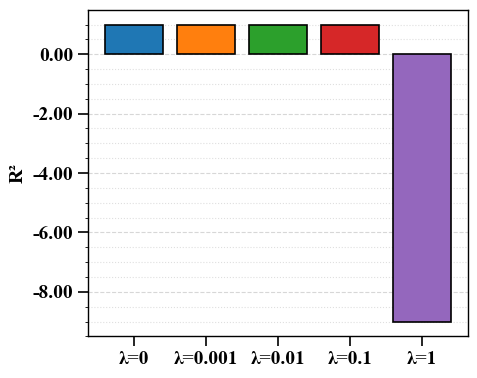

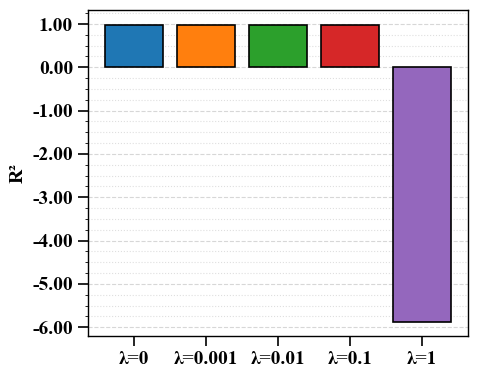

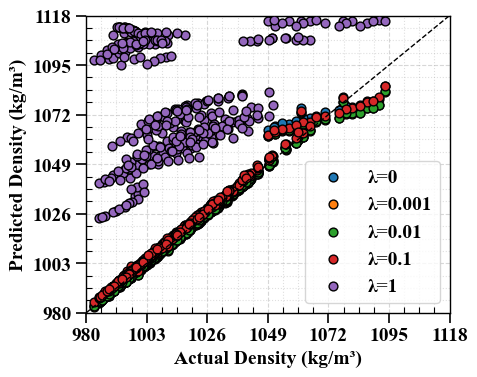

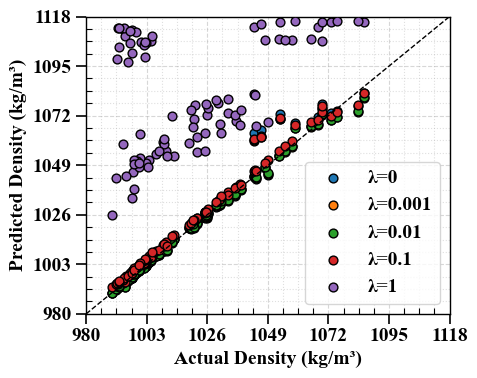


Done.
Results saved to: C:\Users\masal\PINN_Lambda_Comparison_Results


In [31]:

# =========================================================
# PINN ONLY — Hybrid Nanofluid Density Prediction
# Lambda comparison: 0, 0.001, 0.01, 0.1, 1
# Training + Testing Evaluation
# Jupyter Notebook Compatible
# =========================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from matplotlib.ticker import AutoMinorLocator, FormatStrFormatter
from tensorflow.keras import layers, Model
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# =========================================================
# Settings
# =========================================================

SEED = 42
EPOCHS = 1500
LEARNING_RATE = 0.001

LAMBDAS = [0.0, 0.001, 0.01, 0.1, 1.0]

np.random.seed(SEED)
tf.random.set_seed(SEED)

plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["font.weight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["axes.titleweight"] = "bold"

# =========================================================
# Paths — Jupyter Compatible
# =========================================================

working_dir = os.getcwd()

filename = os.path.join(
    working_dir,
    "Density_Prediction_Dataset.csv"
)

if not os.path.isfile(filename):
    raise FileNotFoundError(
        f"Dataset not found: {filename}"
    )

output_dir = os.path.join(
    working_dir,
    "PINN_Lambda_Comparison_Results"
)

os.makedirs(output_dir, exist_ok=True)

print("Dataset:", filename)
print("Output directory:", output_dir)

# =========================================================
# Read Dataset
# =========================================================

df = pd.read_csv(filename)

if len(df.columns) != 10:
    raise ValueError("Expected 10 dataset columns.")

df.columns = [
    "NanoParticle",
    "BaseFluid",
    "Temperature",
    "VolumeConcentration",
    "rho_np1",
    "rho_np2",
    "rho_bf",
    "phi1",
    "phi2",
    "Density"
]

numeric_cols = [
    "Temperature",
    "VolumeConcentration",
    "rho_np1",
    "rho_np2",
    "rho_bf",
    "phi1",
    "phi2",
    "Density"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

df = df.dropna().copy()

# =========================================================
# Convert Percentages to Fractions
# =========================================================

df["phi1"] = df["phi1"] / 100.0
df["phi2"] = df["phi2"] / 100.0

# =========================================================
# Physics Equation
# =========================================================

df["rho_physics"] = (
    df["phi1"] * df["rho_np1"]
    + df["phi2"] * df["rho_np2"]
    + (1 - df["phi1"] - df["phi2"]) * df["rho_bf"]
)

# =========================================================
# Inputs and Target
# =========================================================

X = df[
    [
        "NanoParticle",
        "BaseFluid",
        "Temperature",
        "VolumeConcentration",
        "phi1",
        "phi2"
    ]
]

y = df["Density"].values.reshape(-1, 1)

rho_physics = df["rho_physics"].values.reshape(-1, 1)

# =========================================================
# Train-Test Split
# =========================================================

indices = np.arange(len(df))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=SEED
)

# =========================================================
# Preprocessing
# =========================================================

try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

preprocessor = ColumnTransformer([
    (
        "num",
        StandardScaler(),
        [
            "Temperature",
            "VolumeConcentration",
            "phi1",
            "phi2"
        ]
    ),
    (
        "cat",
        encoder,
        ["NanoParticle", "BaseFluid"]
    )
])

X_train = preprocessor.fit_transform(
    X.iloc[train_idx]
)

X_test = preprocessor.transform(
    X.iloc[test_idx]
)

if hasattr(X_train, "toarray"):
    X_train = X_train.toarray()

if hasattr(X_test, "toarray"):
    X_test = X_test.toarray()

# =========================================================
# Target Scaling
# =========================================================

y_scaler = StandardScaler()

y_train = y_scaler.fit_transform(
    y[train_idx]
).astype("float32")

y_test = y_scaler.transform(
    y[test_idx]
).astype("float32")

phy_train = y_scaler.transform(
    rho_physics[train_idx]
).astype("float32")

# =========================================================
# Tensor Conversion
# =========================================================

X_train_tf = tf.constant(
    X_train,
    dtype=tf.float32
)

X_test_tf = tf.constant(
    X_test,
    dtype=tf.float32
)

y_train_tf = tf.constant(
    y_train,
    dtype=tf.float32
)

phy_train_tf = tf.constant(
    phy_train,
    dtype=tf.float32
)

huber = tf.keras.losses.Huber()

# =========================================================
# PINN Model — 64-32-16
# =========================================================

class PINN(Model):

    def __init__(self):
        super().__init__()

        self.hidden1 = layers.Dense(
            64,
            activation="tanh"
        )

        self.hidden2 = layers.Dense(
           32,
            activation="tanh"
        )

        self.hidden3 = layers.Dense(
           16,
            activation="tanh"
        )

        self.output_layer = layers.Dense(1)

    def call(self, x, training=False):

        x = self.hidden1(x)
        x = self.hidden2(x)
        x = self.hidden3(x)

        return self.output_layer(x)

# =========================================================
# Identical Initial Weights
# =========================================================

tf.keras.utils.set_random_seed(SEED)

reference_model = PINN()

_ = reference_model(X_train_tf[:1])

initial_weights = reference_model.get_weights()

# =========================================================
# PINN Training Function
# =========================================================

def train_pinn(model, lambda_phy):

    optimizer = tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    )

    history = []

    @tf.function
    def train_step():

        with tf.GradientTape() as tape:

            y_pred = model(
                X_train_tf,
                training=True
            )

            loss_data = huber(
                y_train_tf,
                y_pred
            )

            loss_physics = huber(
                phy_train_tf,
                y_pred
            )

            loss_total = (
                loss_data
                + lambda_phy * loss_physics
            )

        gradients = tape.gradient(
            loss_total,
            model.trainable_variables
        )

        optimizer.apply_gradients(
            zip(
                gradients,
                model.trainable_variables
            )
        )

        return loss_total, loss_data, loss_physics

    for epoch in range(EPOCHS):

        total, data, physics = train_step()

        history.append([
            epoch + 1,
            float(total),
            float(data),
            float(physics)
        ])

        if epoch == 0 or (epoch + 1) % 300 == 0:

            print(
                f"Lambda={lambda_phy:g} | "
                f"Epoch={epoch + 1} | "
                f"Total Loss={float(total):.6f}"
            )

    return history

# =========================================================
# Evaluation Metrics
# =========================================================

def calculate_metrics(y_true, y_pred):

    r2 = r2_score(y_true, y_pred)

    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    return {
        "R2": r2,
        "MAE": mae,
        "RMSE": rmse
    }

# =========================================================
# Train All Lambda Models
# =========================================================

results = []
predictions = {}
histories = []

for lam in LAMBDAS:

    print("\n" + "=" * 60)
    print(f"Training PINN with Lambda = {lam}")
    print("=" * 60)

    model = PINN()

    _ = model(X_train_tf[:1])

    model.set_weights(initial_weights)

    history = train_pinn(model, lam)

    for epoch, total, data, physics in history:

        histories.append({
            "Lambda": lam,
            "Epoch": epoch,
            "Total_Loss": total,
            "Data_Loss": data,
            "Physics_Loss": physics
        })

    for split, X_tensor, idx in [
        ("Train", X_train_tf, train_idx),
        ("Test", X_test_tf, test_idx)
    ]:

        actual = y[idx].flatten()

        pred_scaled = model(
            X_tensor,
            training=False
        ).numpy()

        predicted = y_scaler.inverse_transform(
            pred_scaled
        ).flatten()

        metric = calculate_metrics(
            actual,
            predicted
        )

        results.append({
            "Lambda": lam,
            "Set": split,
            **metric
        })

        if split not in predictions:

            predictions[split] = pd.DataFrame({
                "Row_Index": idx,
                "Actual_Density": actual
            })

        predictions[split][
            f"PINN_lambda_{lam:g}"
        ] = predicted

# =========================================================
# Results Table
# =========================================================

results_df = pd.DataFrame(results)

print("\nPINN Lambda Comparison Results")
print(results_df.to_string(index=False))

results_df.to_excel(
    os.path.join(
        output_dir,
        "PINN_Lambda_Metrics.xlsx"
    ),
    index=False
)

# =========================================================
# Save Predictions and Training History
# =========================================================

for split, table in predictions.items():

    table.to_excel(
        os.path.join(
            output_dir,
            f"PINN_Lambda_{split}_Predictions.xlsx"
        ),
        index=False
    )

pd.DataFrame(histories).to_csv(
    os.path.join(
        output_dir,
        "PINN_Lambda_Training_History.csv"
    ),
    index=False
)

# =========================================================
# Plot Settings
# =========================================================

colors = [
    "#1f77b4",
    "#ff7f0e",
    "#2ca02c",
    "#d62728",
    "#9467bd"
]

labels = [f"λ={lam:g}" for lam in LAMBDAS]

# =========================================================
# R2 Comparison — Training and Testing
# =========================================================

for split in ["Train", "Test"]:

    subset = (
        results_df[results_df["Set"] == split]
        .set_index("Lambda")
        .loc[LAMBDAS]
    )

    fig, ax = plt.subplots(figsize=(5, 4))

    ax.set_axisbelow(True)

    ax.bar(
        labels,
        subset["R2"],
        color=colors,
        edgecolor="black",
        linewidth=1.2,
        zorder=3
    )

    ax.set_ylabel(
        "R²",
        fontweight="bold"
    )

    ax.yaxis.set_major_formatter(
        FormatStrFormatter("%.2f")
    )

    ax.yaxis.set_minor_locator(
        AutoMinorLocator(4)
    )

    ax.grid(
        True,
        axis="y",
        which="major",
        linestyle="--",
        alpha=0.5,
        zorder=0
    )

    ax.grid(
        True,
        axis="y",
        which="minor",
        linestyle=":",
        alpha=0.4,
        zorder=0
    )

    ax.tick_params(
        axis="both",
        which="major",
        direction="out",
        length=7,
        width=1.2
    )

    for tick in ax.get_xticklabels() + ax.get_yticklabels():
        tick.set_fontweight("bold")

    fig.tight_layout()

    plt.savefig(
        os.path.join(
            output_dir,
            f"PINN_Lambda_{split}_R2_Comparison.png"
        ),
        dpi=300,
        bbox_inches="tight",
        pad_inches=0.1
    )

    plt.show()

# =========================================================
# Actual vs Predicted — Training and Testing
# =========================================================

for split in ["Train", "Test"]:

    table = predictions[split]

    fig, ax = plt.subplots(figsize=(5, 4))

    ax.set_axisbelow(True)

    for lam, color in zip(LAMBDAS, colors):

        ax.scatter(
            table["Actual_Density"],
            table[f"PINN_lambda_{lam:g}"],
            color=color,
            edgecolor="black",
            s=40,
            label=f"λ={lam:g}",
            zorder=3
        )

    all_values = np.concatenate(
        [table["Actual_Density"].to_numpy()]
        + [
            table[f"PINN_lambda_{lam:g}"].to_numpy()
            for lam in LAMBDAS
        ]
    )

    y_min = min(
        980.0,
        float(all_values.min()) - 1
    )

    y_max = float(all_values.max()) * 1.002

    ax.set_xlim(y_min, y_max)
    ax.set_ylim(y_min, y_max)

    ticks = np.linspace(y_min, y_max, 7)

    ax.set_xticks(ticks)
    ax.set_yticks(ticks)

    ax.plot(
        [y_min, y_max],
        [y_min, y_max],
        "k--",
        linewidth=1,
        zorder=3
    )

    ax.set_xlabel(
        "Actual Density (kg/m³)",
        fontweight="bold"
    )

    ax.set_ylabel(
        "Predicted Density (kg/m³)",
        fontweight="bold"
    )

    ax.xaxis.set_major_formatter(
        FormatStrFormatter("%.0f")
    )

    ax.yaxis.set_major_formatter(
        FormatStrFormatter("%.0f")
    )

    ax.xaxis.set_minor_locator(
        AutoMinorLocator(4)
    )

    ax.yaxis.set_minor_locator(
        AutoMinorLocator(4)
    )

    ax.tick_params(
        axis="both",
        which="major",
        direction="out",
        length=7,
        width=1.2
    )

    ax.tick_params(
        axis="both",
        which="minor",
        direction="in",
        length=4,
        width=0.8
    )

    ax.grid(
        True,
        which="major",
        linestyle="--",
        alpha=0.5,
        zorder=0
    )

    ax.grid(
        True,
        which="minor",
        linestyle=":",
        alpha=0.4,
        zorder=0
    )

    ax.legend(
        prop={
            "weight": "bold",
            "family": "Times New Roman"
        }
    )

    fig.tight_layout()

    plt.savefig(
        os.path.join(
            output_dir,
            f"PINN_Lambda_{split}_Actual_vs_Predicted.png"
        ),
        dpi=300,
        bbox_inches="tight",
        pad_inches=0.1
    )

    plt.show()

print("\nDone.")
print("Results saved to:", output_dir)



lambda=0 | epoch=   1 | total=0.311057 | data=0.311057 | physics=149.915771
lambda=0 | epoch= 300 | total=0.012402 | data=0.012402 | physics=149.757584
lambda=0 | epoch= 600 | total=0.011362 | data=0.011362 | physics=149.757538
lambda=0 | epoch= 900 | total=0.010501 | data=0.010501 | physics=149.757584
lambda=0 | epoch=1200 | total=0.008595 | data=0.008595 | physics=149.762817
lambda=0 | epoch=1500 | total=0.003575 | data=0.003575 | physics=149.745773
lambda=0.001 | epoch=   1 | total=0.460973 | data=0.311057 | physics=149.915771
lambda=0.001 | epoch= 300 | total=0.162158 | data=0.012401 | physics=149.756607
lambda=0.001 | epoch= 600 | total=0.161119 | data=0.011363 | physics=149.756531
lambda=0.001 | epoch= 900 | total=0.160256 | data=0.010499 | physics=149.756577
lambda=0.001 | epoch=1200 | total=0.158031 | data=0.008277 | physics=149.754532
lambda=0.001 | epoch=1500 | total=0.152833 | data=0.003068 | physics=149.765305
lambda=0.01 | epoch=   1 | total=1.810215 | data=0.311057 | phy

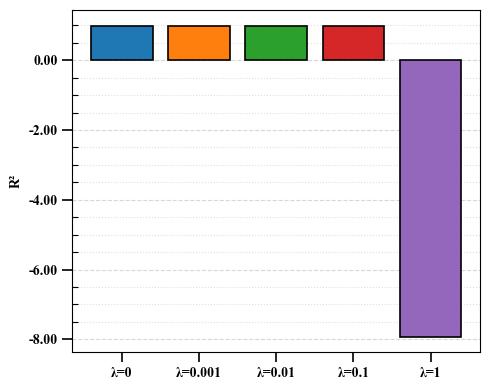

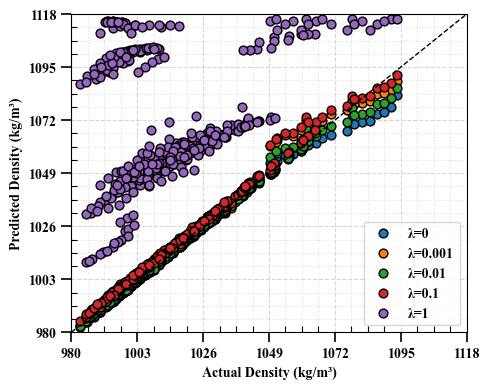

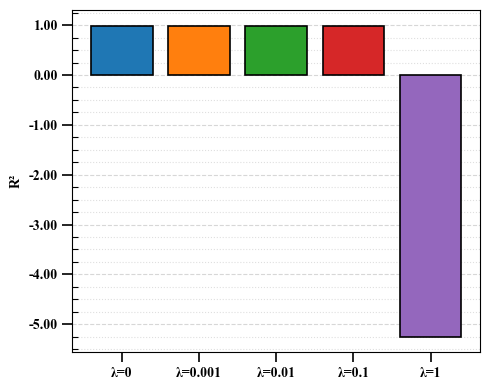

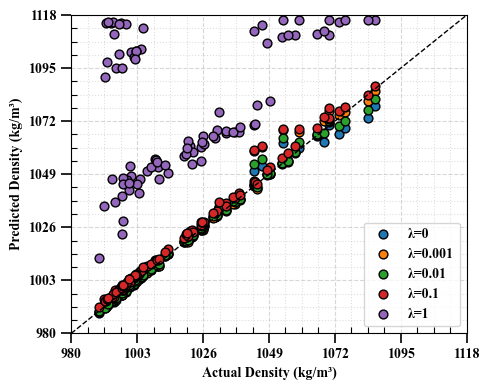


Done. Saved results to: C:\Users\masal\PINN_Lambda_Comparison_Results
NOTE: Choose lambda using validation data, not the final test results.


In [5]:
# =========================================================
# PINN ONLY — Hybrid Nanofluid Density Prediction
# Lambda physics comparison: 0, 0.001, 0.01, 0.1, 1
# Same PINN architecture, Huber loss, 1500 epochs and figures
# as the supplied script. Training and testing metrics saved.
# =========================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from matplotlib.ticker import AutoMinorLocator, FormatStrFormatter
from tensorflow.keras import layers, Model
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

SEED = 42
EPOCHS = 1500
LEARNING_RATE = 0.001
LAMBDAS = [0.0, 0.001, 0.01, 0.1, 1.0]
np.random.seed(SEED)
tf.random.set_seed(SEED)
plt.rcParams.update({"font.family":"Times New Roman", "font.weight":"bold",
                     "axes.labelweight":"bold", "axes.titleweight":"bold"})

# Dataset can be in the current working directory or beside this script.
filename = 'Density_Prediction_Dataset.csv'
if not os.path.isfile(filename):
    filename = os.path.join(os.path.dirname(os.path.abspath(__file__)) if '__file__' in globals() else os.getcwd(), filename)
if not os.path.isfile(filename):
    raise FileNotFoundError('Place Density_Prediction_Dataset.csv beside this script or in the working directory.')

# Save beside the script, avoiding overwriting the original comparison outputs.
output_dir = os.path.join(os.path.dirname(os.path.abspath(__file__)) if '__file__' in globals() else os.getcwd(), 'PINN_Lambda_Comparison_Results')
os.makedirs(output_dir, exist_ok=True)

df = pd.read_csv(filename)
if len(df.columns) != 10:
    raise ValueError('Expected the same 10 columns as the supplied original script.')
df.columns = ['NanoParticle','BaseFluid','Temperature','VolumeConcentration',
              'rho_np1','rho_np2','rho_bf','phi1','phi2','Density']
for col in ['Temperature','VolumeConcentration','rho_np1','rho_np2','rho_bf','phi1','phi2','Density']:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df = df.dropna().copy()
# Preserve the supplied code's assumption that phi1 and phi2 are percentages.
df['phi1'] /= 100.0
df['phi2'] /= 100.0
df['rho_physics'] = (df['phi1'] * df['rho_np1'] + df['phi2'] * df['rho_np2']
                     + (1.0 - df['phi1'] - df['phi2']) * df['rho_bf'])

X = df[['NanoParticle','BaseFluid','Temperature','VolumeConcentration','phi1','phi2']]
y = df['Density'].to_numpy().reshape(-1,1)
physics = df['rho_physics'].to_numpy().reshape(-1,1)
indices = np.arange(len(df))
train_idx, test_idx = train_test_split(indices, test_size=0.20, random_state=SEED)

# Important correction: fit scalers and encoders only on training data.
try:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), ['Temperature','VolumeConcentration','phi1','phi2']),
    ('cat', encoder, ['NanoParticle','BaseFluid'])
])
X_train = preprocessor.fit_transform(X.iloc[train_idx])
X_test = preprocessor.transform(X.iloc[test_idx])
if hasattr(X_train,'toarray'): X_train = X_train.toarray()
if hasattr(X_test,'toarray'): X_test = X_test.toarray()
y_scaler = StandardScaler().fit(y[train_idx])
y_train = y_scaler.transform(y[train_idx]).astype('float32')
y_test = y_scaler.transform(y[test_idx]).astype('float32')
phy_train = y_scaler.transform(physics[train_idx]).astype('float32')
X_train_tf = tf.constant(X_train, dtype=tf.float32)
X_test_tf = tf.constant(X_test, dtype=tf.float32)
y_train_tf = tf.constant(y_train)
phy_train_tf = tf.constant(phy_train)
huber = tf.keras.losses.Huber()

class PINN(Model):
    def __init__(self):
        super().__init__()
        self.hidden1 = layers.Dense(64, activation='tanh')
        self.hidden2 = layers.Dense(64, activation='tanh')
        self.hidden3 = layers.Dense(16, activation='tanh')
        self.output_layer = layers.Dense(1)
    def call(self, x, training=False):
        x = self.hidden1(x)
        x = self.hidden2(x)
        x = self.hidden3(x)
        return self.output_layer(x)

# Identical initial weights for all lambda values (controlled comparison).
tf.keras.utils.set_random_seed(SEED)
reference = PINN()
_ = reference(X_train_tf[:1])
initial_weights = reference.get_weights()

def fit_model(model, lam):
    optimizer = tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE)
    history = []
    @tf.function
    def train_step():
        with tf.GradientTape() as tape:
            pred = model(X_train_tf, training=True)
            loss_data = huber(y_train_tf, pred)
            loss_physics = huber(phy_train_tf, pred)
            loss = loss_data + tf.cast(lam,tf.float32)*loss_physics
        gradients = tape.gradient(loss, model.trainable_variables)
        optimizer.apply_gradients(zip(gradients, model.trainable_variables))
        return loss, loss_data, loss_physics
    for epoch in range(EPOCHS):
        total, data, physical = train_step()
        history.append([epoch+1, float(total), float(data), float(physical)])
        if epoch == 0 or (epoch+1)%300 == 0:
            print(f'lambda={lam:g} | epoch={epoch+1:4d} | total={float(total):.6f} | data={float(data):.6f} | physics={float(physical):.6f}')
    return history

def metrics(actual, predicted):
    return {'R2': r2_score(actual, predicted),
            'MAE': mean_absolute_error(actual, predicted),
            'RMSE': np.sqrt(mean_squared_error(actual, predicted))}

rows = []
prediction_tables = {}
history_rows = []
for lam in LAMBDAS:
    tf.keras.backend.clear_session()
    model = PINN()
    _ = model(X_train_tf[:1])
    model.set_weights(initial_weights)
    hist = fit_model(model, lam)
    for epoch, total, data, physical in hist:
        history_rows.append({'Lambda':lam,'Epoch':epoch,'Total_Loss':total,'Data_Loss':data,'Physics_Loss':physical})
    for split, xx, ii in [('Train', X_train_tf, train_idx), ('Test', X_test_tf, test_idx)]:
        actual = y[ii].flatten()
        predicted = y_scaler.inverse_transform(model(xx, training=False).numpy()).flatten()
        rows.append({'Lambda':lam,'Set':split,**metrics(actual,predicted)})
        prediction_tables.setdefault(split, pd.DataFrame({'Row_Index':ii, 'Actual_Density':actual}))
        prediction_tables[split][f'PINN_lambda_{lam:g}'] = predicted

results = pd.DataFrame(rows)
print('\nPINN lambda comparison (training and testing):\n',results.to_string(index=False))
results.to_excel(os.path.join(output_dir,'PINN_Lambda_Metrics.xlsx'), index=False)
# Wide comparison table: one row per lambda, train/test side by side.
comparison = results.pivot(index='Lambda', columns='Set', values=['R2','MAE','RMSE'])
comparison = comparison.reindex(columns=pd.MultiIndex.from_tuples([
    ('R2','Train'), ('MAE','Train'), ('RMSE','Train'),
    ('R2','Test'), ('MAE','Test'), ('RMSE','Test')
]))
comparison.columns = ['Train_R2','Train_MAE','Train_RMSE',
                      'Test_R2','Test_MAE','Test_RMSE']
comparison = comparison.reset_index()
print('\n' + '='*85)
print('PINN LAMBDA COMPARISON RESULTS — TRAIN VS TEST')
print('='*85)
print(comparison.to_string(index=False, float_format=lambda v: f'{v:.6f}'))
comparison.to_excel(os.path.join(output_dir, 'PINN_Lambda_Comparison_Table.xlsx'), index=False)
comparison.to_csv(os.path.join(output_dir, 'PINN_Lambda_Comparison_Table.csv'), index=False)

for split, table in prediction_tables.items():
    table.to_excel(os.path.join(output_dir,f'PINN_Lambda_{split}_Predictions.xlsx'), index=False)
pd.DataFrame(history_rows).to_csv(os.path.join(output_dir,'PINN_Lambda_Training_History.csv'), index=False)

# Match original plotting style: 5 x 4 inches, black edges, grid behind, 300 dpi.
colors = ['#1f77b4','#ff7f0e','#2ca02c','#d62728','#9467bd']
labels = [f'λ={v:g}' for v in LAMBDAS]
for split in ['Train','Test']:
    subset = results[results['Set']==split].set_index('Lambda').loc[LAMBDAS]
    fig, ax = plt.subplots(figsize=(5,4))
    ax.set_axisbelow(True)
    ax.bar(labels, subset['R2'], color=colors, edgecolor='black', linewidth=1.2, zorder=3)
    ax.set_ylabel('R²',fontweight='bold')
    ax.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))
    ax.yaxis.set_minor_locator(AutoMinorLocator(4))
    ax.grid(True,axis='y',which='major',linestyle='--',alpha=0.5,zorder=0)
    ax.grid(True,axis='y',which='minor',linestyle=':',alpha=0.4,zorder=0)
    ax.tick_params(axis='both',which='major',direction='out',length=7,width=1.2)
    ax.tick_params(axis='y',which='minor',direction='in',length=4,width=0.8)
    for tick in ax.get_xticklabels()+ax.get_yticklabels(): tick.set_fontweight('bold')
    fig.tight_layout()
    fig.savefig(os.path.join(output_dir,f'PINN_Lambda_{split}_R2_Comparison.png'),dpi=300,bbox_inches='tight',pad_inches=0.1)
    plt.show()

    table = prediction_tables[split]
    fig, ax = plt.subplots(figsize=(5,4))
    ax.set_axisbelow(True)
    for lam, color in zip(LAMBDAS, colors):
        ax.scatter(table['Actual_Density'], table[f'PINN_lambda_{lam:g}'],
                   color=color,edgecolor='black',s=40,label=f'λ={lam:g}',zorder=3)
    all_values = np.concatenate([table['Actual_Density'].to_numpy()] +
                                [table[f'PINN_lambda_{lam:g}'].to_numpy() for lam in LAMBDAS])
    lower = min(980.0, float(all_values.min())-1)
    upper = float(all_values.max())*1.002
    ax.set_xlim(lower,upper)
    ax.set_ylim(lower,upper)
    ticks = np.linspace(lower,upper,7)
    ax.set_xticks(ticks); ax.set_yticks(ticks)
    ax.plot([lower,upper],[lower,upper],'k--',linewidth=1,zorder=3)
    ax.set_xlabel('Actual Density (kg/m³)',fontweight='bold')
    ax.set_ylabel('Predicted Density (kg/m³)',fontweight='bold')
    ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))
    ax.yaxis.set_major_formatter(FormatStrFormatter('%.0f'))
    ax.xaxis.set_minor_locator(AutoMinorLocator(4))
    ax.yaxis.set_minor_locator(AutoMinorLocator(4))
    ax.tick_params(axis='both',which='major',direction='out',length=7,width=1.2)
    ax.tick_params(axis='both',which='minor',direction='in',length=4,width=0.8)
    ax.grid(True,which='major',linestyle='--',alpha=0.5,zorder=0)
    ax.grid(True,which='minor',linestyle=':',alpha=0.4,zorder=0)
    for tick in ax.get_xticklabels()+ax.get_yticklabels(): tick.set_fontweight('bold')
    ax.legend(prop={'weight':'bold','family':'Times New Roman'})
    fig.tight_layout()
    fig.savefig(os.path.join(output_dir,f'PINN_Lambda_{split}_Actual_vs_Predicted.png'),dpi=300,bbox_inches='tight',pad_inches=0.1)
    plt.show()

print('\nDone. Saved results to:', output_dir)
print('NOTE: Choose lambda using validation data, not the final test results.')



Training common architecture, lambda = 0
Lambda=0 Epoch=1 Total=0.435009
Lambda=0 Epoch=300 Total=0.013291
Lambda=0 Epoch=600 Total=0.011693
Lambda=0 Epoch=900 Total=0.010718
Lambda=0 Epoch=1200 Total=0.009305
Lambda=0 Epoch=1500 Total=0.005986

Training common architecture, lambda = 0.001
Lambda=0.001 Epoch=1 Total=0.584875
Lambda=0.001 Epoch=300 Total=0.163049
Lambda=0.001 Epoch=600 Total=0.161451
Lambda=0.001 Epoch=900 Total=0.160476
Lambda=0.001 Epoch=1200 Total=0.159065
Lambda=0.001 Epoch=1500 Total=0.155213

Training common architecture, lambda = 0.01
Lambda=0.01 Epoch=1 Total=1.933669
Lambda=0.01 Epoch=300 Total=1.510823
Lambda=0.01 Epoch=600 Total=1.509226
Lambda=0.01 Epoch=900 Total=1.508255
Lambda=0.01 Epoch=1200 Total=1.506860
Lambda=0.01 Epoch=1500 Total=1.503055

Training common architecture, lambda = 0.1
Lambda=0.1 Epoch=1 Total=15.421607
Lambda=0.1 Epoch=300 Total=14.984126
Lambda=0.1 Epoch=600 Total=14.982480
Lambda=0.1 Epoch=900 Total=14.981523
Lambda=0.1 Epoch=1200 T

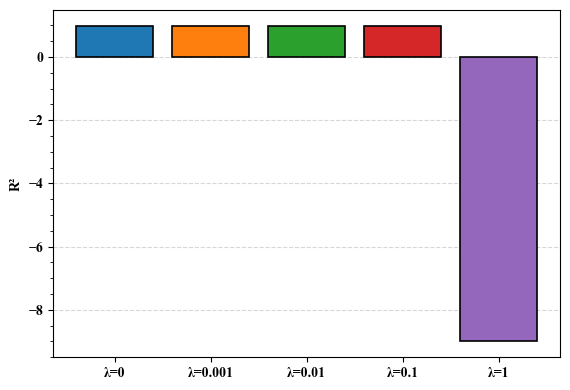

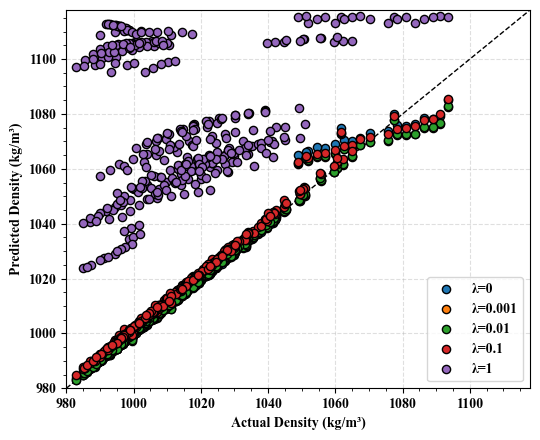

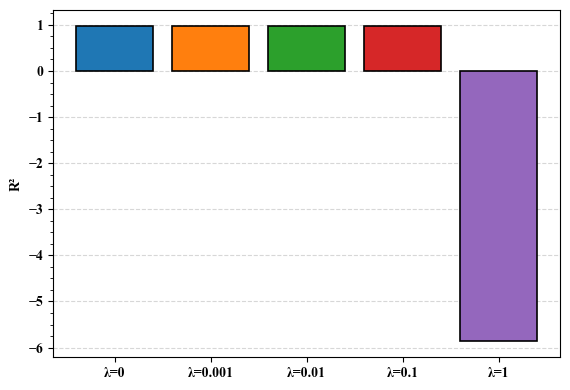

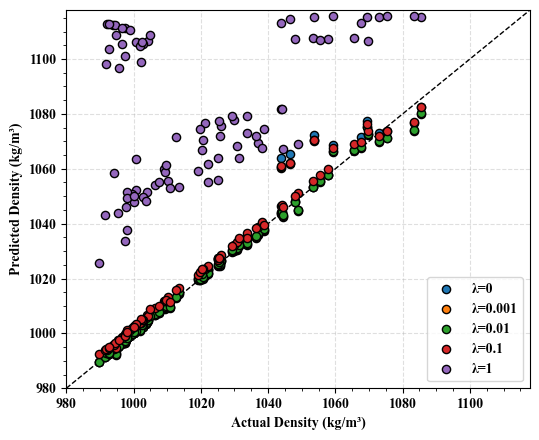


DONE. Results saved to: C:\Users\masal\ANN_PINN_Fair_Lambda_Results
ANN and PINN(lambda=0) are the same model and therefore share identical metrics.


In [9]:
# ============================================================
# FAIR ANN vs PINN comparison — Hybrid Nanofluid Density
# ANN and PINN use IDENTICAL architecture (64-32-16),
# initial weights, data split, preprocessing, and optimizer.
# PINN lambda=0 is exactly the ANN baseline.
# ============================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, Model
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from matplotlib.ticker import AutoMinorLocator

SEED = 42
EPOCHS = 1500
LR = 0.001
LAMBDAS = [0.0, 0.001, 0.01, 0.1, 1.0]
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

plt.rcParams.update({
    'font.family': 'Times New Roman',
    'font.weight': 'bold',
    'axes.labelweight': 'bold',
    'axes.titleweight': 'bold'
})

# Works in Jupyter Notebook and as a standalone script.
working_dir = os.getcwd()
csv_path = os.path.join(working_dir, 'Density_Prediction_Dataset.csv')
if not os.path.isfile(csv_path):
    raise FileNotFoundError(f'Dataset not found: {csv_path}')
output_dir = os.path.join(working_dir, 'ANN_PINN_Fair_Lambda_Results')
os.makedirs(output_dir, exist_ok=True)

df = pd.read_csv(csv_path)
if df.shape[1] != 10:
    raise ValueError('The dataset must contain exactly 10 columns.')
df.columns = [
    'NanoParticle', 'BaseFluid', 'Temperature', 'VolumeConcentration',
    'rho_np1', 'rho_np2', 'rho_bf', 'phi1', 'phi2', 'Density'
]
num_cols = [
    'Temperature', 'VolumeConcentration', 'rho_np1', 'rho_np2',
    'rho_bf', 'phi1', 'phi2', 'Density'
]
for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df = df.dropna().copy()
df['phi1'] /= 100.0
df['phi2'] /= 100.0
df['rho_physics'] = (
    df['phi1'] * df['rho_np1'] + df['phi2'] * df['rho_np2']
    + (1.0 - df['phi1'] - df['phi2']) * df['rho_bf']
)

features = ['NanoParticle', 'BaseFluid', 'Temperature',
            'VolumeConcentration', 'phi1', 'phi2']
X = df[features]
y = df['Density'].to_numpy().reshape(-1, 1)
rho_phy = df['rho_physics'].to_numpy().reshape(-1, 1)
indices = np.arange(len(df))
train_idx, test_idx = train_test_split(indices, test_size=0.20, random_state=SEED)

try:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), ['Temperature', 'VolumeConcentration', 'phi1', 'phi2']),
    ('cat', encoder, ['NanoParticle', 'BaseFluid'])
])
X_train = preprocessor.fit_transform(X.iloc[train_idx])
X_test = preprocessor.transform(X.iloc[test_idx])
if hasattr(X_train, 'toarray'):
    X_train = X_train.toarray()
if hasattr(X_test, 'toarray'):
    X_test = X_test.toarray()
X_train_tf = tf.convert_to_tensor(X_train, dtype=tf.float32)
X_test_tf = tf.convert_to_tensor(X_test, dtype=tf.float32)

y_scaler = StandardScaler()
y_train = y_scaler.fit_transform(y[train_idx]).astype('float32')
y_test = y_scaler.transform(y[test_idx]).astype('float32')
phy_train = y_scaler.transform(rho_phy[train_idx]).astype('float32')
y_train_tf = tf.convert_to_tensor(y_train)
phy_train_tf = tf.convert_to_tensor(phy_train)
huber = tf.keras.losses.Huber()

class DensityNetwork(Model):
    """Same architecture for ANN and every PINN lambda."""
    def __init__(self):
        super().__init__()
        self.hidden1 = layers.Dense(64, activation='tanh')
        self.hidden2 = layers.Dense(32, activation='tanh')
        self.hidden3 = layers.Dense(16, activation='tanh')
        self.output_layer = layers.Dense(1)

    def call(self, x, training=False):
        x = self.hidden1(x)
        x = self.hidden2(x)
        x = self.hidden3(x)
        return self.output_layer(x)

# All runs start from the exact same parameters.
reference = DensityNetwork()
_ = reference(X_train_tf[:1])
initial_weights = reference.get_weights()

def train_model(model, lam):
    optimizer = tf.keras.optimizers.Adam(learning_rate=LR)
    history = []

    @tf.function
    def step():
        with tf.GradientTape() as tape:
            prediction = model(X_train_tf, training=True)
            data_loss = huber(y_train_tf, prediction)
            physics_loss = huber(phy_train_tf, prediction)
            total_loss = data_loss + tf.cast(lam, tf.float32) * physics_loss
        gradients = tape.gradient(total_loss, model.trainable_variables)
        optimizer.apply_gradients(zip(gradients, model.trainable_variables))
        return total_loss, data_loss, physics_loss

    for epoch in range(EPOCHS):
        total, data, physics = step()
        history.append((epoch + 1, float(total), float(data), float(physics)))
        if epoch == 0 or (epoch + 1) % 300 == 0:
            print(f'Lambda={lam:g} Epoch={epoch+1} Total={float(total):.6f}')
    return history

def evaluate(model, tensor, true_values):
    scaled_pred = model(tensor, training=False).numpy()
    pred = y_scaler.inverse_transform(scaled_pred).reshape(-1)
    actual = true_values.reshape(-1)
    return pred, {
        'R2': r2_score(actual, pred),
        'MAE': mean_absolute_error(actual, pred),
        'RMSE': np.sqrt(mean_squared_error(actual, pred))
    }

rows, losses = [], []
prediction_tables = {
    'Train': pd.DataFrame({'Row_Index': train_idx, 'Actual_Density': y[train_idx].reshape(-1)}),
    'Test': pd.DataFrame({'Row_Index': test_idx, 'Actual_Density': y[test_idx].reshape(-1)})
}

# ANN is the same computation as PINN lambda=0; no need to train twice.
for lam in LAMBDAS:
    print('\n' + '=' * 55)
    print(f'Training common architecture, lambda = {lam:g}')
    model = DensityNetwork()
    _ = model(X_train_tf[:1])
    model.set_weights(initial_weights)
    history = train_model(model, lam)
    for epoch, total, data, physics in history:
        losses.append({'Lambda': lam, 'Epoch': epoch,
                       'Total_Loss': total, 'Data_Loss': data, 'Physics_Loss': physics})
    for split, tensor, target in [
        ('Train', X_train_tf, y[train_idx]),
        ('Test', X_test_tf, y[test_idx])
    ]:
        pred, metrics = evaluate(model, tensor, target)
        rows.append({'Model': f'PINN (lambda={lam:g})', 'Lambda': lam,
                     'Set': split, **metrics})
        prediction_tables[split][f'PINN_lambda_{lam:g}'] = pred

results_df = pd.DataFrame(rows)
# Explicit ANN baseline, mathematically identical to PINN(lambda=0).
ann_rows = results_df[results_df['Lambda'] == 0].copy()
ann_rows['Model'] = 'ANN (same network)'
ann_rows['Lambda'] = np.nan
results_df = pd.concat([ann_rows, results_df], ignore_index=True)
results_df['Set'] = pd.Categorical(results_df['Set'], categories=['Train', 'Test'], ordered=True)
print('\nANN vs PINN Lambda Comparison Results')
print(results_df.to_string(index=False, float_format=lambda z: f'{z:.6f}'))

wide = results_df.pivot(index=['Model', 'Lambda'], columns='Set', values=['R2', 'MAE', 'RMSE'])
wide.columns = [f'{split}_{metric}' for metric, split in wide.columns]
wide = wide.reset_index()

with pd.ExcelWriter(os.path.join(output_dir, 'ANN_PINN_Lambda_Comparison.xlsx')) as writer:
    results_df.to_excel(writer, sheet_name='Long_Results', index=False)
    wide.to_excel(writer, sheet_name='Comparison_Table', index=False)
    for split, table in prediction_tables.items():
        table.to_excel(writer, sheet_name=f'{split}_Predictions', index=False)

pd.DataFrame(losses).to_csv(os.path.join(output_dir, 'Training_Loss_History.csv'), index=False)

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
for split in ['Train', 'Test']:
    subset = results_df[(results_df['Set'] == split) & results_df['Lambda'].notna()]
    subset = subset.set_index('Lambda').loc[LAMBDAS]
    fig, ax = plt.subplots(figsize=(5.8, 4))
    ax.set_axisbelow(True)
    ax.bar([f'λ={lam:g}' for lam in LAMBDAS], subset['R2'],
           color=colors, edgecolor='black', linewidth=1.2, zorder=3)
    ax.set_ylabel('R²')
    ax.yaxis.set_minor_locator(AutoMinorLocator(4))
    ax.grid(True, axis='y', linestyle='--', alpha=0.5)
    fig.tight_layout()
    fig.savefig(os.path.join(output_dir, f'{split}_R2_Comparison.png'), dpi=300, bbox_inches='tight')
    plt.show()

    table = prediction_tables[split]
    actual = table['Actual_Density'].to_numpy()
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    ax.set_axisbelow(True)
    vals = [actual]
    for lam, color in zip(LAMBDAS, colors):
        pred = table[f'PINN_lambda_{lam:g}'].to_numpy()
        vals.append(pred)
        ax.scatter(actual, pred, color=color, edgecolor='black', s=35,
                   label=f'λ={lam:g}', zorder=3)
    low = min(980.0, min(v.min() for v in vals) - 1)
    high = max(v.max() for v in vals) * 1.002
    ax.plot([low, high], [low, high], 'k--', linewidth=1)
    ax.set_xlim(low, high)
    ax.set_ylim(low, high)
    ax.set_xlabel('Actual Density (kg/m³)')
    ax.set_ylabel('Predicted Density (kg/m³)')
    ax.xaxis.set_minor_locator(AutoMinorLocator(4))
    ax.yaxis.set_minor_locator(AutoMinorLocator(4))
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(prop={'weight': 'bold', 'family': 'Times New Roman'})
    fig.tight_layout()
    fig.savefig(os.path.join(output_dir, f'{split}_Actual_vs_Predicted.png'),
                dpi=300, bbox_inches='tight')
    plt.show()

print('\nDONE. Results saved to:', output_dir)
print('ANN and PINN(lambda=0) are the same model and therefore share identical metrics.')


ANN: epoch 1/1500, loss=0.435009
ANN: epoch 301/1500, loss=0.013282
ANN: epoch 601/1500, loss=0.011689
ANN: epoch 901/1500, loss=0.010715
ANN: epoch 1201/1500, loss=0.009298
ANN: epoch 1500/1500, loss=0.005986
ANFIS: epoch 1/1500, loss=0.404596
ANFIS: epoch 301/1500, loss=0.046347
ANFIS: epoch 601/1500, loss=0.017277
ANFIS: epoch 901/1500, loss=0.014589
ANFIS: epoch 1201/1500, loss=0.013395
ANFIS: epoch 1500/1500, loss=0.012073
PINN lambda=0.001: epoch 1/1500, loss=0.584875
PINN lambda=0.001: epoch 301/1500, loss=0.163039
PINN lambda=0.001: epoch 601/1500, loss=0.161447
PINN lambda=0.001: epoch 901/1500, loss=0.160473
PINN lambda=0.001: epoch 1201/1500, loss=0.159058
PINN lambda=0.001: epoch 1500/1500, loss=0.155213

Comparison Results (Test Set)
Model       R2      MAE     RMSE     MAPE       WI
  ANN 0.974733 1.595900 4.016903 0.152937 0.993894
ANFIS 0.962632 2.389088 4.884955 0.230370 0.990820
 PINN 0.980770 1.473058 3.504302 0.140872 0.995260


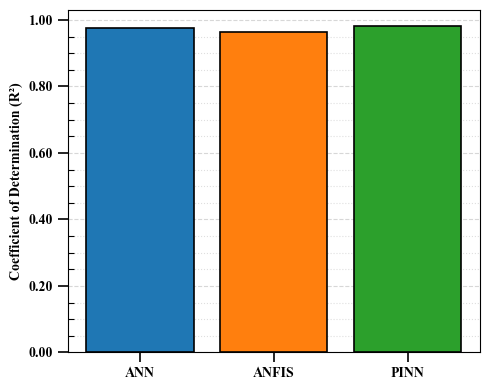

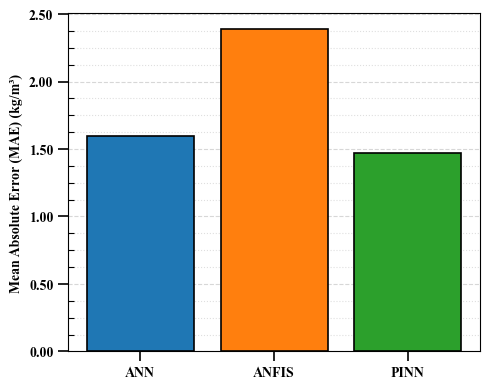

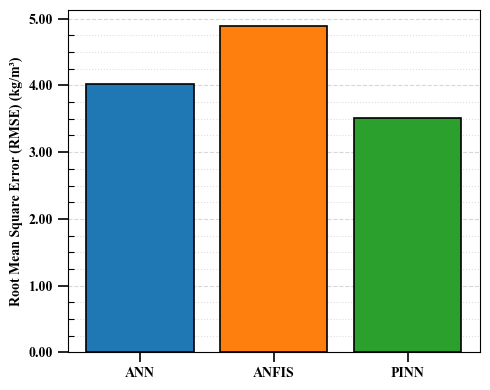

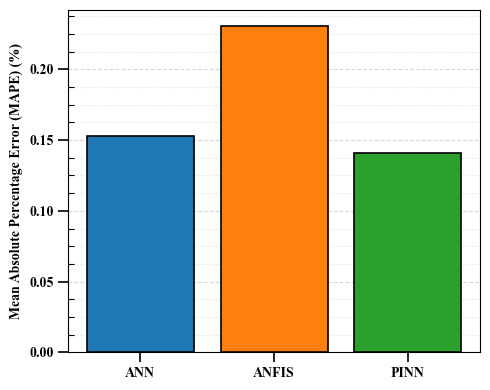

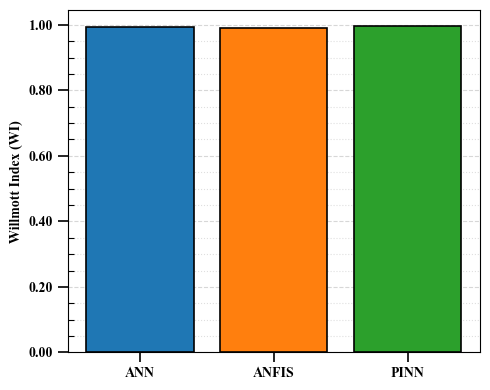

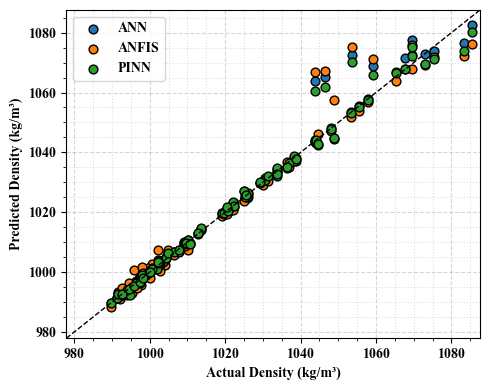


Done. Results saved in: C:\Users\masal\Desktop\ANN_ANFIS_PINN_Corrected


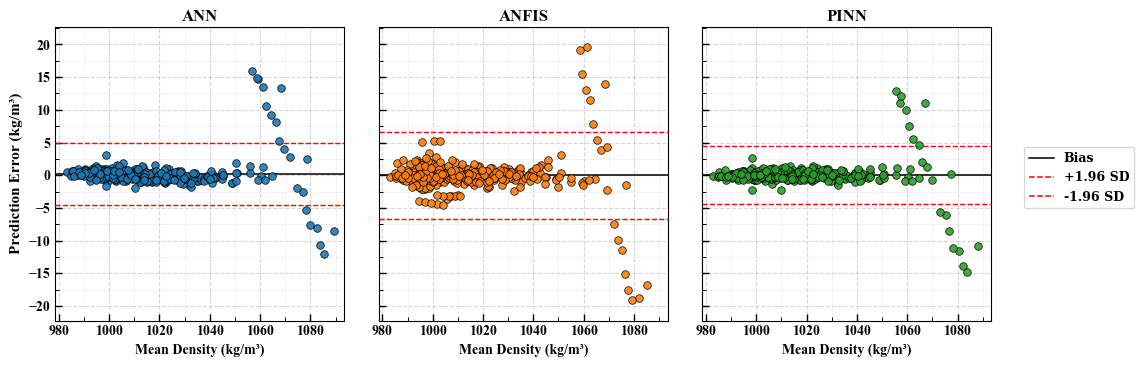


Bland-Altman statistics (TRAINING only):
Model   Set   N  Bias (kg/m3)  SD (kg/m3)  Lower LoA (kg/m3)  Upper LoA (kg/m3)
  ANN Train 348        0.1888      2.3930            -4.5014             4.8790
ANFIS Train 348       -0.0451      3.3963            -6.7019             6.6117
 PINN Train 348        0.0009      2.2811            -4.4701             4.4718

Saved training-only Bland-Altman figure to: C:\Users\masal\Desktop\ANN_ANFIS_PINN_Corrected


In [17]:
# ANN vs ANFIS vs PINN — corrected fair comparison
# Hybrid nanofluid density prediction; Jupyter compatible.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from matplotlib.ticker import AutoMinorLocator, FormatStrFormatter
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

SEED = 42
EPOCHS = 1500
LEARNING_RATE = 0.001
LAMBDA_PHY = 0.001  # Physics regularization weight
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass
plt.rcParams.update({'font.family':'Times New Roman','font.weight':'bold',
                     'axes.labelweight':'bold','axes.titleweight':'bold'})
output_dir = os.path.join(os.path.expanduser('~'), 'Desktop', 'ANN_ANFIS_PINN_Corrected')
try:
    os.makedirs(output_dir, exist_ok=True)
except OSError:
    output_dir = os.path.join(os.getcwd(), 'ANN_ANFIS_PINN_Corrected')
    os.makedirs(output_dir, exist_ok=True)

file_path = 'Density_Prediction_Dataset.csv'
if not os.path.isfile(file_path):
    raise FileNotFoundError(f'Place {file_path} in the current working directory: {os.getcwd()}')
df = pd.read_csv(file_path)
columns = ['NanoParticle','BaseFluid','Temperature','VolumeConcentration',
           'rho_np1','rho_np2','rho_bf','phi1','phi2','Density']
if len(df.columns) != len(columns):
    raise ValueError(f'Expected {len(columns)} columns, found {len(df.columns)}')
df.columns = columns
numeric_cols = ['Temperature','VolumeConcentration','rho_np1','rho_np2',
                'rho_bf','phi1','phi2','Density']
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df = df.dropna(subset=columns).reset_index(drop=True)
# The supplied dataset records phi1 and phi2 in percent.
df['phi1'] /= 100.0
df['phi2'] /= 100.0
if (df[['phi1','phi2']].lt(0).any().any() or
    (df['phi1']+df['phi2'] > 1).any()):
    raise ValueError('Invalid phi1/phi2 values after percent-to-fraction conversion.')
df['rho_physics'] = (df['phi1']*df['rho_np1'] + df['phi2']*df['rho_np2']
                     + (1-df['phi1']-df['phi2'])*df['rho_bf'])
features = ['NanoParticle','BaseFluid','Temperature','VolumeConcentration','phi1','phi2']
X = df[features]
y = df['Density'].to_numpy(dtype=np.float64).reshape(-1,1)
physics = df['rho_physics'].to_numpy(dtype=np.float64).reshape(-1,1)
indices = np.arange(len(df))
train_idx, test_idx = train_test_split(indices, test_size=0.2, random_state=SEED)
try:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)
preprocessor = ColumnTransformer([
    ('num',StandardScaler(),['Temperature','VolumeConcentration','phi1','phi2']),
    ('cat',encoder,['NanoParticle','BaseFluid'])
])
X_train = np.asarray(preprocessor.fit_transform(X.iloc[train_idx]),dtype=np.float32)
X_test = np.asarray(preprocessor.transform(X.iloc[test_idx]),dtype=np.float32)
y_scaler = StandardScaler().fit(y[train_idx])
y_train = y_scaler.transform(y[train_idx]).astype(np.float32)
y_test_true = y[test_idx]
phy_train = y_scaler.transform(physics[train_idx]).astype(np.float32)
X_train_tf = tf.convert_to_tensor(X_train)
y_train_tf = tf.convert_to_tensor(y_train)
phy_train_tf = tf.convert_to_tensor(phy_train)

# ANN and PINN have precisely the same architecture (64-32-16).
# Their only possible difference is the physics term in the loss.
def make_network(input_dim):
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(input_dim,)),
        tf.keras.layers.Dense(64, activation='tanh'),
        tf.keras.layers.Dense(32, activation='tanh'),
        tf.keras.layers.Dense(16, activation='tanh'),
        tf.keras.layers.Dense(1)
    ])

class ANFIS(tf.keras.Model):
    def __init__(self, input_dim, n_rules=12):
        super().__init__()
        self.centers = self.add_weight(name='centers',shape=(input_dim,n_rules),initializer='random_normal',trainable=True)
        self.sigmas = self.add_weight(name='sigmas',shape=(input_dim,n_rules),initializer='ones',trainable=True)
        self.consequents = self.add_weight(name='consequents',shape=(n_rules,input_dim),initializer='random_normal',trainable=True)
        self.bias = self.add_weight(name='bias',shape=(n_rules,),initializer='zeros',trainable=True)
    def call(self,x,training=False):
        x_exp = tf.expand_dims(x,axis=2)
        centers = tf.expand_dims(self.centers,axis=0)
        sigmas = tf.expand_dims(tf.nn.softplus(self.sigmas)+1e-6,axis=0)
        membership = tf.exp(-0.5*tf.square((x_exp-centers)/sigmas))
        firing = tf.reduce_prod(membership,axis=1)
        normalized = firing/(tf.reduce_sum(firing,axis=1,keepdims=True)+1e-6)
        rules = tf.matmul(x,self.consequents,transpose_b=True)+self.bias
        return tf.reduce_sum(normalized*rules,axis=1,keepdims=True)

huber = tf.keras.losses.Huber()

def train_model(model, name, lambda_phy=0.0):
    optimizer = tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE)
    history = []
    # Exactly the same training algorithm for ANN and PINN at lambda=0.
    @tf.function
    def step(x, target, rho):
        with tf.GradientTape() as tape:
            pred = model(x,training=True)
            data_loss = huber(target,pred)
            if lambda_phy == 0.0:
                loss = data_loss
            else:
                loss = data_loss + tf.cast(lambda_phy,tf.float32)*huber(rho,pred)
        gradients = tape.gradient(loss,model.trainable_variables)
        optimizer.apply_gradients(zip(gradients,model.trainable_variables))
        return loss
    for epoch in range(EPOCHS):
        loss = step(X_train_tf,y_train_tf,phy_train_tf)
        history.append(float(loss.numpy()))
        if epoch % 300 == 0 or epoch == EPOCHS-1:
            print(f'{name}: epoch {epoch+1}/{EPOCHS}, loss={history[-1]:.6f}')
    return history

input_dim = X_train.shape[1]
ann = make_network(input_dim)
initial_weights = ann.get_weights()
pinn = make_network(input_dim)
pinn.set_weights(initial_weights)
anfis = ANFIS(input_dim, n_rules=12)
_ = anfis(X_train_tf[:1])  # Build variables before training
history_ann = train_model(ann,'ANN',lambda_phy=0.0)
history_anfis = train_model(anfis,'ANFIS',lambda_phy=0.0)
history_pinn = train_model(pinn,f'PINN lambda={LAMBDA_PHY:g}',lambda_phy=LAMBDA_PHY)

def predict(model, x):
    return y_scaler.inverse_transform(model(x,training=False).numpy()).ravel()

predictions = {
    'ANN':predict(ann,X_test),
    'ANFIS':predict(anfis,X_test),
    'PINN':predict(pinn,X_test)
}
actual = y_test_true.ravel()

def metrics(true, pred):
    """R2, MAE, RMSE (kg/m3), MAPE (%), and Willmott index."""
    true = np.asarray(true, dtype=np.float64).ravel()
    pred = np.asarray(pred, dtype=np.float64).ravel()
    r2 = r2_score(true, pred)
    mae = mean_absolute_error(true, pred)
    rmse = np.sqrt(mean_squared_error(true, pred))
    # MAPE is undefined for a zero actual value: explicitly report NaN.
    mape = (100.0 * np.mean(np.abs((true - pred) / true))
            if np.all(true != 0) else np.nan)
    mean_true = np.mean(true)
    wi_denominator = np.sum((np.abs(pred - mean_true) + np.abs(true - mean_true)) ** 2)
    wi_numerator = np.sum((true - pred) ** 2)
    wi = (1.0 - wi_numerator / wi_denominator if wi_denominator > 0
          else (1.0 if wi_numerator == 0 else np.nan))
    return [r2, mae, rmse, mape, wi]

results_df = pd.DataFrame([
    [name, *metrics(actual, pred)] for name, pred in predictions.items()
], columns=['Model', 'R2', 'MAE', 'RMSE', 'MAPE', 'WI'])
print('\nComparison Results (Test Set)')
print(results_df.to_string(index=False,float_format=lambda v:f'{v:.6f}'))
if LAMBDA_PHY == 0.0:
    max_difference = float(np.max(np.abs(predictions['ANN']-predictions['PINN'])))
    print(f'\nANN vs PINN(lambda=0) max absolute prediction difference: {max_difference:.12g} kg/m³')
    np.testing.assert_allclose(predictions['ANN'],predictions['PINN'],rtol=1e-5,atol=1e-4,
        err_msg='ANN and PINN(lambda=0) should match: check environment determinism.')
    print('PASS: ANN and PINN(lambda=0) match within numerical tolerance.')

results_df.to_excel(os.path.join(output_dir,'ANN_ANFIS_PINN_Comparison.xlsx'),index=False)
predictions_df = pd.DataFrame({'Actual Density':actual,
                               **{f'{k} Prediction':v for k,v in predictions.items()}})
predictions_df.to_excel(os.path.join(output_dir,'ANN_ANFIS_PINN_Predictions.xlsx'),index=False)
pd.DataFrame({'Epoch':np.arange(1,EPOCHS+1),'ANN':history_ann,
              'ANFIS':history_anfis,'PINN':history_pinn}).to_csv(
                  os.path.join(output_dir,'Training_History.csv'),index=False)
colors={'ANN':'#1f77b4','ANFIS':'#ff7f0e','PINN':'#2ca02c'}

# Five matching metric bar charts: existing R2 + four new charts.
metric_labels = {
    'R2': 'Coefficient of Determination (R²)',
    'MAE': 'Mean Absolute Error (MAE) (kg/m³)',
    'RMSE': 'Root Mean Square Error (RMSE) (kg/m³)',
    'MAPE': 'Mean Absolute Percentage Error (MAPE) (%)',
    'WI': 'Willmott Index (WI)'
}
for metric, ylabel in metric_labels.items():
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.set_axisbelow(True)
    ax.bar(results_df['Model'], results_df[metric],
           color=[colors[k] for k in results_df['Model']],
           edgecolor='black', linewidth=1.2, zorder=3)
    ax.set_ylabel(ylabel, fontweight='bold')
    ax.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))
    ax.yaxis.set_minor_locator(AutoMinorLocator(4))
    ax.grid(True, which='major', axis='y', linestyle='--', alpha=.5, zorder=0)
    ax.grid(True, which='minor', axis='y', linestyle=':', alpha=.4, zorder=0)
    ax.tick_params(axis='both', which='major', direction='out', length=7, width=1.2)
    ax.tick_params(axis='y', which='minor', direction='in', length=4, width=.8)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight('bold')
    fig.tight_layout()
    filename = f'ANN_ANFIS_PINN_{metric}_Comparison.png'
    fig.savefig(os.path.join(output_dir, filename), dpi=300,
                bbox_inches='tight', pad_inches=.1)
    plt.show()

fig,ax=plt.subplots(figsize=(5,4))
ax.set_axisbelow(True)
for name,pred in predictions.items():
    ax.scatter(actual,pred,color=colors[name],edgecolor='black',label=name,s=40,zorder=3)
y_min = min(980.0,float(np.min(actual)),*(float(np.min(v)) for v in predictions.values()))
y_max = max(float(np.max(actual)),*(float(np.max(v)) for v in predictions.values()))
margin = max((y_max-y_min)*.02,1.0)
y_min -= margin
y_max += margin
ax.set_xlim(y_min,y_max)
ax.set_ylim(y_min,y_max)
ax.plot([y_min,y_max],[y_min,y_max],'k--',linewidth=1,zorder=3)
ax.set_xlabel('Actual Density (kg/m³)',fontweight='bold')
ax.set_ylabel('Predicted Density (kg/m³)',fontweight='bold')
ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))
ax.yaxis.set_major_formatter(FormatStrFormatter('%.0f'))
ax.xaxis.set_minor_locator(AutoMinorLocator(4))
ax.yaxis.set_minor_locator(AutoMinorLocator(4))
ax.grid(True,which='major',linestyle='--',alpha=.5,zorder=0)
ax.grid(True,which='minor',linestyle=':',alpha=.4,zorder=0)
ax.legend(prop={'weight':'bold','family':'Times New Roman'})
fig.tight_layout()
fig.savefig(os.path.join(output_dir,'ANN_ANFIS_PINN_Actual_vs_Predicted.png'),dpi=300,bbox_inches='tight')
plt.show()
print('\nDone. Results saved in:',output_dir)


# ================================================================
# FIGURE 7: TRAINING-ONLY Bland-Altman plots (ANN, ANFIS, PINN)
# All bias and limits of agreement are calculated from TRAINING only.
# ================================================================
from matplotlib.lines import Line2D

train_actual = y[train_idx].reshape(-1)
train_predictions = {
    'ANN': predict(ann, X_train),
    'ANFIS': predict(anfis, X_train),
    'PINN': predict(pinn, X_train)
}

ba_statistics = []
ba_data = []
for name in ('ANN', 'ANFIS', 'PINN'):
    pred = np.asarray(train_predictions[name], dtype=float).reshape(-1)
    measured = np.asarray(train_actual, dtype=float).reshape(-1)
    mean_density = (measured + pred) / 2.0
    error = pred - measured  # Prediction minus experiment
    bias = float(np.mean(error))
    sd = float(np.std(error, ddof=1))
    lower = bias - 1.96 * sd
    upper = bias + 1.96 * sd
    ba_data.append((name, mean_density, error, bias, lower, upper))
    ba_statistics.append({
        'Model': name, 'Set': 'Train', 'N': len(error),
        'Bias (kg/m3)': bias, 'SD (kg/m3)': sd,
        'Lower LoA (kg/m3)': lower, 'Upper LoA (kg/m3)': upper
    })

all_x = np.concatenate([row[1] for row in ba_data])
all_y = np.concatenate([np.r_[row[2], row[4], row[5]] for row in ba_data])
xpad = max(float(np.ptp(all_x)) * 0.04, 1.0)
ypad = max(float(np.ptp(all_y)) * 0.08, 0.5)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharex=True, sharey=True)
for ax, (name, mean_density, error, bias, lower, upper) in zip(axes, ba_data):
    ax.set_axisbelow(True)
    ax.scatter(mean_density, error, s=30, facecolors=colors[name],
               edgecolors='black', linewidths=0.55, alpha=0.9, zorder=4)
    ax.axhline(bias, color='black', linestyle='-', linewidth=1.1, zorder=3)
    ax.axhline(upper, color='red', linestyle='--', linewidth=1.0, zorder=3)
    ax.axhline(lower, color='red', linestyle='--', linewidth=1.0, zorder=3)
    ax.set_title(name, fontweight='bold', fontsize=12, pad=4)
    ax.set_xlabel('Mean Density (kg/m³)', fontweight='bold', fontsize=10)
    ax.set_xlim(float(all_x.min()) - xpad, float(all_x.max()) + xpad)
    ax.set_ylim(float(all_y.min()) - ypad, float(all_y.max()) + ypad)
    ax.grid(True, which='major', linestyle='--', linewidth=0.8, alpha=0.5)
    ax.grid(True, which='minor', linestyle=':', linewidth=0.7, alpha=0.4)
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))
    ax.tick_params(which='major', direction='in', length=5, width=1)
    ax.tick_params(which='minor', direction='in', length=3, width=0.7)
    for tick in ax.get_xticklabels() + ax.get_yticklabels():
        tick.set_fontweight('bold')
axes[0].set_ylabel('Prediction Error (kg/m³)', fontweight='bold', fontsize=11)

handles = [
    Line2D([0], [0], color='black', lw=1.1, label='Bias'),
    Line2D([0], [0], color='red', ls='--', lw=1.1, label='+1.96 SD'),
    Line2D([0], [0], color='red', ls='--', lw=1.1, label='-1.96 SD'),
]
fig.legend(handles=handles, loc='center left', bbox_to_anchor=(0.82, 0.54),
           frameon=True, prop={'family': 'serif', 'weight': 'bold', 'size': 9})
fig.subplots_adjust(left=0.08, right=0.80, top=0.90, bottom=0.20, wspace=0.12)

ba_png = os.path.join(output_dir, 'Figure_7_Bland_Altman_Training_Only.png')
ba_pdf = os.path.join(output_dir, 'Figure_7_Bland_Altman_Training_Only.pdf')
fig.savefig(ba_png, dpi=600, bbox_inches='tight', facecolor='white')
fig.savefig(ba_pdf, bbox_inches='tight', facecolor='white')
plt.show()

ba_stats = pd.DataFrame(ba_statistics)
ba_stats.to_excel(os.path.join(output_dir, 'Bland_Altman_Training_Statistics.xlsx'), index=False)
print('\nBland-Altman statistics (TRAINING only):')
print(ba_stats.to_string(index=False, float_format=lambda value: f'{value:.4f}'))
print('\nSaved training-only Bland-Altman figure to:', output_dir)


ANN: epoch 1/1500, loss=0.435009
ANN: epoch 301/1500, loss=0.013282
ANN: epoch 601/1500, loss=0.011689
ANN: epoch 901/1500, loss=0.010715
ANN: epoch 1201/1500, loss=0.009298
ANN: epoch 1500/1500, loss=0.005986
ANFIS: epoch 1/1500, loss=0.404596
ANFIS: epoch 301/1500, loss=0.046347
ANFIS: epoch 601/1500, loss=0.017277
ANFIS: epoch 901/1500, loss=0.014589
ANFIS: epoch 1201/1500, loss=0.013395
ANFIS: epoch 1500/1500, loss=0.012073
PINN lambda=0.001: epoch 1/1500, loss=0.584875
PINN lambda=0.001: epoch 301/1500, loss=0.163039
PINN lambda=0.001: epoch 601/1500, loss=0.161447
PINN lambda=0.001: epoch 901/1500, loss=0.160473
PINN lambda=0.001: epoch 1201/1500, loss=0.159058
PINN lambda=0.001: epoch 1500/1500, loss=0.155213

Comparison Results (Test Set)
Model       R2      MAE     RMSE     MAPE       WI
  ANN 0.974733 1.595900 4.016903 0.152937 0.993894
ANFIS 0.962632 2.389088 4.884955 0.230370 0.990820
 PINN 0.980770 1.473058 3.504302 0.140872 0.995260


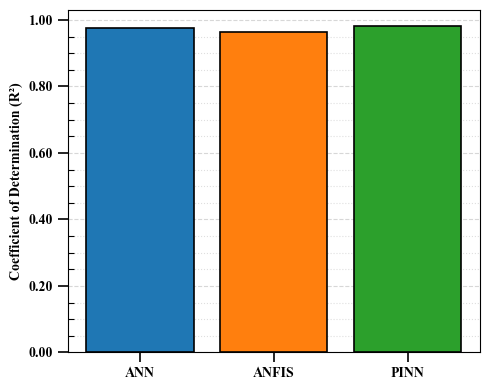

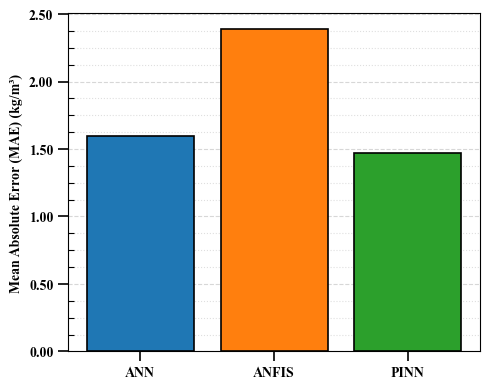

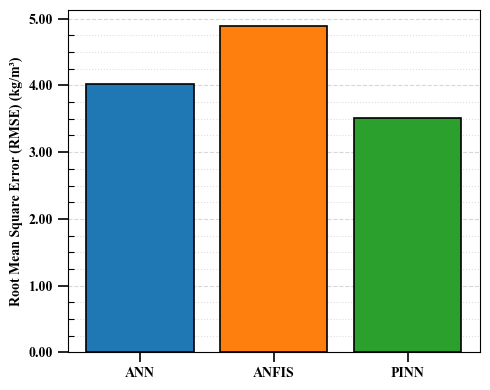

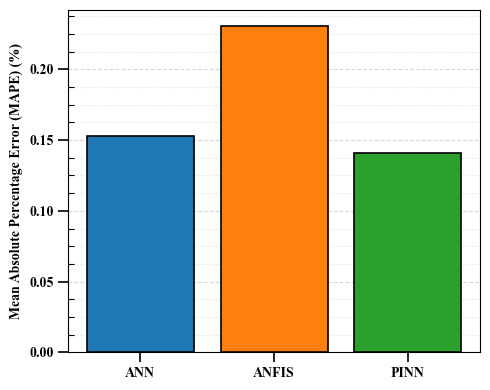

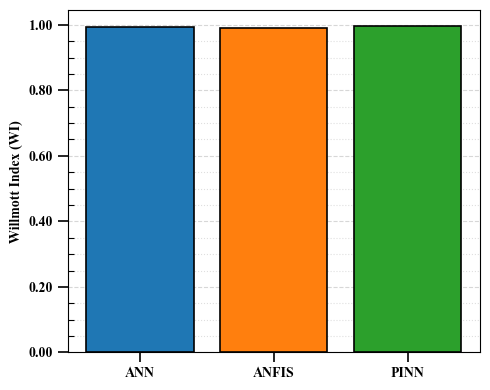

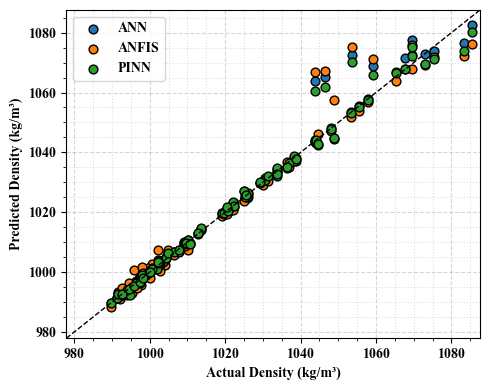


Done. Results saved in: C:\Users\masal\Desktop\ANN_ANFIS_PINN_Corrected


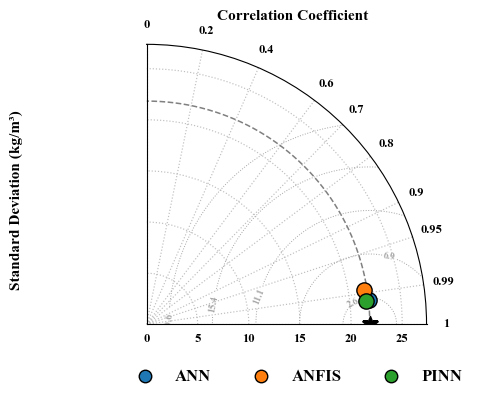


TAYLOR DIAGRAM STATISTICS — TRAINING ONLY
Experimental STD = 21.831838 kg/m3
Model  Dataset  STD (kg/m3)  Correlation  Centered RMSE (kg/m3)
  ANN Training    21.904798     0.994036               2.389528
ANFIS Training    21.511637     0.987864               3.391425
 PINN Training    21.583800     0.994560               2.277811
Figure size: 6 x 4 inches | Saved to: C:\Users\masal\Desktop\ANN_ANFIS_PINN_Corrected


In [18]:
# ANN vs ANFIS vs PINN — corrected fair comparison
# Hybrid nanofluid density prediction; Jupyter compatible.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from matplotlib.ticker import AutoMinorLocator, FormatStrFormatter
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

SEED = 42
EPOCHS = 1500
LEARNING_RATE = 0.001
LAMBDA_PHY = 0.001  # Physics regularization weight
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass
plt.rcParams.update({'font.family':'Times New Roman','font.weight':'bold',
                     'axes.labelweight':'bold','axes.titleweight':'bold'})
output_dir = os.path.join(os.path.expanduser('~'), 'Desktop', 'ANN_ANFIS_PINN_Corrected')
try:
    os.makedirs(output_dir, exist_ok=True)
except OSError:
    output_dir = os.path.join(os.getcwd(), 'ANN_ANFIS_PINN_Corrected')
    os.makedirs(output_dir, exist_ok=True)

file_path = 'Density_Prediction_Dataset.csv'
if not os.path.isfile(file_path):
    raise FileNotFoundError(f'Place {file_path} in the current working directory: {os.getcwd()}')
df = pd.read_csv(file_path)
columns = ['NanoParticle','BaseFluid','Temperature','VolumeConcentration',
           'rho_np1','rho_np2','rho_bf','phi1','phi2','Density']
if len(df.columns) != len(columns):
    raise ValueError(f'Expected {len(columns)} columns, found {len(df.columns)}')
df.columns = columns
numeric_cols = ['Temperature','VolumeConcentration','rho_np1','rho_np2',
                'rho_bf','phi1','phi2','Density']
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df = df.dropna(subset=columns).reset_index(drop=True)
# The supplied dataset records phi1 and phi2 in percent.
df['phi1'] /= 100.0
df['phi2'] /= 100.0
if (df[['phi1','phi2']].lt(0).any().any() or
    (df['phi1']+df['phi2'] > 1).any()):
    raise ValueError('Invalid phi1/phi2 values after percent-to-fraction conversion.')
df['rho_physics'] = (df['phi1']*df['rho_np1'] + df['phi2']*df['rho_np2']
                     + (1-df['phi1']-df['phi2'])*df['rho_bf'])
features = ['NanoParticle','BaseFluid','Temperature','VolumeConcentration','phi1','phi2']
X = df[features]
y = df['Density'].to_numpy(dtype=np.float64).reshape(-1,1)
physics = df['rho_physics'].to_numpy(dtype=np.float64).reshape(-1,1)
indices = np.arange(len(df))
train_idx, test_idx = train_test_split(indices, test_size=0.2, random_state=SEED)
try:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)
preprocessor = ColumnTransformer([
    ('num',StandardScaler(),['Temperature','VolumeConcentration','phi1','phi2']),
    ('cat',encoder,['NanoParticle','BaseFluid'])
])
X_train = np.asarray(preprocessor.fit_transform(X.iloc[train_idx]),dtype=np.float32)
X_test = np.asarray(preprocessor.transform(X.iloc[test_idx]),dtype=np.float32)
y_scaler = StandardScaler().fit(y[train_idx])
y_train = y_scaler.transform(y[train_idx]).astype(np.float32)
y_test_true = y[test_idx]
phy_train = y_scaler.transform(physics[train_idx]).astype(np.float32)
X_train_tf = tf.convert_to_tensor(X_train)
y_train_tf = tf.convert_to_tensor(y_train)
phy_train_tf = tf.convert_to_tensor(phy_train)

# ANN and PINN have precisely the same architecture (64-32-16).
# Their only possible difference is the physics term in the loss.
def make_network(input_dim):
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(input_dim,)),
        tf.keras.layers.Dense(64, activation='tanh'),
        tf.keras.layers.Dense(32, activation='tanh'),
        tf.keras.layers.Dense(16, activation='tanh'),
        tf.keras.layers.Dense(1)
    ])

class ANFIS(tf.keras.Model):
    def __init__(self, input_dim, n_rules=12):
        super().__init__()
        self.centers = self.add_weight(name='centers',shape=(input_dim,n_rules),initializer='random_normal',trainable=True)
        self.sigmas = self.add_weight(name='sigmas',shape=(input_dim,n_rules),initializer='ones',trainable=True)
        self.consequents = self.add_weight(name='consequents',shape=(n_rules,input_dim),initializer='random_normal',trainable=True)
        self.bias = self.add_weight(name='bias',shape=(n_rules,),initializer='zeros',trainable=True)
    def call(self,x,training=False):
        x_exp = tf.expand_dims(x,axis=2)
        centers = tf.expand_dims(self.centers,axis=0)
        sigmas = tf.expand_dims(tf.nn.softplus(self.sigmas)+1e-6,axis=0)
        membership = tf.exp(-0.5*tf.square((x_exp-centers)/sigmas))
        firing = tf.reduce_prod(membership,axis=1)
        normalized = firing/(tf.reduce_sum(firing,axis=1,keepdims=True)+1e-6)
        rules = tf.matmul(x,self.consequents,transpose_b=True)+self.bias
        return tf.reduce_sum(normalized*rules,axis=1,keepdims=True)

huber = tf.keras.losses.Huber()

def train_model(model, name, lambda_phy=0.0):
    optimizer = tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE)
    history = []
    # Exactly the same training algorithm for ANN and PINN at lambda=0.
    @tf.function
    def step(x, target, rho):
        with tf.GradientTape() as tape:
            pred = model(x,training=True)
            data_loss = huber(target,pred)
            if lambda_phy == 0.0:
                loss = data_loss
            else:
                loss = data_loss + tf.cast(lambda_phy,tf.float32)*huber(rho,pred)
        gradients = tape.gradient(loss,model.trainable_variables)
        optimizer.apply_gradients(zip(gradients,model.trainable_variables))
        return loss
    for epoch in range(EPOCHS):
        loss = step(X_train_tf,y_train_tf,phy_train_tf)
        history.append(float(loss.numpy()))
        if epoch % 300 == 0 or epoch == EPOCHS-1:
            print(f'{name}: epoch {epoch+1}/{EPOCHS}, loss={history[-1]:.6f}')
    return history

input_dim = X_train.shape[1]
ann = make_network(input_dim)
initial_weights = ann.get_weights()
pinn = make_network(input_dim)
pinn.set_weights(initial_weights)
anfis = ANFIS(input_dim, n_rules=12)
_ = anfis(X_train_tf[:1])  # Build variables before training
history_ann = train_model(ann,'ANN',lambda_phy=0.0)
history_anfis = train_model(anfis,'ANFIS',lambda_phy=0.0)
history_pinn = train_model(pinn,f'PINN lambda={LAMBDA_PHY:g}',lambda_phy=LAMBDA_PHY)

def predict(model, x):
    return y_scaler.inverse_transform(model(x,training=False).numpy()).ravel()

predictions = {
    'ANN':predict(ann,X_test),
    'ANFIS':predict(anfis,X_test),
    'PINN':predict(pinn,X_test)
}
actual = y_test_true.ravel()

def metrics(true, pred):
    """R2, MAE, RMSE (kg/m3), MAPE (%), and Willmott index."""
    true = np.asarray(true, dtype=np.float64).ravel()
    pred = np.asarray(pred, dtype=np.float64).ravel()
    r2 = r2_score(true, pred)
    mae = mean_absolute_error(true, pred)
    rmse = np.sqrt(mean_squared_error(true, pred))
    # MAPE is undefined for a zero actual value: explicitly report NaN.
    mape = (100.0 * np.mean(np.abs((true - pred) / true))
            if np.all(true != 0) else np.nan)
    mean_true = np.mean(true)
    wi_denominator = np.sum((np.abs(pred - mean_true) + np.abs(true - mean_true)) ** 2)
    wi_numerator = np.sum((true - pred) ** 2)
    wi = (1.0 - wi_numerator / wi_denominator if wi_denominator > 0
          else (1.0 if wi_numerator == 0 else np.nan))
    return [r2, mae, rmse, mape, wi]

results_df = pd.DataFrame([
    [name, *metrics(actual, pred)] for name, pred in predictions.items()
], columns=['Model', 'R2', 'MAE', 'RMSE', 'MAPE', 'WI'])
print('\nComparison Results (Test Set)')
print(results_df.to_string(index=False,float_format=lambda v:f'{v:.6f}'))
if LAMBDA_PHY == 0.0:
    max_difference = float(np.max(np.abs(predictions['ANN']-predictions['PINN'])))
    print(f'\nANN vs PINN(lambda=0) max absolute prediction difference: {max_difference:.12g} kg/m³')
    np.testing.assert_allclose(predictions['ANN'],predictions['PINN'],rtol=1e-5,atol=1e-4,
        err_msg='ANN and PINN(lambda=0) should match: check environment determinism.')
    print('PASS: ANN and PINN(lambda=0) match within numerical tolerance.')

results_df.to_excel(os.path.join(output_dir,'ANN_ANFIS_PINN_Comparison.xlsx'),index=False)
predictions_df = pd.DataFrame({'Actual Density':actual,
                               **{f'{k} Prediction':v for k,v in predictions.items()}})
predictions_df.to_excel(os.path.join(output_dir,'ANN_ANFIS_PINN_Predictions.xlsx'),index=False)
pd.DataFrame({'Epoch':np.arange(1,EPOCHS+1),'ANN':history_ann,
              'ANFIS':history_anfis,'PINN':history_pinn}).to_csv(
                  os.path.join(output_dir,'Training_History.csv'),index=False)
colors={'ANN':'#1f77b4','ANFIS':'#ff7f0e','PINN':'#2ca02c'}

# Five matching metric bar charts: existing R2 + four new charts.
metric_labels = {
    'R2': 'Coefficient of Determination (R²)',
    'MAE': 'Mean Absolute Error (MAE) (kg/m³)',
    'RMSE': 'Root Mean Square Error (RMSE) (kg/m³)',
    'MAPE': 'Mean Absolute Percentage Error (MAPE) (%)',
    'WI': 'Willmott Index (WI)'
}
for metric, ylabel in metric_labels.items():
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.set_axisbelow(True)
    ax.bar(results_df['Model'], results_df[metric],
           color=[colors[k] for k in results_df['Model']],
           edgecolor='black', linewidth=1.2, zorder=3)
    ax.set_ylabel(ylabel, fontweight='bold')
    ax.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))
    ax.yaxis.set_minor_locator(AutoMinorLocator(4))
    ax.grid(True, which='major', axis='y', linestyle='--', alpha=.5, zorder=0)
    ax.grid(True, which='minor', axis='y', linestyle=':', alpha=.4, zorder=0)
    ax.tick_params(axis='both', which='major', direction='out', length=7, width=1.2)
    ax.tick_params(axis='y', which='minor', direction='in', length=4, width=.8)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight('bold')
    fig.tight_layout()
    filename = f'ANN_ANFIS_PINN_{metric}_Comparison.png'
    fig.savefig(os.path.join(output_dir, filename), dpi=300,
                bbox_inches='tight', pad_inches=.1)
    plt.show()

fig,ax=plt.subplots(figsize=(5,4))
ax.set_axisbelow(True)
for name,pred in predictions.items():
    ax.scatter(actual,pred,color=colors[name],edgecolor='black',label=name,s=40,zorder=3)
y_min = min(980.0,float(np.min(actual)),*(float(np.min(v)) for v in predictions.values()))
y_max = max(float(np.max(actual)),*(float(np.max(v)) for v in predictions.values()))
margin = max((y_max-y_min)*.02,1.0)
y_min -= margin
y_max += margin
ax.set_xlim(y_min,y_max)
ax.set_ylim(y_min,y_max)
ax.plot([y_min,y_max],[y_min,y_max],'k--',linewidth=1,zorder=3)
ax.set_xlabel('Actual Density (kg/m³)',fontweight='bold')
ax.set_ylabel('Predicted Density (kg/m³)',fontweight='bold')
ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))
ax.yaxis.set_major_formatter(FormatStrFormatter('%.0f'))
ax.xaxis.set_minor_locator(AutoMinorLocator(4))
ax.yaxis.set_minor_locator(AutoMinorLocator(4))
ax.grid(True,which='major',linestyle='--',alpha=.5,zorder=0)
ax.grid(True,which='minor',linestyle=':',alpha=.4,zorder=0)
ax.legend(prop={'weight':'bold','family':'Times New Roman'})
fig.tight_layout()
fig.savefig(os.path.join(output_dir,'ANN_ANFIS_PINN_Actual_vs_Predicted.png'),dpi=300,bbox_inches='tight')
plt.show()
print('\nDone. Results saved in:',output_dir)


# ================================================================
# FIGURE 7: TRAINING-ONLY Bland-Altman plots (ANN, ANFIS, PINN)
# All bias and limits of agreement are calculated from TRAINING only.
# ================================================================
from matplotlib.lines import Line2D

train_actual = y[train_idx].reshape(-1)
train_predictions = {
    'ANN': predict(ann, X_train),
    'ANFIS': predict(anfis, X_train),
    'PINN': predict(pinn, X_train)
}



# ============================================================
# FIGURE 8: TAYLOR DIAGRAM — TRAINING DATA ONLY
# No easy_mpl dependency: Matplotlib polar Taylor diagram.
# Standard deviations use ddof=0 consistently.
# ============================================================
from matplotlib.lines import Line2D as TaylorLine2D

TAYLOR_FIG_SIZE = (6, 4)
TAYLOR_COLORS = {'ANN': '#1f77b4', 'ANFIS': '#ff7f0e', 'PINN': '#2ca02c'}
observed = np.asarray(train_actual, dtype=float).ravel()
if observed.size < 3 or np.std(observed) == 0:
    raise ValueError('Training observations must contain at least 3 nonconstant values.')

ref_std = float(np.std(observed, ddof=0))
taylor_rows = []
for model_name in ('ANN', 'ANFIS', 'PINN'):
    estimated = np.asarray(train_predictions[model_name], dtype=float).ravel()
    if estimated.shape != observed.shape:
        raise ValueError(f'{model_name}: predictions and observations have different lengths.')
    if not np.all(np.isfinite(estimated)) or np.std(estimated) == 0:
        raise ValueError(f'{model_name}: invalid or constant predictions.')
    corr = float(np.clip(np.corrcoef(observed, estimated)[0, 1], -1, 1))
    std = float(np.std(estimated, ddof=0))
    crmsd = float(np.sqrt(np.mean(((estimated - estimated.mean()) -
                                   (observed - observed.mean())) ** 2)))
    taylor_rows.append({'Model': model_name, 'Dataset': 'Training',
                        'STD (kg/m3)': std, 'Correlation': corr,
                        'Centered RMSE (kg/m3)': crmsd})

# Standard Taylor diagram: polar angle = arccos(correlation), radius = STD.
# Show positive correlations in first quadrant. If any correlation is
# negative, show the entire upper half-plane instead.
max_theta = np.pi if any(row['Correlation'] < 0 for row in taylor_rows) else np.pi / 2
rmax = max(ref_std, *(row['STD (kg/m3)'] for row in taylor_rows)) * 1.25
fig = plt.figure(figsize=TAYLOR_FIG_SIZE, facecolor='white')
ax = fig.add_axes([0.12, 0.22, 0.73, 0.70], projection='polar')
ax.set_theta_zero_location('E')
ax.set_theta_direction(1)
ax.set_thetamin(0)
ax.set_thetamax(np.degrees(max_theta))
ax.set_ylim(0, rmax)

corr_ticks = ([1.0, 0.99, 0.95, 0.9, 0.8, 0.7, 0.6, 0.4, 0.2, 0.0]
              if max_theta == np.pi/2 else
              [1.0, 0.9, 0.7, 0.5, 0.0, -0.5, -0.9, -1.0])
ax.set_thetagrids(np.degrees(np.arccos(corr_ticks)),
                  labels=[f'{c:g}' for c in corr_ticks], fontsize=9,
                  fontweight='bold')
ax.set_rlabel_position(135 if max_theta == np.pi/2 else 90)
ax.tick_params(axis='y', labelsize=9)
ax.grid(True, color='#bfbfbf', linestyle=':', linewidth=0.85)

# Reference standard deviation (experimental measurements).
theta = np.linspace(0, max_theta, 400)
ax.plot(theta, np.full_like(theta, ref_std), color='gray', linestyle='--',
        linewidth=1.1, zorder=2)
ax.plot([0], [ref_std], marker='*', color='black', markersize=12,
        linestyle='None', zorder=8)

# Centered RMSE isolines: E^2 = STD_obs^2 + STD_pred^2 - 2 STD_obs STD_pred corr.
thetas = np.linspace(0, max_theta, 180)
radii = np.linspace(0, rmax, 180)
TT, RR = np.meshgrid(thetas, radii)
centered_rmse_grid = np.sqrt(np.maximum(
    0, ref_std**2 + RR**2 - 2*ref_std*RR*np.cos(TT)))
levels = np.linspace(max(ref_std * 0.12, 0.1), ref_std * 0.9, 5)
cs = ax.contour(TT, RR, centered_rmse_grid, levels=levels,
                colors='0.65', linewidths=0.7, linestyles='dotted')
ax.clabel(cs, inline=True, fontsize=7, fmt='%.1f')

for row in taylor_rows:
    model_name = row['Model']
    angle = np.arccos(row['Correlation'])
    ax.plot([angle], [row['STD (kg/m3)']], marker='o', markersize=11,
            markerfacecolor=TAYLOR_COLORS[model_name], markeredgecolor='black',
            markeredgewidth=1.0, linestyle='None', zorder=10)

ax.text(0.52, 1.10, 'Correlation Coefficient', transform=ax.transAxes,
        ha='center', va='center', fontsize=11, fontweight='bold',
        fontfamily='Times New Roman')
fig.text(0.035, 0.53, 'Standard Deviation (kg/m³)', rotation=90,
         ha='center', va='center', fontsize=11, fontweight='bold',
         fontfamily='Times New Roman')
legend_handles = [TaylorLine2D([], [], marker='o', linestyle='None',
                  markersize=9, markerfacecolor=TAYLOR_COLORS[name],
                  markeredgecolor='black', label=name)
                  for name in ('ANN', 'ANFIS', 'PINN')]
fig.legend(handles=legend_handles, loc='lower center', ncol=3,
           bbox_to_anchor=(0.50, 0.03), frameon=False,
           prop={'family':'Times New Roman', 'weight':'bold', 'size':12})

for extension in ('png', 'tiff', 'pdf'):
    destination = os.path.join(output_dir, f'Figure_8_Taylor_Diagram_Training_6x4.{extension}')
    fig.savefig(destination, dpi=600, bbox_inches='tight', facecolor='white')
plt.show()
plt.close(fig)

print('\n' + '='*68)
print('TAYLOR DIAGRAM STATISTICS — TRAINING ONLY')
print('='*68)
print(f'Experimental STD = {ref_std:.6f} kg/m3')
taylor_stats = pd.DataFrame(taylor_rows)
print(taylor_stats.to_string(index=False, float_format=lambda x: f'{x:.6f}'))
taylor_stats.to_excel(os.path.join(output_dir, 'Taylor_Training_Statistics.xlsx'), index=False)
print(f'Figure size: 6 x 4 inches | Saved to: {output_dir}')



Testing predictions loaded successfully.
Number of testing observations: 88

NanoParticle types:
NanoParticle
Fe₃O₄-MWCNT     14
ZnO-MWCNT       10
TiO₂-SiO₂       10
Al₂O₃-MWCNT      9
TiO₂-MgO         9
TiO₂-MWCNT       8
Ag-GNP           7
ND-Fe₃O₄         6
CeO₂-MWCNT       5
 Co₃O₄/rGO       3
CuO-MWCNT        3
Al₂O₃/SiO₂       2
Al₂O₃-CNT        2
Name: count, dtype: int64


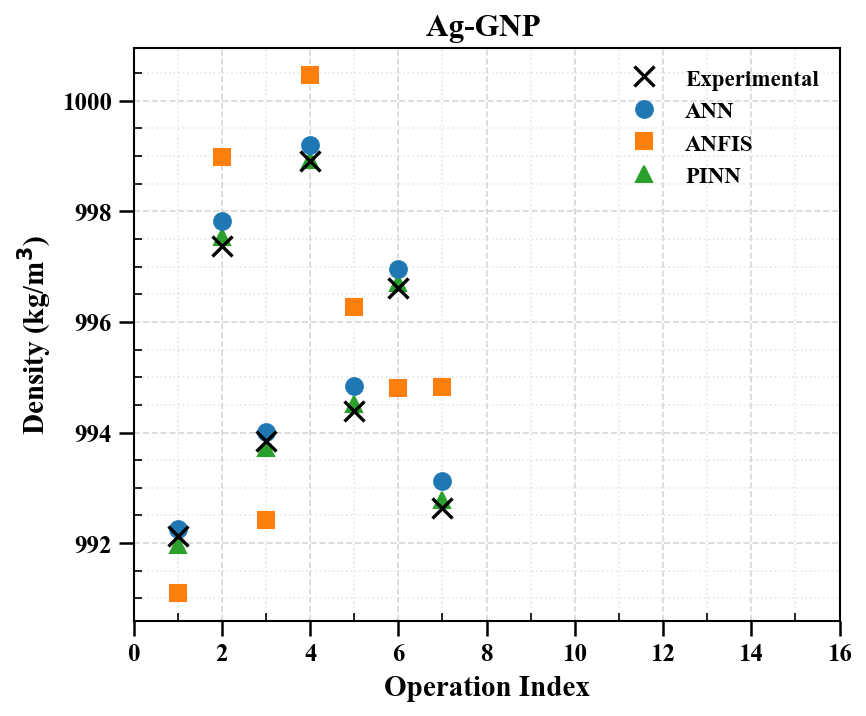

Saved: Ag-GNP_ANN_ANFIS_PINN_Testing


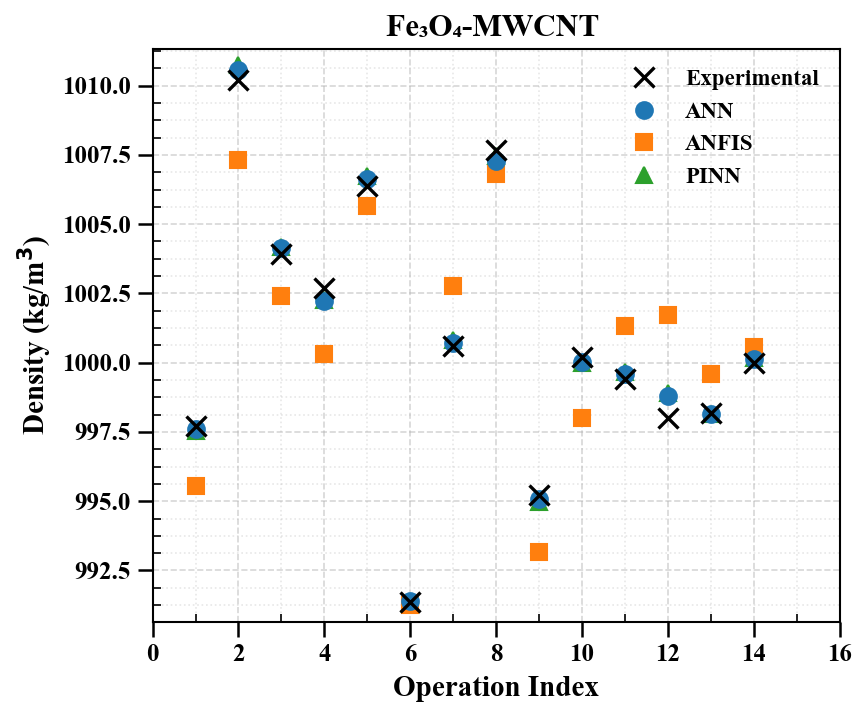

Saved: Fe₃O₄-MWCNT_ANN_ANFIS_PINN_Testing


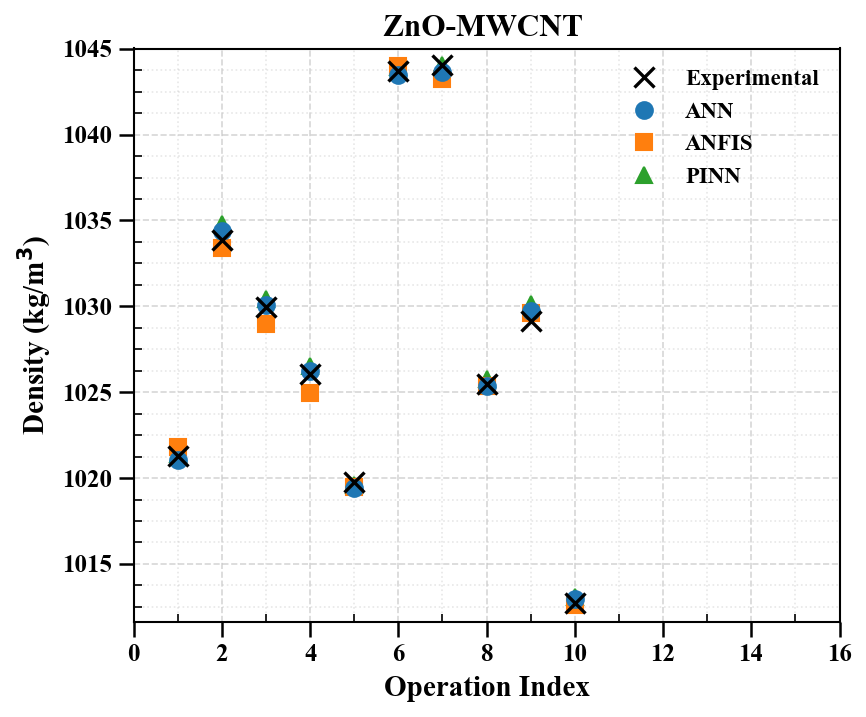

Saved: ZnO-MWCNT_ANN_ANFIS_PINN_Testing


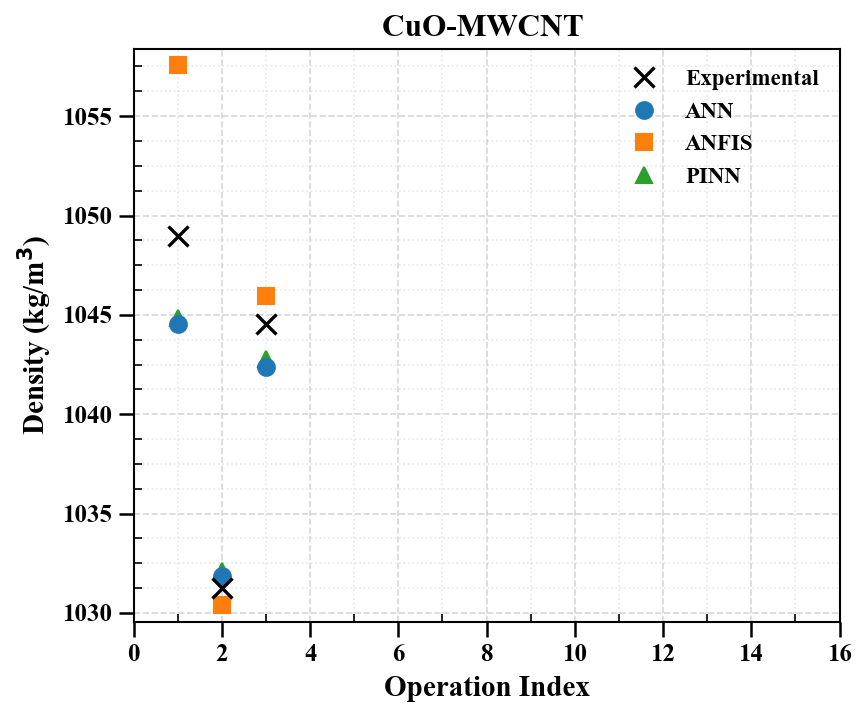

Saved: CuO-MWCNT_ANN_ANFIS_PINN_Testing


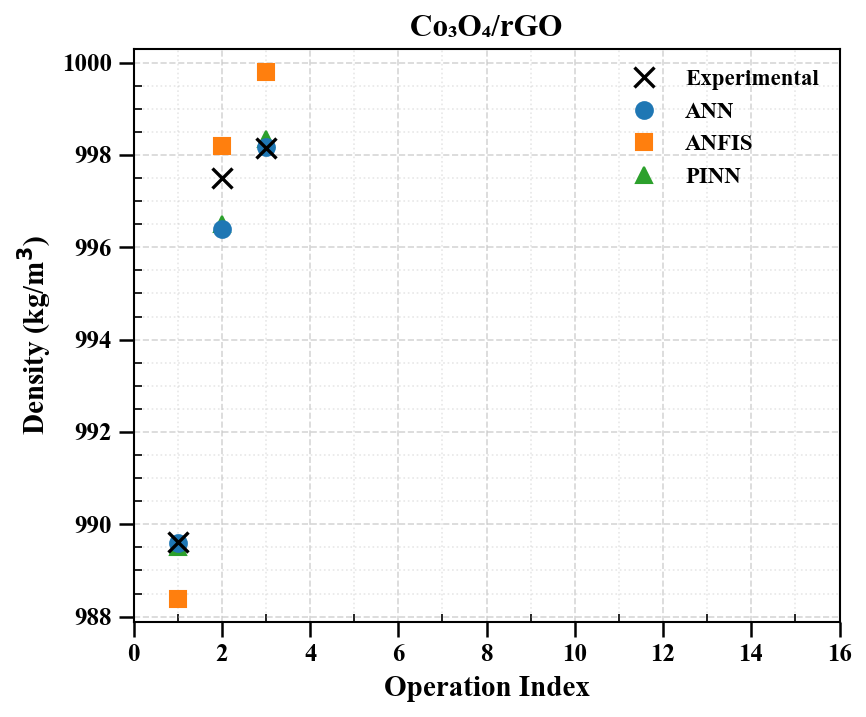

Saved: Co₃O₄_rGO_ANN_ANFIS_PINN_Testing


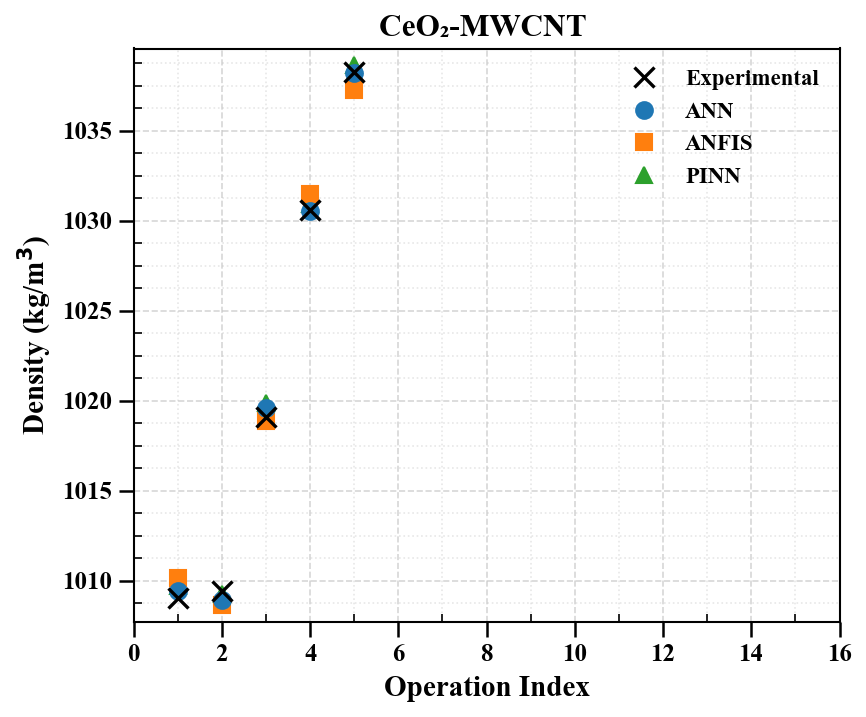

Saved: CeO₂-MWCNT_ANN_ANFIS_PINN_Testing


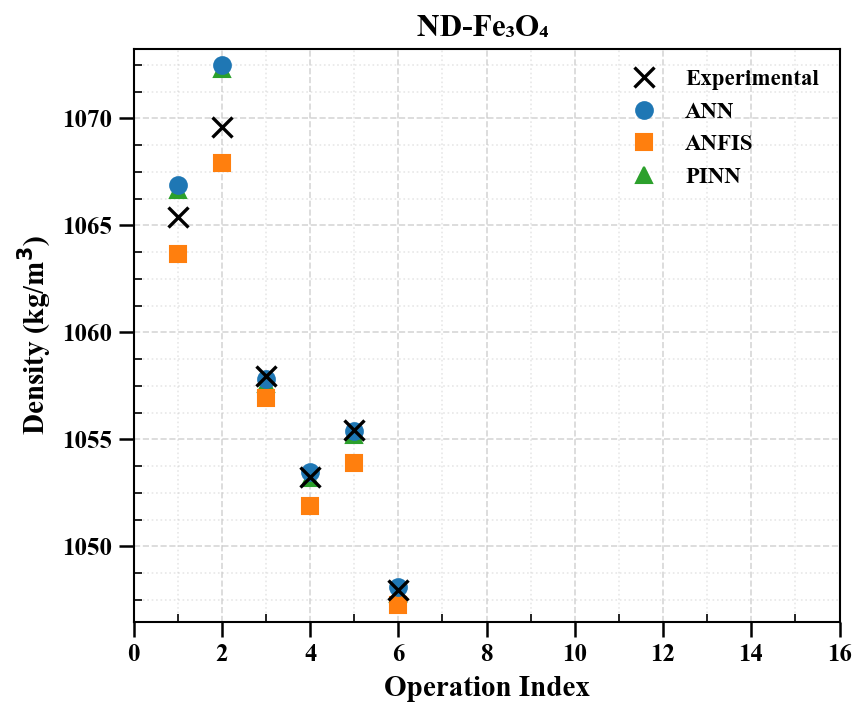

Saved: ND-Fe₃O₄_ANN_ANFIS_PINN_Testing


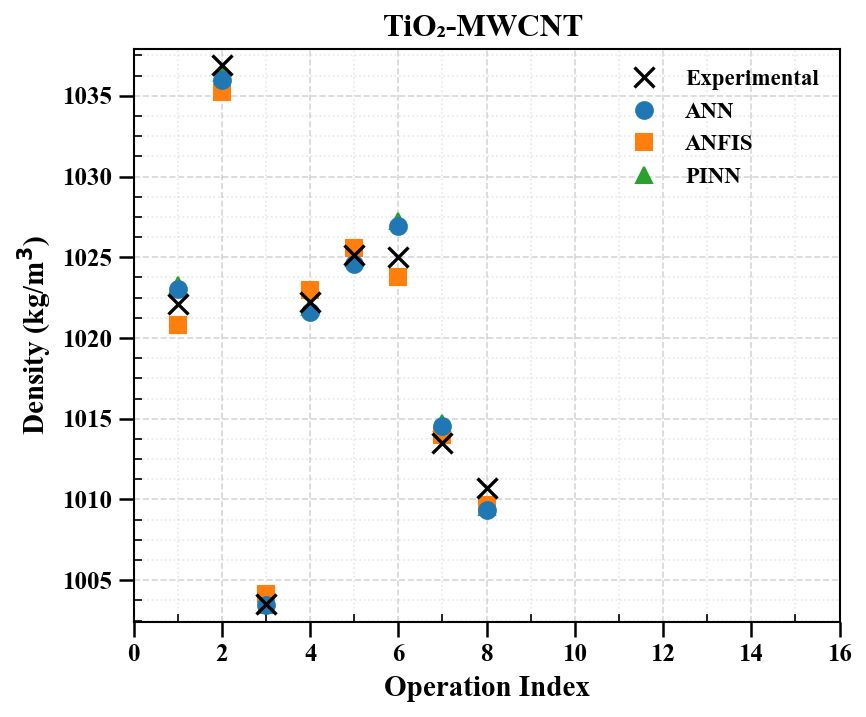

Saved: TiO₂-MWCNT_ANN_ANFIS_PINN_Testing


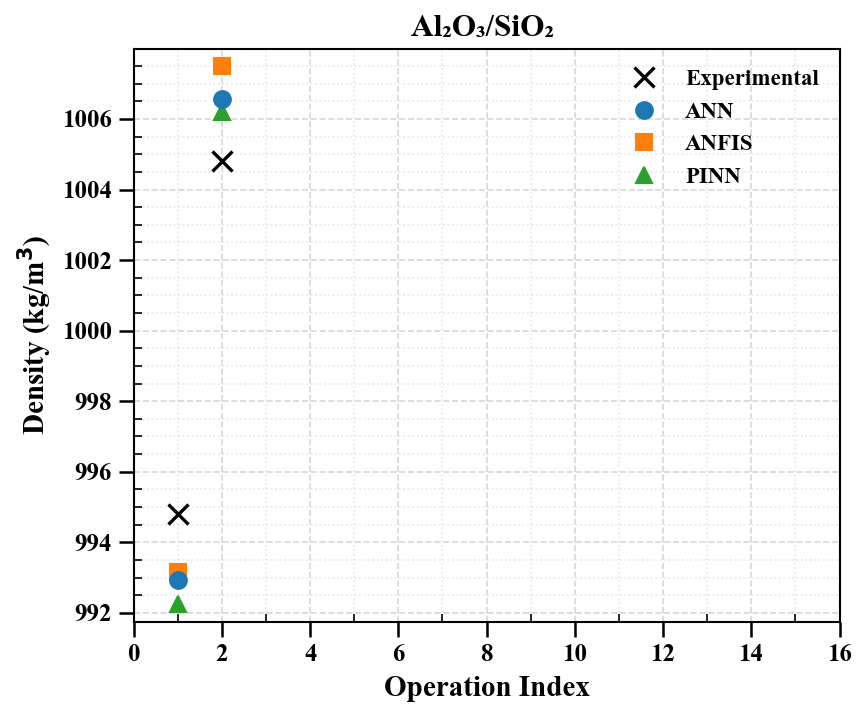

Saved: Al₂O₃_SiO₂_ANN_ANFIS_PINN_Testing


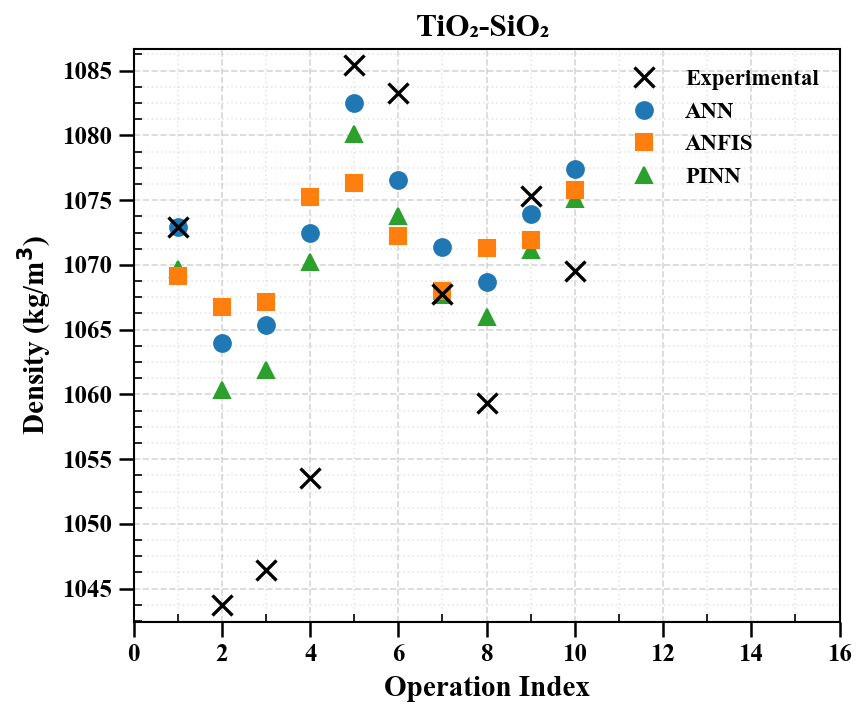

Saved: TiO₂-SiO₂_ANN_ANFIS_PINN_Testing


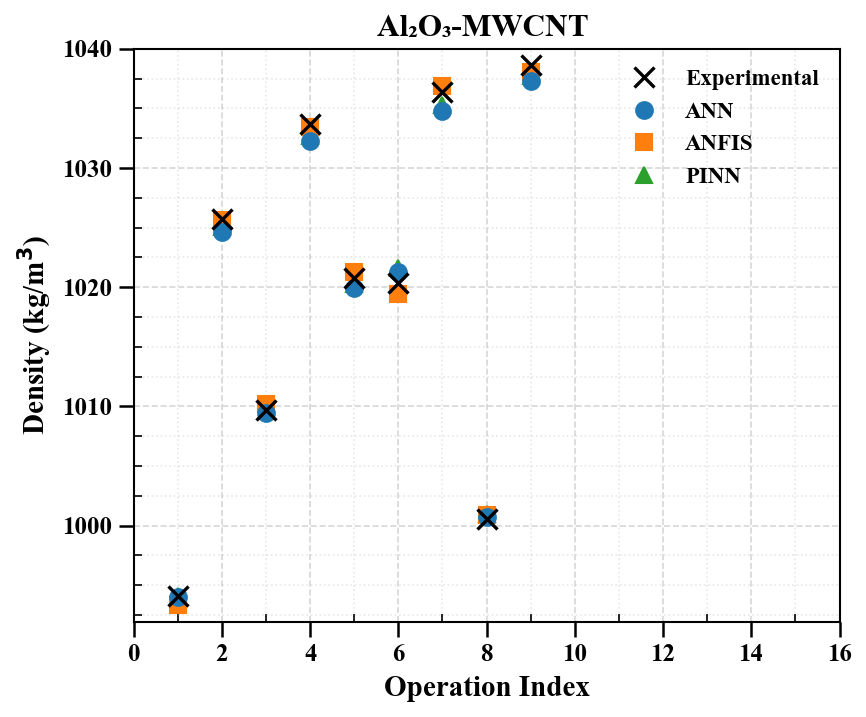

Saved: Al₂O₃-MWCNT_ANN_ANFIS_PINN_Testing


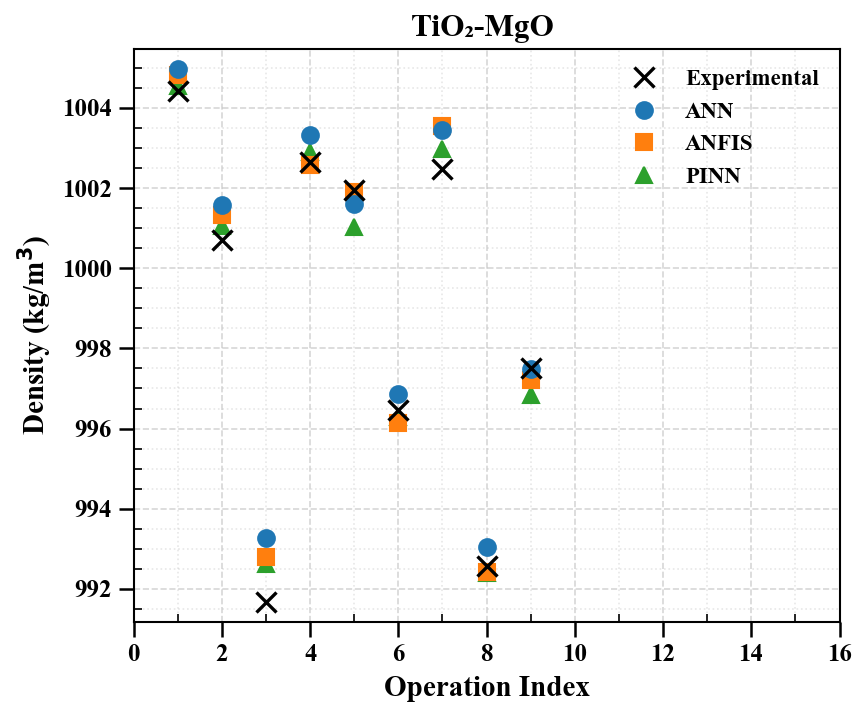

Saved: TiO₂-MgO_ANN_ANFIS_PINN_Testing


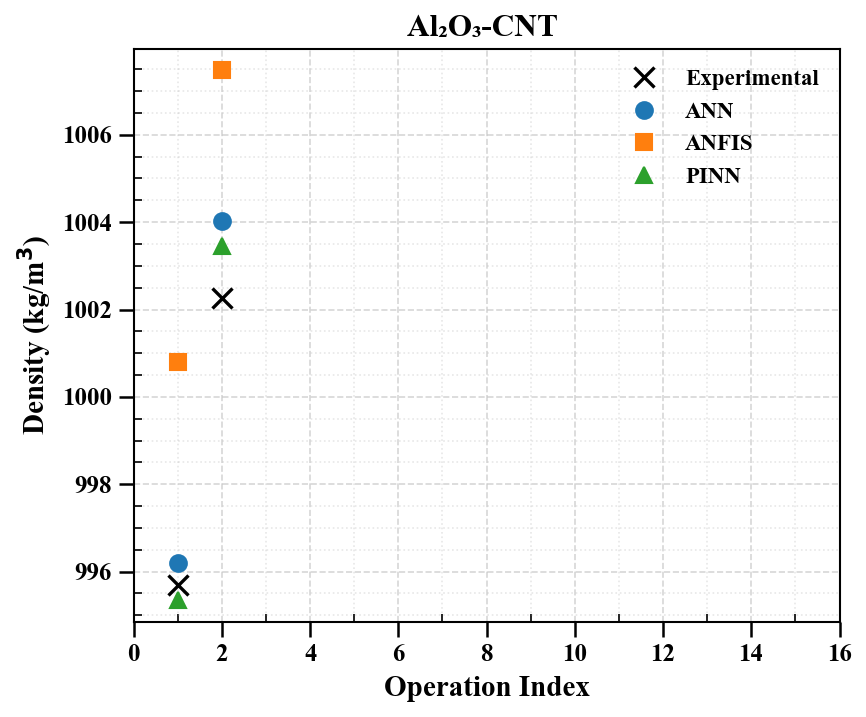

Saved: Al₂O₃-CNT_ANN_ANFIS_PINN_Testing

ALL FIGURES GENERATED SUCCESSFULLY
Dataset: Testing 20%
Model retraining: NO
Number of NanoParticle types: 13
Figure size: 6 x 5 inches
Resolution: 600 dpi
Output folder: C:\Users\masal\Desktop\NanoParticle_Comparison_Testing


In [24]:
# ============================================================
# EXPERIMENTAL vs ANN vs ANFIS vs PINN
# SEPARATE FIGURE FOR EACH NANOPARTICLE
#
# TESTING DATA ONLY (20%)
# NO MODEL RETRAINING
# Same formatting as previous figures
# ============================================================

import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from matplotlib.ticker import AutoMinorLocator


# ============================================================
# 1. SETTINGS
# ============================================================

SEED = 42
TEST_SIZE = 0.20

FONT_NAME = "Times New Roman"
FONT_SIZE = 14

FIGURE_SIZE = (6, 5)
DPI = 600

colors = {
    "ANN": "#1f77b4",
    "ANFIS": "#ff7f0e",
    "PINN": "#2ca02c"
}

plt.rcParams.update({
    "font.family": FONT_NAME,
    "font.serif": [FONT_NAME],
    "font.size": FONT_SIZE,
    "font.weight": "bold",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "axes.titlesize": 15
})


# ============================================================
# 2. OUTPUT FOLDER
# ============================================================

desktop = os.path.join(
    os.path.expanduser("~"),
    "Desktop"
)

output_folder = os.path.join(
    desktop,
    "NanoParticle_Comparison_Testing"
)

os.makedirs(
    output_folder,
    exist_ok=True
)


# ============================================================
# 3. INPUT FILES
# ============================================================

dataset_file = "Density_Prediction_Dataset.csv"

predictions_file = os.path.join(
    desktop,
    "ANN_ANFIS_PINN_Corrected",
    "ANN_ANFIS_PINN_Predictions.xlsx"
)

if not os.path.isfile(dataset_file):
    raise FileNotFoundError(
        f"Dataset not found: {dataset_file}"
    )

if not os.path.isfile(predictions_file):
    raise FileNotFoundError(
        f"Predictions file not found: {predictions_file}"
    )


# ============================================================
# 4. LOAD ORIGINAL DATASET
# ============================================================

df = pd.read_csv(dataset_file)

columns = [
    "NanoParticle",
    "BaseFluid",
    "Temperature",
    "VolumeConcentration",
    "rho_np1",
    "rho_np2",
    "rho_bf",
    "phi1",
    "phi2",
    "Density"
]

if len(df.columns) != len(columns):
    raise ValueError(
        "Dataset must contain exactly 10 columns."
    )

df.columns = columns

numeric_cols = [
    "Temperature",
    "VolumeConcentration",
    "rho_np1",
    "rho_np2",
    "rho_bf",
    "phi1",
    "phi2",
    "Density"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

df = df.dropna(
    subset=columns
).reset_index(drop=True)


# ============================================================
# 5. RECONSTRUCT TEST INDICES
# ============================================================

indices = np.arange(len(df))

train_idx, test_idx = train_test_split(
    indices,
    test_size=TEST_SIZE,
    random_state=SEED
)

test_df = df.iloc[
    test_idx
].reset_index(drop=True)


# ============================================================
# 6. LOAD SAVED PREDICTIONS
# ============================================================

pred_df = pd.read_excel(
    predictions_file
)

required_cols = [
    "Actual Density",
    "ANN Prediction",
    "ANFIS Prediction",
    "PINN Prediction"
]

missing = [
    col for col in required_cols
    if col not in pred_df.columns
]

if missing:
    raise ValueError(
        f"Missing prediction columns: {missing}"
    )

if len(pred_df) != len(test_df):
    raise ValueError(
        "The number of predictions does not match "
        "the reconstructed testing dataset."
    )

# Verify that the saved predictions correspond
# to the reconstructed testing rows.

if not np.allclose(
    pred_df["Actual Density"].to_numpy(dtype=float),
    test_df["Density"].to_numpy(dtype=float),
    rtol=1e-7,
    atol=1e-5
):
    raise ValueError(
        "Actual Density values do not match the "
        "reconstructed testing rows. Check the "
        "dataset, split settings, and prediction file."
    )


# ============================================================
# 7. CREATE predictions_per_nano
# ============================================================

predictions_per_nano = pred_df.copy()

predictions_per_nano.insert(
    0,
    "NanoParticle",
    test_df["NanoParticle"].values
)

print("\nTesting predictions loaded successfully.")
print("Number of testing observations:", len(predictions_per_nano))

print("\nNanoParticle types:")
print(
    predictions_per_nano[
        "NanoParticle"
    ].value_counts()
)


# ============================================================
# 8. LOOP OVER NANOPARTICLES
# ============================================================

nano_types = predictions_per_nano[
    "NanoParticle"
].unique()

for nano in nano_types:

    subset = predictions_per_nano[
        predictions_per_nano["NanoParticle"] == nano
    ].reset_index(drop=True)

    actual = subset[
        "Actual Density"
    ].to_numpy(dtype=float)

    ann_pred = subset[
        "ANN Prediction"
    ].to_numpy(dtype=float)

    anfis_pred = subset[
        "ANFIS Prediction"
    ].to_numpy(dtype=float)

    pinn_pred = subset[
        "PINN Prediction"
    ].to_numpy(dtype=float)

    op_index = np.arange(
        1,
        len(subset) + 1
    )


    # ========================================================
    # 9. CREATE FIGURE
    # ========================================================

    fig, ax = plt.subplots(
        figsize=FIGURE_SIZE,
        dpi=150
    )

    # Experimental

    ax.plot(
        op_index,
        actual,
        "kx",
        markersize=10,
        markeredgewidth=1.6,
        label="Experimental",
        zorder=5
    )

    # ANN

    ax.plot(
        op_index,
        ann_pred,
        marker="o",
        linestyle="None",
        color=colors["ANN"],
        markersize=8,
        label="ANN",
        zorder=4
    )

    # ANFIS

    ax.plot(
        op_index,
        anfis_pred,
        marker="s",
        linestyle="None",
        color=colors["ANFIS"],
        markersize=8,
        label="ANFIS",
        zorder=3
    )

    # PINN

    ax.plot(
        op_index,
        pinn_pred,
        marker="^",
        linestyle="None",
        color=colors["PINN"],
        markersize=8,
        label="PINN",
        zorder=2
    )


    # ========================================================
    # 10. AXIS LIMITS
    # ========================================================

    all_values = np.concatenate([
        actual,
        ann_pred,
        anfis_pred,
        pinn_pred
    ])

    y_min = np.min(all_values)
    y_max = np.max(all_values)

    margin = max(
        0.03 * (y_max - y_min),
        0.5
    )

    ax.set_ylim(
        y_min - margin,
        y_max + margin
    )

    # Automatically include all test observations
    ax.set_xlim(
        0,
        max(16, len(subset) + 1)
    )


    # ========================================================
    # 11. AXIS LABELS
    # ========================================================

    ax.set_xlabel(
        "Operation Index",
        fontsize=14,
        fontweight="bold",
        fontname=FONT_NAME,
        labelpad=5
    )

    ax.set_ylabel(
        r"Density (kg/m$^3$)",
        fontsize=14,
        fontweight="bold",
        fontname=FONT_NAME,
        labelpad=4
    )

    ax.set_title(
        str(nano),
        fontsize=15,
        fontweight="bold",
        fontname=FONT_NAME
    )


    # ========================================================
    # 12. LEGEND
    # ========================================================

    ax.legend(
        frameon=False,
        loc="best",
        prop={
            "family": FONT_NAME,
            "size": 11,
            "weight": "bold"
        }
    )


    # ========================================================
    # 13. GRID AND TICKS
    # ========================================================

    ax.set_axisbelow(True)

    ax.xaxis.set_minor_locator(
        AutoMinorLocator(2)
    )

    ax.yaxis.set_minor_locator(
        AutoMinorLocator(4)
    )

    ax.tick_params(
        axis="both",
        which="major",
        direction="out",
        length=7,
        width=1.2,
        labelsize=12
    )

    ax.tick_params(
        axis="both",
        which="minor",
        direction="in",
        length=4,
        width=0.8
    )

    ax.grid(
        axis="both",
        which="major",
        linestyle="--",
        alpha=0.5
    )

    ax.grid(
        axis="both",
        which="minor",
        linestyle=":",
        alpha=0.3
    )

    for label in (
        ax.get_xticklabels()
        + ax.get_yticklabels()
    ):
        label.set_fontname(FONT_NAME)
        label.set_fontweight("bold")


    # ========================================================
    # 14. SAVE FIGURE
    # ========================================================

    safe_name = re.sub(
        r'[<>:"/\\|?*\s()]+',
        "_",
        str(nano)
    ).strip("_")

    plt.tight_layout()

    for extension in ["png", "tiff", "pdf"]:

        save_path = os.path.join(
            output_folder,
            f"{safe_name}_ANN_ANFIS_PINN_Testing.{extension}"
        )

        fig.savefig(
            save_path,
            dpi=DPI,
            bbox_inches="tight",
            facecolor="white"
        )

    plt.show()
    plt.close(fig)

    print(
        f"Saved: {safe_name}_ANN_ANFIS_PINN_Testing"
    )


# ============================================================
# 15. SAVE COMBINED PREDICTIONS
# ============================================================

excel_file = os.path.join(
    output_folder,
    "Predictions_Per_NanoParticle_Testing.xlsx"
)

predictions_per_nano.to_excel(
    excel_file,
    index=False
)

print("\n" + "=" * 65)
print("ALL FIGURES GENERATED SUCCESSFULLY")
print("=" * 65)
print("Dataset: Testing 20%")
print("Model retraining: NO")
print("Number of NanoParticle types:", len(nano_types))
print("Figure size: 6 x 5 inches")
print("Resolution: 600 dpi")
print("Output folder:", output_folder)
print("=" * 65)

In [25]:
# ============================================================
# ANN / ANFIS / PINN: TEST METRICS BY NANOPARTICLE
# No retraining; reconstructs the original 20% test split.
# ============================================================
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

SEED = 42
TEST_SIZE = 0.20
DATA_FILE = 'Density_Prediction_Dataset.csv'
PREDICTION_FILE = os.path.join(os.path.expanduser('~'), 'Desktop',
    'ANN_ANFIS_PINN_Corrected', 'ANN_ANFIS_PINN_Predictions.xlsx')
OUTPUT_FOLDER = os.path.join(os.path.expanduser('~'), 'Desktop', 'NanoParticle_Test_Metrics')
os.makedirs(OUTPUT_FOLDER, exist_ok=True)

columns = ['NanoParticle','BaseFluid','Temperature','VolumeConcentration',
           'rho_np1','rho_np2','rho_bf','phi1','phi2','Density']
df = pd.read_csv(DATA_FILE)
if len(df.columns) != 10:
    raise ValueError('Expected exactly 10 dataset columns.')
df.columns = columns
for col in ['Temperature','VolumeConcentration','rho_np1','rho_np2','rho_bf','phi1','phi2','Density']:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df = df.dropna(subset=columns).reset_index(drop=True)

_, test_idx = train_test_split(np.arange(len(df)), test_size=TEST_SIZE, random_state=SEED)
test_df = df.iloc[test_idx].reset_index(drop=True)
pred = pd.read_excel(PREDICTION_FILE)
required = ['Actual Density','ANN Prediction','ANFIS Prediction','PINN Prediction']
if any(c not in pred.columns for c in required):
    raise ValueError('Missing columns in saved predictions: ' + str([c for c in required if c not in pred.columns]))
if len(pred) != len(test_df) or not np.allclose(
        pred['Actual Density'].to_numpy(dtype=float),
        test_df['Density'].to_numpy(dtype=float), rtol=1e-7, atol=1e-5):
    raise ValueError('Saved predictions do not match the original test split. Check source files.')

pred.insert(0, 'NanoParticle', test_df['NanoParticle'].values)

# R2 is undefined for a single observation or constant experimental values.
def calculate_metrics(y, yhat):
    y = np.asarray(y, dtype=float)
    yhat = np.asarray(yhat, dtype=float)
    err = yhat - y
    n = len(y)
    r2 = r2_score(y, yhat) if n >= 2 and np.var(y) > 0 else np.nan
    mae = mean_absolute_error(y, yhat)
    rmse = np.sqrt(mean_squared_error(y, yhat))
    mape = 100 * np.mean(np.abs(err / y)) if np.all(y != 0) else np.nan
    mean_y = np.mean(y)
    wi_denom = np.sum((np.abs(yhat - mean_y) + np.abs(y - mean_y)) ** 2)
    wi_num = np.sum(err ** 2)
    wi = 1 - wi_num / wi_denom if wi_denom > 0 else (1.0 if wi_num == 0 else np.nan)
    return dict(N=n, R2=r2, MAE=mae, RMSE=rmse, MAPE_Percent=mape,
                WI=wi, Bias=float(np.mean(err)),
                Error_SD=float(np.std(err, ddof=1)) if n > 1 else np.nan,
                Max_Absolute_Error=float(np.max(np.abs(err))))

rows = []
for nano, group in pred.groupby('NanoParticle', sort=True):
    for model in ['ANN', 'ANFIS', 'PINN']:
        rows.append({'NanoParticle': str(nano), 'Model': model,
                     **calculate_metrics(group['Actual Density'], group[f'{model} Prediction'])})
for model in ['ANN', 'ANFIS', 'PINN']:
    rows.append({'NanoParticle': 'ALL TEST DATA', 'Model': model,
                 **calculate_metrics(pred['Actual Density'], pred[f'{model} Prediction'])})
result = pd.DataFrame(rows)

print('\nTEST PERFORMANCE BY NANOPARTICLE (NO RETRAINING)\n')
print(result.to_string(index=False, float_format=lambda x: f'{x:.6f}'))

xlsx_path = os.path.join(OUTPUT_FOLDER, 'Table_Performance_By_NanoParticle_Test.xlsx')
with pd.ExcelWriter(xlsx_path) as writer:
    result.to_excel(writer, sheet_name='All Metrics', index=False)
    result[result['NanoParticle'] == 'ALL TEST DATA'].to_excel(writer, sheet_name='Overall Test', index=False)
    pred.to_excel(writer, sheet_name='Test Predictions', index=False)
    for metric in ['R2','MAE','RMSE','MAPE_Percent','WI']:
        wide = result[result['NanoParticle'] != 'ALL TEST DATA'].pivot(
            index='NanoParticle', columns='Model', values=metric)
        wide.to_excel(writer, sheet_name=metric[:31])
result.to_csv(os.path.join(OUTPUT_FOLDER, 'Table_Performance_By_NanoParticle_Test.csv'), index=False)
print('\nSaved Excel:', xlsx_path)



TEST PERFORMANCE BY NANOPARTICLE (NO RETRAINING)

 NanoParticle Model  N        R2       MAE      RMSE  MAPE_Percent       WI      Bias  Error_SD  Max_Absolute_Error
   Co₃O₄/rGO    ANN  3  0.973459  0.378859  0.631588      0.037987 0.993034 -0.367035  0.629511            1.093506
   Co₃O₄/rGO  ANFIS  3  0.894634  1.195916  1.258425      0.120183 0.980128  0.375194  1.471154            1.657080
   Co₃O₄/rGO   PINN  3  0.977206  0.430535  0.585308      0.043184 0.994179 -0.296641  0.617968            0.988403
      Ag-GNP    ANN  7  0.977439  0.327458  0.354412      0.032900 0.994454  0.327458  0.146431            0.489578
      Ag-GNP  ANFIS  7  0.492829  1.645023  1.680368      0.165303 0.901276  0.422063  1.756820            2.191238
      Ag-GNP   PINN  7  0.997111  0.117146  0.126831      0.011781 0.999292  0.031534  0.132691            0.171565
   Al₂O₃-CNT    ANN  2  0.844961  1.129735  1.292876      0.112883 0.968494  1.129735  0.889074            1.758406
   Al₂O₃-CNT  ANFIS  

In [26]:
"""Reviewer #4 direct benchmark: ref [4] Gradient Boosting family vs saved ANN/ANFIS/PINN.
Run in Jupyter with: %run Ref4_Fair_Benchmark_No_ANN_Retraining.py
This is a FAIR REIMPLEMENTATION of the reference's Gradient Boosting model family,
NOT an exact reproduction of its autoencoder+GWO pipeline (full settings/split unavailable).
"""
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, KFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from scipy.stats import randint, uniform

SEED = 42
ROOT = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
DESKTOP = Path.home() / 'Desktop'
OUT = DESKTOP / 'Reference4_Fair_Comparison'
OUT.mkdir(parents=True, exist_ok=True)

def locate(filename):
    for p in (Path.cwd()/filename, ROOT/filename, DESKTOP/filename):
        if p.exists(): return p
    raise FileNotFoundError(f'Missing {filename}. Put it next to this script or in working directory.')

data = pd.read_csv(locate('Density_Prediction_Dataset.csv'))
if data.shape[1] != 10: raise ValueError('Expected 10 dataset columns in original order.')
data.columns = ['NanoParticle','BaseFluid','Temperature','VolumeConcentration',
                'rho_np1','rho_np2','rho_bf','phi1','phi2','Density']
if data.isna().any().any(): raise ValueError('Missing values: inspect original data before benchmark.')
cat_cols=['NanoParticle','BaseFluid']
num_cols=['Temperature','VolumeConcentration','rho_np1','rho_np2','rho_bf','phi1','phi2']
features=cat_cols+num_cols
# Match the prior ANN/ANFIS/PINN split (same original row order).
tr,te=train_test_split(np.arange(len(data)),test_size=0.20,random_state=SEED)
ytr=data.iloc[tr]['Density'].to_numpy(dtype=float)
yte=data.iloc[te]['Density'].to_numpy(dtype=float)
prior=pd.read_excel(locate('ANN_ANFIS_PINN_Predictions.xlsx'))
required=['Actual Density','ANN Prediction','ANFIS Prediction','PINN Prediction']
if not set(required).issubset(prior.columns): raise ValueError('Saved predictions missing expected columns.')
if len(prior)!=len(te) or not np.allclose(prior['Actual Density'],yte,rtol=0,atol=1e-5):
    raise ValueError('Saved predictions do NOT match the test partition. Stop: comparison would be invalid.')
try:
    encoder=OneHotEncoder(handle_unknown='ignore',sparse_output=False)
except TypeError:
    encoder=OneHotEncoder(handle_unknown='ignore',sparse=False)
prep=ColumnTransformer([('cat',encoder,cat_cols),('num',StandardScaler(),num_cols)])
pipe=Pipeline([('prep',prep),('gb',GradientBoostingRegressor(random_state=SEED))])
# Train-only hyperparameter search. No test information used for tuning.
space={
 'gb__n_estimators':randint(100,601),
 'gb__learning_rate':uniform(0.015,0.135),
 'gb__max_depth':randint(2,6),
 'gb__min_samples_leaf':randint(1,7),
 'gb__subsample':uniform(0.70,0.30),
 'gb__max_features':[None,0.8,1.0],
}
search=RandomizedSearchCV(pipe,space,n_iter=35,scoring='neg_root_mean_squared_error',
 cv=KFold(n_splits=5,shuffle=True,random_state=SEED),n_jobs=-1,
 random_state=SEED,refit=True,verbose=1)
search.fit(data.iloc[tr][features],ytr)
gb_pred=search.predict(data.iloc[te][features])

def wi(y,p):
    mean=y.mean()
    den=np.sum((np.abs(p-mean)+np.abs(y-mean))**2)
    return float(1-np.sum((y-p)**2)/den) if den else np.nan

def metrics(name,p):
    p=np.asarray(p,dtype=float)
    return {'Model':name,'N':len(yte),'R2':r2_score(yte,p),
       'MAE (kg/m3)':mean_absolute_error(yte,p),
       'RMSE (kg/m3)':np.sqrt(mean_squared_error(yte,p)),
       'MAPE (%)':np.mean(np.abs((yte-p)/yte))*100,
       'WI':wi(yte,p)}
rows=[metrics('ANN (saved)',prior['ANN Prediction']),
      metrics('ANFIS (saved)',prior['ANFIS Prediction']),
      metrics('PINN (saved)',prior['PINN Prediction']),
      metrics('Ref [4] Gradient Boosting - fair reimplementation',gb_pred)]
comparison=pd.DataFrame(rows)
# Published values: explicitly different protocol; DO NOT mix into fair-ranking metrics.
reported=pd.DataFrame([
 {'Reference':'Mathur et al. (2025), IEEE Access, DOI 10.1109/ACCESS.2025.3543475',
  'Model':'Gradient Boosting + augmentation + GWO (published)',
  'Reported R2':0.99999,'Reported MSE':0.00091,'Reported RMSE':0.03022,
  'Comparison status':'Literature-reported; not verified on identical test rows'},
 {'Reference':'Mathur et al. (2025), IEEE Access',
  'Model':'RNN + linear regression stacking + autoencoder augmentation (published)',
  'Reported R2':0.9999,'Reported MSE':0.0014,'Reported RMSE':0.037,
  'Comparison status':'Literature-reported; not verified on identical test rows'}])
allpred=pd.DataFrame({'Original_Row_Index':te,'NanoParticle':data.iloc[te]['NanoParticle'].to_numpy(),
 'Actual Density':yte,'ANN Prediction':prior['ANN Prediction'].to_numpy(),
 'ANFIS Prediction':prior['ANFIS Prediction'].to_numpy(),
 'PINN Prediction':prior['PINN Prediction'].to_numpy(),
 'Reference4_GradientBoosting_Fair':gb_pred})
params=pd.DataFrame([{'Parameter':k,'Value':str(v)} for k,v in search.best_params_.items()])
notes=pd.DataFrame({'Methodological notes':[
 'All evaluated models use exactly the same 88 original held-out rows, verified by matching actual density.',
 'ANN/ANFIS/PINN predictions are read from the saved file; NO retraining of these models.',
 'The ref [4] Gradient Boosting algorithm family is retrained on the original training rows only.',
 'All preprocessing and hyperparameter selection occur within training-only CV folds.',
 'The original article used autoencoder augmentation and GWO/PSO; these are NOT reproduced here.',
 'Therefore this is a fair algorithm-family benchmark, NOT exact replication of published R2=0.99999.',
 'Do not claim the published scores were achieved on the exact same held-out samples.',
 'The article reports 349/87 while an 80/20 split of 436 with sklearn yields 348/88; verify protocol.',
 'The original article also reports outlier removal; no test rows are removed in this fair benchmark.',
 ]})
output=OUT/'Reference4_Fair_Benchmark.xlsx'
with pd.ExcelWriter(output,engine='openpyxl') as writer:
    comparison.to_excel(writer,'Fair_Same_Test_Set',index=False)
    reported.to_excel(writer,'Published_Not_Comparable',index=False)
    allpred.to_excel(writer,'Paired_Test_Predictions',index=False)
    params.to_excel(writer,'Selected_GB_Parameters',index=False)
    notes.to_excel(writer,'Interpretation_Notes',index=False)
comparison.to_csv(OUT/'Reference4_Fair_Benchmark.csv',index=False)
allpred.to_csv(OUT/'Reference4_Paired_Test_Predictions.csv',index=False)
print('\nSAME TEST SET (88 rows):\n',comparison.to_string(index=False,float_format=lambda x:f'{x:.6f}'))
print('\nBest training-only CV RMSE:',-search.best_score_)
print('Best GB parameters:',search.best_params_)
print('\nSaved:',output)


Fitting 5 folds for each of 35 candidates, totalling 175 fits


C:\Users\masal\AppData\Local\Temp\ipykernel_18160\3960915716.py:112: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  comparison.to_excel(writer,'Fair_Same_Test_Set',index=False)
C:\Users\masal\AppData\Local\Temp\ipykernel_18160\3960915716.py:113: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  reported.to_excel(writer,'Published_Not_Comparable',index=False)
C:\Users\masal\AppData\Local\Temp\ipykernel_18160\3960915716.py:114: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  allpred.to_excel(writer,'Paired_Test_Predictions',index=False)
C:\Users\masal\AppData\Local\Temp\ipykernel_18160\3960915716.py:115: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be key


SAME TEST SET (88 rows):
                                             Model  N       R2  MAE (kg/m3)  RMSE (kg/m3)  MAPE (%)       WI
                                      ANN (saved) 88 0.960593     2.230460      5.016496  0.214255 0.990357
                                    ANFIS (saved) 88 0.965120     2.172796      4.719531  0.209270 0.991427
                                     PINN (saved) 88 0.973782     1.605028      4.091771  0.153623 0.993591
Ref [4] Gradient Boosting - fair reimplementation 88 0.997103     1.020190      1.360081  0.100009 0.999268

Best training-only CV RMSE: 1.4166678599101359
Best GB parameters: {'gb__learning_rate': np.float64(0.14050918306624738), 'gb__max_depth': 2, 'gb__max_features': 0.8, 'gb__min_samples_leaf': 1, 'gb__n_estimators': 600, 'gb__subsample': np.float64(0.9614381770563152)}

Saved: C:\Users\masal\Desktop\Reference4_Fair_Comparison\Reference4_Fair_Benchmark.xlsx


ANN: epoch 1/1500, loss=0.435009
ANN: epoch 301/1500, loss=0.013282
ANN: epoch 601/1500, loss=0.011689
ANN: epoch 901/1500, loss=0.010715
ANN: epoch 1201/1500, loss=0.009298
ANN: epoch 1500/1500, loss=0.005986
ANFIS: epoch 1/1500, loss=0.404596
ANFIS: epoch 301/1500, loss=0.046347
ANFIS: epoch 601/1500, loss=0.017277
ANFIS: epoch 901/1500, loss=0.014589
ANFIS: epoch 1201/1500, loss=0.013395
ANFIS: epoch 1500/1500, loss=0.012073
PINN lambda=0.001: epoch 1/1500, loss=0.584875
PINN lambda=0.001: epoch 301/1500, loss=0.163039
PINN lambda=0.001: epoch 601/1500, loss=0.161447
PINN lambda=0.001: epoch 901/1500, loss=0.160473
PINN lambda=0.001: epoch 1201/1500, loss=0.159058
PINN lambda=0.001: epoch 1500/1500, loss=0.155213

Training Ref. [4] Gradient Boosting baseline on TRAINING data only...
Fitting 5 folds for each of 35 candidates, totalling 175 fits
Best GB CV RMSE: 1.5234197809844565
Best GB parameters: {'model__learning_rate': np.float64(0.14050918306624738), 'model__max_depth': 2, 'mod

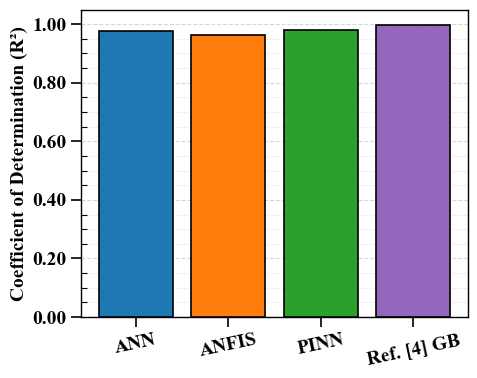

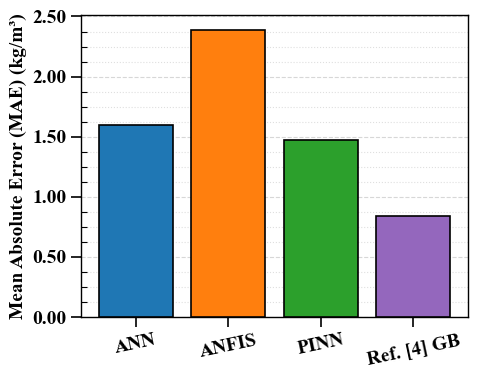

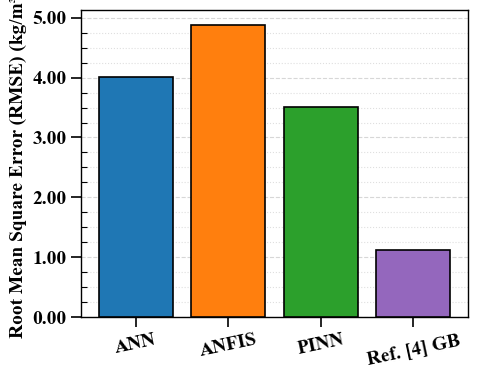

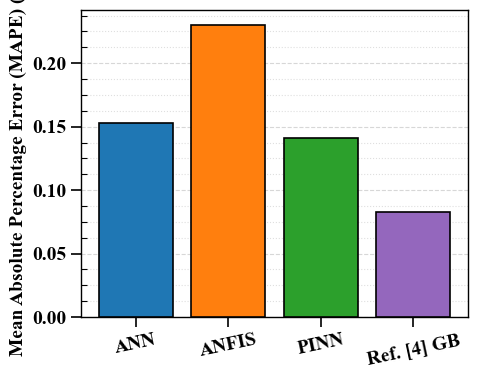

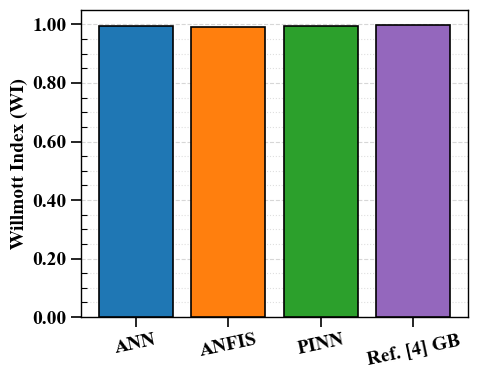

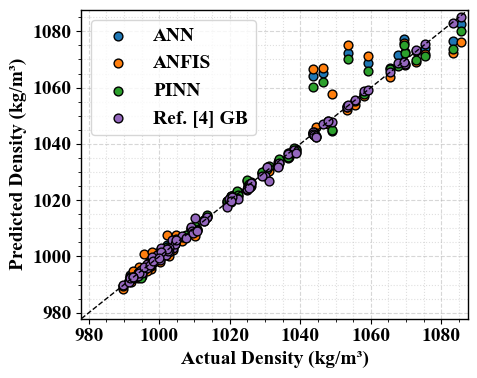


Done. Results saved in: C:\Users\masal\Desktop\ANN_ANFIS_PINN_Ref4_Comparison


In [27]:
# ANN vs ANFIS vs PINN — corrected fair comparison
# Hybrid nanofluid density prediction; Jupyter compatible.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from matplotlib.ticker import AutoMinorLocator, FormatStrFormatter
from sklearn.model_selection import train_test_split, KFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingRegressor
from scipy.stats import randint, uniform
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

SEED = 42
EPOCHS = 1500
LEARNING_RATE = 0.001
LAMBDA_PHY = 0.001  # Physics regularization weight
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass
plt.rcParams.update({'font.family':'Times New Roman','font.weight':'bold',
                     'axes.labelweight':'bold','axes.titleweight':'bold'})
output_dir = os.path.join(os.path.expanduser('~'), 'Desktop', 'ANN_ANFIS_PINN_Ref4_Comparison')
try:
    os.makedirs(output_dir, exist_ok=True)
except OSError:
    output_dir = os.path.join(os.getcwd(), 'ANN_ANFIS_PINN_Corrected')
    os.makedirs(output_dir, exist_ok=True)

file_path = 'Density_Prediction_Dataset.csv'
if not os.path.isfile(file_path):
    raise FileNotFoundError(f'Place {file_path} in the current working directory: {os.getcwd()}')
df = pd.read_csv(file_path)
columns = ['NanoParticle','BaseFluid','Temperature','VolumeConcentration',
           'rho_np1','rho_np2','rho_bf','phi1','phi2','Density']
if len(df.columns) != len(columns):
    raise ValueError(f'Expected {len(columns)} columns, found {len(df.columns)}')
df.columns = columns
numeric_cols = ['Temperature','VolumeConcentration','rho_np1','rho_np2',
                'rho_bf','phi1','phi2','Density']
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df = df.dropna(subset=columns).reset_index(drop=True)
# The supplied dataset records phi1 and phi2 in percent.
df['phi1'] /= 100.0
df['phi2'] /= 100.0
if (df[['phi1','phi2']].lt(0).any().any() or
    (df['phi1']+df['phi2'] > 1).any()):
    raise ValueError('Invalid phi1/phi2 values after percent-to-fraction conversion.')
df['rho_physics'] = (df['phi1']*df['rho_np1'] + df['phi2']*df['rho_np2']
                     + (1-df['phi1']-df['phi2'])*df['rho_bf'])
features = ['NanoParticle','BaseFluid','Temperature','VolumeConcentration','phi1','phi2']
X = df[features]
y = df['Density'].to_numpy(dtype=np.float64).reshape(-1,1)
physics = df['rho_physics'].to_numpy(dtype=np.float64).reshape(-1,1)
indices = np.arange(len(df))
train_idx, test_idx = train_test_split(indices, test_size=0.2, random_state=SEED)
try:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)
preprocessor = ColumnTransformer([
    ('num',StandardScaler(),['Temperature','VolumeConcentration','phi1','phi2']),
    ('cat',encoder,['NanoParticle','BaseFluid'])
])
X_train = np.asarray(preprocessor.fit_transform(X.iloc[train_idx]),dtype=np.float32)
X_test = np.asarray(preprocessor.transform(X.iloc[test_idx]),dtype=np.float32)
y_scaler = StandardScaler().fit(y[train_idx])
y_train = y_scaler.transform(y[train_idx]).astype(np.float32)
y_test_true = y[test_idx]
phy_train = y_scaler.transform(physics[train_idx]).astype(np.float32)
X_train_tf = tf.convert_to_tensor(X_train)
y_train_tf = tf.convert_to_tensor(y_train)
phy_train_tf = tf.convert_to_tensor(phy_train)

# ANN and PINN have precisely the same architecture (64-32-16).
# Their only possible difference is the physics term in the loss.
def make_network(input_dim):
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(input_dim,)),
        tf.keras.layers.Dense(64, activation='tanh'),
        tf.keras.layers.Dense(32, activation='tanh'),
        tf.keras.layers.Dense(16, activation='tanh'),
        tf.keras.layers.Dense(1)
    ])

class ANFIS(tf.keras.Model):
    def __init__(self, input_dim, n_rules=12):
        super().__init__()
        self.centers = self.add_weight(name='centers',shape=(input_dim,n_rules),initializer='random_normal',trainable=True)
        self.sigmas = self.add_weight(name='sigmas',shape=(input_dim,n_rules),initializer='ones',trainable=True)
        self.consequents = self.add_weight(name='consequents',shape=(n_rules,input_dim),initializer='random_normal',trainable=True)
        self.bias = self.add_weight(name='bias',shape=(n_rules,),initializer='zeros',trainable=True)
    def call(self,x,training=False):
        x_exp = tf.expand_dims(x,axis=2)
        centers = tf.expand_dims(self.centers,axis=0)
        sigmas = tf.expand_dims(tf.nn.softplus(self.sigmas)+1e-6,axis=0)
        membership = tf.exp(-0.5*tf.square((x_exp-centers)/sigmas))
        firing = tf.reduce_prod(membership,axis=1)
        normalized = firing/(tf.reduce_sum(firing,axis=1,keepdims=True)+1e-6)
        rules = tf.matmul(x,self.consequents,transpose_b=True)+self.bias
        return tf.reduce_sum(normalized*rules,axis=1,keepdims=True)

huber = tf.keras.losses.Huber()

def train_model(model, name, lambda_phy=0.0):
    optimizer = tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE)
    history = []
    # Exactly the same training algorithm for ANN and PINN at lambda=0.
    @tf.function
    def step(x, target, rho):
        with tf.GradientTape() as tape:
            pred = model(x,training=True)
            data_loss = huber(target,pred)
            if lambda_phy == 0.0:
                loss = data_loss
            else:
                loss = data_loss + tf.cast(lambda_phy,tf.float32)*huber(rho,pred)
        gradients = tape.gradient(loss,model.trainable_variables)
        optimizer.apply_gradients(zip(gradients,model.trainable_variables))
        return loss
    for epoch in range(EPOCHS):
        loss = step(X_train_tf,y_train_tf,phy_train_tf)
        history.append(float(loss.numpy()))
        if epoch % 300 == 0 or epoch == EPOCHS-1:
            print(f'{name}: epoch {epoch+1}/{EPOCHS}, loss={history[-1]:.6f}')
    return history

input_dim = X_train.shape[1]
ann = make_network(input_dim)
initial_weights = ann.get_weights()
pinn = make_network(input_dim)
pinn.set_weights(initial_weights)
anfis = ANFIS(input_dim, n_rules=12)
_ = anfis(X_train_tf[:1])  # Build variables before training
history_ann = train_model(ann,'ANN',lambda_phy=0.0)
history_anfis = train_model(anfis,'ANFIS',lambda_phy=0.0)
history_pinn = train_model(pinn,f'PINN lambda={LAMBDA_PHY:g}',lambda_phy=LAMBDA_PHY)

def predict(model, x):
    return y_scaler.inverse_transform(model(x,training=False).numpy()).ravel()

predictions = {
    'ANN':predict(ann,X_test),
    'ANFIS':predict(anfis,X_test),
    'PINN':predict(pinn,X_test)
}
# ------------------------------------------------------------
# REF. [4] GRADIENT BOOSTING: FAIR REIMPLEMENTATION
# Same original train/test indices. CV and preprocessing use
# training rows only; no augmentation/GWO is claimed here.
# Note: reference [4] published model is NOT exactly replicated.
# ------------------------------------------------------------
GB_SEARCH_ITER = 35  # Change to 10 for a quicker preliminary run
try:
    gb_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    gb_encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)

# Use the SAME predictors as ANN/ANFIS/PINN for a controlled
# algorithm comparison. The physical density inputs are NOT
# added to GB because they are not inputs to the neural models.
gb_preprocessor = ColumnTransformer([
    ('num', StandardScaler(), ['Temperature','VolumeConcentration','phi1','phi2']),
    ('cat', gb_encoder, ['NanoParticle','BaseFluid'])
])
gb_pipeline = Pipeline([
    ('preprocess', gb_preprocessor),
    ('model', GradientBoostingRegressor(random_state=SEED))
])
gb_space = {
    'model__n_estimators': randint(100, 601),
    'model__learning_rate': uniform(0.015, 0.135),
    'model__max_depth': randint(2, 6),
    'model__min_samples_leaf': randint(1, 7),
    'model__subsample': uniform(0.70, 0.30),
    'model__max_features': [None, 0.8, 1.0]
}
gb_search = RandomizedSearchCV(
    estimator=gb_pipeline,
    param_distributions=gb_space,
    n_iter=GB_SEARCH_ITER,
    scoring='neg_root_mean_squared_error',
    cv=KFold(n_splits=5, shuffle=True, random_state=SEED),
    n_jobs=-1,
    random_state=SEED,
    refit=True,
    verbose=1
)
print('\nTraining Ref. [4] Gradient Boosting baseline on TRAINING data only...')
gb_search.fit(X.iloc[train_idx], y[train_idx].ravel())
predictions['Ref. [4] GB'] = gb_search.predict(X.iloc[test_idx]).ravel()
print('Best GB CV RMSE:', -gb_search.best_score_)
print('Best GB parameters:', gb_search.best_params_)

actual = y_test_true.ravel()

def metrics(true, pred):
    """R2, MAE, RMSE (kg/m3), MAPE (%), and Willmott index."""
    true = np.asarray(true, dtype=np.float64).ravel()
    pred = np.asarray(pred, dtype=np.float64).ravel()
    r2 = r2_score(true, pred)
    mae = mean_absolute_error(true, pred)
    rmse = np.sqrt(mean_squared_error(true, pred))
    # MAPE is undefined for a zero actual value: explicitly report NaN.
    mape = (100.0 * np.mean(np.abs((true - pred) / true))
            if np.all(true != 0) else np.nan)
    mean_true = np.mean(true)
    wi_denominator = np.sum((np.abs(pred - mean_true) + np.abs(true - mean_true)) ** 2)
    wi_numerator = np.sum((true - pred) ** 2)
    wi = (1.0 - wi_numerator / wi_denominator if wi_denominator > 0
          else (1.0 if wi_numerator == 0 else np.nan))
    return [r2, mae, rmse, mape, wi]

results_df = pd.DataFrame([
    [name, *metrics(actual, pred)] for name, pred in predictions.items()
], columns=['Model', 'R2', 'MAE', 'RMSE', 'MAPE', 'WI'])
print('\nComparison Results (Test Set)')
print(results_df.to_string(index=False,float_format=lambda v:f'{v:.6f}'))
if LAMBDA_PHY == 0.0:
    max_difference = float(np.max(np.abs(predictions['ANN']-predictions['PINN'])))
    print(f'\nANN vs PINN(lambda=0) max absolute prediction difference: {max_difference:.12g} kg/m³')
    np.testing.assert_allclose(predictions['ANN'],predictions['PINN'],rtol=1e-5,atol=1e-4,
        err_msg='ANN and PINN(lambda=0) should match: check environment determinism.')
    print('PASS: ANN and PINN(lambda=0) match within numerical tolerance.')

with pd.ExcelWriter(os.path.join(output_dir,'ANN_ANFIS_PINN_Ref4_Comparison.xlsx')) as writer:
    results_df.to_excel(writer, sheet_name='Same_Test_Set', index=False)
    pd.DataFrame([{'Parameter': k, 'Selected Value': str(v)}
                  for k,v in gb_search.best_params_.items()]).to_excel(
        writer, sheet_name='GB_Best_Parameters', index=False)
    pd.DataFrame({'Interpretation': [
        'All four models evaluated on identical held-out test rows.',
        'Gradient Boosting is retrained on training rows only with 5-fold CV tuning.',
        'Same six input features used for ANN, ANFIS, PINN and Gradient Boosting.',
        'This is an algorithm-family benchmark, NOT a reproduction of the full ref. [4] workflow.',
        'Reference [4] used augmentation and metaheuristic optimization not reproduced here.',
        'Do not equate this GB score with the published R2 > 0.9999.'
    ]}).to_excel(writer, sheet_name='Method_Notes', index=False)
predictions_df = pd.DataFrame({'Original_Row_Index':test_idx, 'NanoParticle':df.iloc[test_idx]['NanoParticle'].to_numpy(), 'Actual Density':actual,
                               **{f'{k} Prediction':v for k,v in predictions.items()}})
predictions_df.to_excel(os.path.join(output_dir,'ANN_ANFIS_PINN_Ref4_Predictions.xlsx'),index=False)
pd.DataFrame({'Epoch':np.arange(1,EPOCHS+1),'ANN':history_ann,
              'ANFIS':history_anfis,'PINN':history_pinn}).to_csv(
                  os.path.join(output_dir,'Training_History.csv'),index=False)
colors={'ANN':'#1f77b4','ANFIS':'#ff7f0e','PINN':'#2ca02c',
        'Ref. [4] GB':'#9467bd'}

# Five metric bar charts including the Ref. [4] GB baseline.
metric_labels = {
    'R2': 'Coefficient of Determination (R²)',
    'MAE': 'Mean Absolute Error (MAE) (kg/m³)',
    'RMSE': 'Root Mean Square Error (RMSE) (kg/m³)',
    'MAPE': 'Mean Absolute Percentage Error (MAPE) (%)',
    'WI': 'Willmott Index (WI)'
}
for metric, ylabel in metric_labels.items():
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.set_axisbelow(True)
    ax.bar(results_df['Model'], results_df[metric],
           color=[colors[k] for k in results_df['Model']],
           edgecolor='black', linewidth=1.2, zorder=3)
    ax.set_ylabel(ylabel, fontweight='bold')
    ax.tick_params(axis='x', labelrotation=12)
    ax.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))
    ax.yaxis.set_minor_locator(AutoMinorLocator(4))
    ax.grid(True, which='major', axis='y', linestyle='--', alpha=.5, zorder=0)
    ax.grid(True, which='minor', axis='y', linestyle=':', alpha=.4, zorder=0)
    ax.tick_params(axis='both', which='major', direction='out', length=7, width=1.2)
    ax.tick_params(axis='y', which='minor', direction='in', length=4, width=.8)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight('bold')
    fig.tight_layout()
    filename = f'ANN_ANFIS_PINN_Ref4_{metric}_Comparison.png'
    fig.savefig(os.path.join(output_dir, filename), dpi=300,
                bbox_inches='tight', pad_inches=.1)
    plt.show()

fig,ax=plt.subplots(figsize=(5,4))
ax.set_axisbelow(True)
for name,pred in predictions.items():
    ax.scatter(actual,pred,color=colors[name],edgecolor='black',label=name,s=40,zorder=3)
y_min = min(980.0,float(np.min(actual)),*(float(np.min(v)) for v in predictions.values()))
y_max = max(float(np.max(actual)),*(float(np.max(v)) for v in predictions.values()))
margin = max((y_max-y_min)*.02,1.0)
y_min -= margin
y_max += margin
ax.set_xlim(y_min,y_max)
ax.set_ylim(y_min,y_max)
ax.plot([y_min,y_max],[y_min,y_max],'k--',linewidth=1,zorder=3)
ax.set_xlabel('Actual Density (kg/m³)',fontweight='bold')
ax.set_ylabel('Predicted Density (kg/m³)',fontweight='bold')
ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))
ax.yaxis.set_major_formatter(FormatStrFormatter('%.0f'))
ax.xaxis.set_minor_locator(AutoMinorLocator(4))
ax.yaxis.set_minor_locator(AutoMinorLocator(4))
ax.grid(True,which='major',linestyle='--',alpha=.5,zorder=0)
ax.grid(True,which='minor',linestyle=':',alpha=.4,zorder=0)
ax.legend(prop={'weight':'bold','family':'Times New Roman'})
fig.tight_layout()
fig.savefig(os.path.join(output_dir,'ANN_ANFIS_PINN_Ref4_Actual_vs_Predicted.png'),dpi=300,bbox_inches='tight')
plt.show()
print('\nDone. Results saved in:',output_dir)


TRAIN: 348 rows | HELD-OUT TEST: 88 rows
ANN: epoch 1/1500, loss=0.435009
ANN: epoch 301/1500, loss=0.013282
ANN: epoch 601/1500, loss=0.011689
ANN: epoch 901/1500, loss=0.010715
ANN: epoch 1201/1500, loss=0.009298
ANN: epoch 1500/1500, loss=0.005986
ANFIS: epoch 1/1500, loss=0.404596
ANFIS: epoch 301/1500, loss=0.046347
ANFIS: epoch 601/1500, loss=0.017277
ANFIS: epoch 901/1500, loss=0.014589
ANFIS: epoch 1201/1500, loss=0.013395
ANFIS: epoch 1500/1500, loss=0.012073
PINN lambda=0.001: epoch 1/1500, loss=0.584875
PINN lambda=0.001: epoch 301/1500, loss=0.163039
PINN lambda=0.001: epoch 601/1500, loss=0.161447
PINN lambda=0.001: epoch 901/1500, loss=0.160473
PINN lambda=0.001: epoch 1201/1500, loss=0.159058
PINN lambda=0.001: epoch 1500/1500, loss=0.155213

Training Ref. [4] Gradient Boosting baseline on TRAINING data only...
Fitting 5 folds for each of 35 candidates, totalling 175 fits
Best GB CV RMSE: 1.5234197809844565
Best GB parameters: {'model__learning_rate': np.float64(0.140509

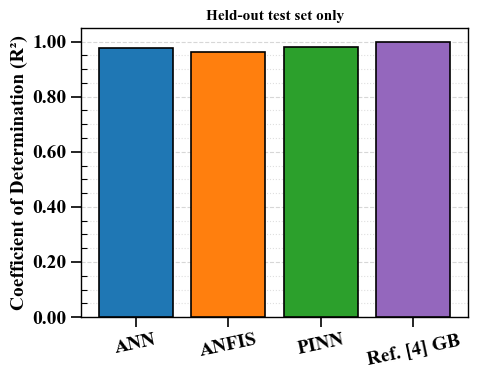

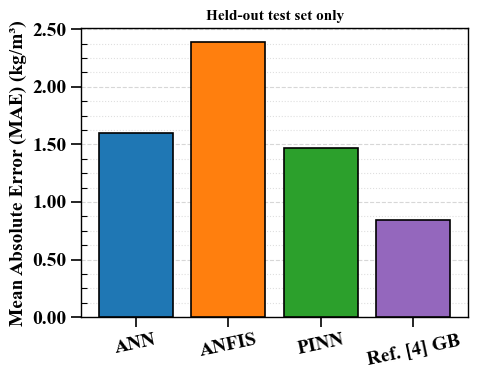

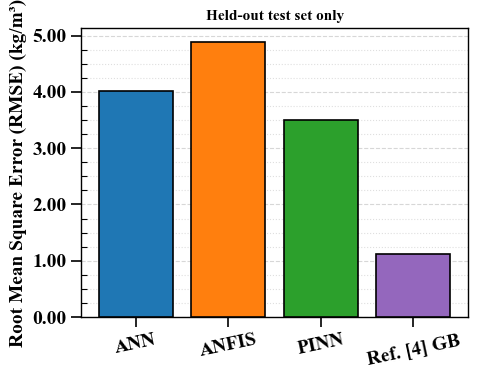

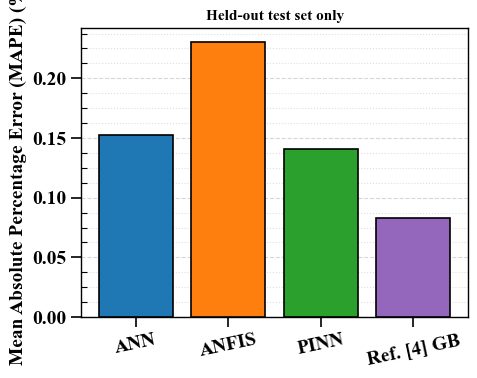

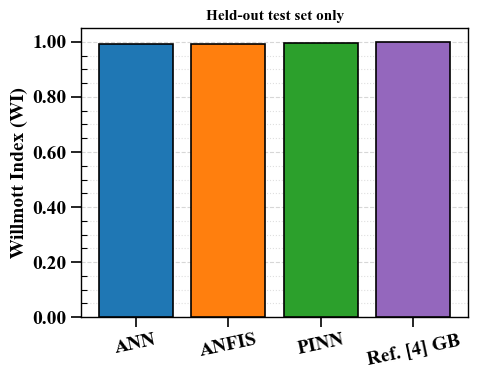

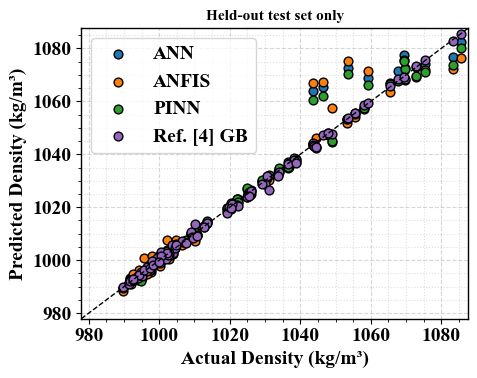


All reported performance metrics use TEST rows only.
Done. Results saved in: C:\Users\masal\Desktop\ANN_ANFIS_PINN_Ref4_Comparison


In [32]:
# TEST-SET-ONLY evaluation: ANN vs ANFIS vs PINN vs Ref. [4] GB
# Hybrid nanofluid density prediction; Jupyter compatible.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from matplotlib.ticker import AutoMinorLocator, FormatStrFormatter
from sklearn.model_selection import train_test_split, KFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingRegressor
from scipy.stats import randint, uniform
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

SEED = 42
EPOCHS = 1500
LEARNING_RATE = 0.001
LAMBDA_PHY = 0.001  # Physics regularization weight
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass
plt.rcParams.update({'font.family':'Times New Roman','font.weight':'bold',
                     'axes.labelweight':'bold','axes.titleweight':'bold'})
output_dir = os.path.join(os.path.expanduser('~'), 'Desktop', 'ANN_ANFIS_PINN_Ref4_Comparison')
try:
    os.makedirs(output_dir, exist_ok=True)
except OSError:
    output_dir = os.path.join(os.getcwd(), 'ANN_ANFIS_PINN_Corrected')
    os.makedirs(output_dir, exist_ok=True)

file_path = 'Density_Prediction_Dataset.csv'
if not os.path.isfile(file_path):
    raise FileNotFoundError(f'Place {file_path} in the current working directory: {os.getcwd()}')
df = pd.read_csv(file_path)
columns = ['NanoParticle','BaseFluid','Temperature','VolumeConcentration',
           'rho_np1','rho_np2','rho_bf','phi1','phi2','Density']
if len(df.columns) != len(columns):
    raise ValueError(f'Expected {len(columns)} columns, found {len(df.columns)}')
df.columns = columns
numeric_cols = ['Temperature','VolumeConcentration','rho_np1','rho_np2',
                'rho_bf','phi1','phi2','Density']
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df = df.dropna(subset=columns).reset_index(drop=True)
# The supplied dataset records phi1 and phi2 in percent.
df['phi1'] /= 100.0
df['phi2'] /= 100.0
if (df[['phi1','phi2']].lt(0).any().any() or
    (df['phi1']+df['phi2'] > 1).any()):
    raise ValueError('Invalid phi1/phi2 values after percent-to-fraction conversion.')
df['rho_physics'] = (df['phi1']*df['rho_np1'] + df['phi2']*df['rho_np2']
                     + (1-df['phi1']-df['phi2'])*df['rho_bf'])
features = ['NanoParticle','BaseFluid','Temperature','VolumeConcentration','phi1','phi2']
X = df[features]
y = df['Density'].to_numpy(dtype=np.float64).reshape(-1,1)
physics = df['rho_physics'].to_numpy(dtype=np.float64).reshape(-1,1)
indices = np.arange(len(df))
train_idx, test_idx = train_test_split(indices, test_size=0.2, random_state=SEED)
assert len(np.intersect1d(train_idx, test_idx)) == 0, 'Data leakage: overlapping rows'
print(f'TRAIN: {len(train_idx)} rows | HELD-OUT TEST: {len(test_idx)} rows')
try:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)
preprocessor = ColumnTransformer([
    ('num',StandardScaler(),['Temperature','VolumeConcentration','phi1','phi2']),
    ('cat',encoder,['NanoParticle','BaseFluid'])
])
X_train = np.asarray(preprocessor.fit_transform(X.iloc[train_idx]),dtype=np.float32)
X_test = np.asarray(preprocessor.transform(X.iloc[test_idx]),dtype=np.float32)
y_scaler = StandardScaler().fit(y[train_idx])
y_train = y_scaler.transform(y[train_idx]).astype(np.float32)
y_test_true = y[test_idx]
phy_train = y_scaler.transform(physics[train_idx]).astype(np.float32)
X_train_tf = tf.convert_to_tensor(X_train)
y_train_tf = tf.convert_to_tensor(y_train)
phy_train_tf = tf.convert_to_tensor(phy_train)

# ANN and PINN have precisely the same architecture (64-32-16).
# Their only possible difference is the physics term in the loss.
def make_network(input_dim):
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(input_dim,)),
        tf.keras.layers.Dense(64, activation='tanh'),
        tf.keras.layers.Dense(32, activation='tanh'),
        tf.keras.layers.Dense(16, activation='tanh'),
        tf.keras.layers.Dense(1)
    ])

class ANFIS(tf.keras.Model):
    def __init__(self, input_dim, n_rules=12):
        super().__init__()
        self.centers = self.add_weight(name='centers',shape=(input_dim,n_rules),initializer='random_normal',trainable=True)
        self.sigmas = self.add_weight(name='sigmas',shape=(input_dim,n_rules),initializer='ones',trainable=True)
        self.consequents = self.add_weight(name='consequents',shape=(n_rules,input_dim),initializer='random_normal',trainable=True)
        self.bias = self.add_weight(name='bias',shape=(n_rules,),initializer='zeros',trainable=True)
    def call(self,x,training=False):
        x_exp = tf.expand_dims(x,axis=2)
        centers = tf.expand_dims(self.centers,axis=0)
        sigmas = tf.expand_dims(tf.nn.softplus(self.sigmas)+1e-6,axis=0)
        membership = tf.exp(-0.5*tf.square((x_exp-centers)/sigmas))
        firing = tf.reduce_prod(membership,axis=1)
        normalized = firing/(tf.reduce_sum(firing,axis=1,keepdims=True)+1e-6)
        rules = tf.matmul(x,self.consequents,transpose_b=True)+self.bias
        return tf.reduce_sum(normalized*rules,axis=1,keepdims=True)

huber = tf.keras.losses.Huber()

def train_model(model, name, lambda_phy=0.0):
    optimizer = tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE)
    history = []
    # Exactly the same training algorithm for ANN and PINN at lambda=0.
    @tf.function
    def step(x, target, rho):
        with tf.GradientTape() as tape:
            pred = model(x,training=True)
            data_loss = huber(target,pred)
            if lambda_phy == 0.0:
                loss = data_loss
            else:
                loss = data_loss + tf.cast(lambda_phy,tf.float32)*huber(rho,pred)
        gradients = tape.gradient(loss,model.trainable_variables)
        optimizer.apply_gradients(zip(gradients,model.trainable_variables))
        return loss
    for epoch in range(EPOCHS):
        loss = step(X_train_tf,y_train_tf,phy_train_tf)
        history.append(float(loss.numpy()))
        if epoch % 300 == 0 or epoch == EPOCHS-1:
            print(f'{name}: epoch {epoch+1}/{EPOCHS}, loss={history[-1]:.6f}')
    return history

input_dim = X_train.shape[1]
ann = make_network(input_dim)
initial_weights = ann.get_weights()
pinn = make_network(input_dim)
pinn.set_weights(initial_weights)
anfis = ANFIS(input_dim, n_rules=12)
_ = anfis(X_train_tf[:1])  # Build variables before training
history_ann = train_model(ann,'ANN',lambda_phy=0.0)
history_anfis = train_model(anfis,'ANFIS',lambda_phy=0.0)
history_pinn = train_model(pinn,f'PINN lambda={LAMBDA_PHY:g}',lambda_phy=LAMBDA_PHY)

def predict(model, x):
    return y_scaler.inverse_transform(model(x,training=False).numpy()).ravel()

predictions = {
    'ANN':predict(ann,X_test),
    'ANFIS':predict(anfis,X_test),
    'PINN':predict(pinn,X_test)
}
# ------------------------------------------------------------
# REF. [4] GRADIENT BOOSTING: FAIR REIMPLEMENTATION
# Same original train/test indices. CV and preprocessing use
# training rows only; no augmentation/GWO is claimed here.
# Note: reference [4] published model is NOT exactly replicated.
# ------------------------------------------------------------
GB_SEARCH_ITER = 35  # Change to 10 for a quicker preliminary run
try:
    gb_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    gb_encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)

# Use the SAME predictors as ANN/ANFIS/PINN for a controlled
# algorithm comparison. The physical density inputs are NOT
# added to GB because they are not inputs to the neural models.
gb_preprocessor = ColumnTransformer([
    ('num', StandardScaler(), ['Temperature','VolumeConcentration','phi1','phi2']),
    ('cat', gb_encoder, ['NanoParticle','BaseFluid'])
])
gb_pipeline = Pipeline([
    ('preprocess', gb_preprocessor),
    ('model', GradientBoostingRegressor(random_state=SEED))
])
gb_space = {
    'model__n_estimators': randint(100, 601),
    'model__learning_rate': uniform(0.015, 0.135),
    'model__max_depth': randint(2, 6),
    'model__min_samples_leaf': randint(1, 7),
    'model__subsample': uniform(0.70, 0.30),
    'model__max_features': [None, 0.8, 1.0]
}
gb_search = RandomizedSearchCV(
    estimator=gb_pipeline,
    param_distributions=gb_space,
    n_iter=GB_SEARCH_ITER,
    scoring='neg_root_mean_squared_error',
    cv=KFold(n_splits=5, shuffle=True, random_state=SEED),
    n_jobs=-1,
    random_state=SEED,
    refit=True,
    verbose=1
)
print('\nTraining Ref. [4] Gradient Boosting baseline on TRAINING data only...')
gb_search.fit(X.iloc[train_idx], y[train_idx].ravel())
predictions['Ref. [4] GB'] = gb_search.predict(X.iloc[test_idx]).ravel()
print('Best GB CV RMSE:', -gb_search.best_score_)
print('Best GB parameters:', gb_search.best_params_)

actual = y_test_true.ravel()

def metrics(true, pred):
    """R2, MAE, RMSE (kg/m3), MAPE (%), and Willmott index."""
    true = np.asarray(true, dtype=np.float64).ravel()
    pred = np.asarray(pred, dtype=np.float64).ravel()
    r2 = r2_score(true, pred)
    mae = mean_absolute_error(true, pred)
    rmse = np.sqrt(mean_squared_error(true, pred))
    # MAPE is undefined for a zero actual value: explicitly report NaN.
    mape = (100.0 * np.mean(np.abs((true - pred) / true))
            if np.all(true != 0) else np.nan)
    mean_true = np.mean(true)
    wi_denominator = np.sum((np.abs(pred - mean_true) + np.abs(true - mean_true)) ** 2)
    wi_numerator = np.sum((true - pred) ** 2)
    wi = (1.0 - wi_numerator / wi_denominator if wi_denominator > 0
          else (1.0 if wi_numerator == 0 else np.nan))
    return [r2, mae, rmse, mape, wi]

results_df = pd.DataFrame([
    [name, *metrics(actual, pred)] for name, pred in predictions.items()
], columns=['Model', 'R2', 'MAE', 'RMSE', 'MAPE', 'WI'])
print('\nHELD-OUT TEST SET ONLY — Comparison Results')
results_df.insert(1, 'Dataset', 'Held-out test only')
results_df.insert(2, 'N_test', len(test_idx))
print(results_df.to_string(index=False,float_format=lambda v:f'{v:.6f}'))
if LAMBDA_PHY == 0.0:
    max_difference = float(np.max(np.abs(predictions['ANN']-predictions['PINN'])))
    print(f'\nANN vs PINN(lambda=0) max absolute prediction difference: {max_difference:.12g} kg/m³')
    np.testing.assert_allclose(predictions['ANN'],predictions['PINN'],rtol=1e-5,atol=1e-4,
        err_msg='ANN and PINN(lambda=0) should match: check environment determinism.')
    print('PASS: ANN and PINN(lambda=0) match within numerical tolerance.')

with pd.ExcelWriter(os.path.join(output_dir,'ANN_ANFIS_PINN_Ref4_Comparison.xlsx')) as writer:
    results_df.to_excel(writer, sheet_name='Held_Out_Test_Only', index=False)
    pd.DataFrame([{'Parameter': k, 'Selected Value': str(v)}
                  for k,v in gb_search.best_params_.items()]).to_excel(
        writer, sheet_name='GB_Best_Parameters', index=False)
    pd.DataFrame({'Interpretation': [
        'All metrics and figures are calculated EXCLUSIVELY from identical held-out test rows.',
        'Gradient Boosting is retrained on training rows only with 5-fold CV tuning.',
        'Same six input features used for ANN, ANFIS, PINN and Gradient Boosting.',
        'This is an algorithm-family benchmark, NOT a reproduction of the full ref. [4] workflow.',
        'Reference [4] used augmentation and metaheuristic optimization not reproduced here.',
        'Do not equate this GB score with the published R2 > 0.9999.'
    ]}).to_excel(writer, sheet_name='Method_Notes', index=False)
predictions_df = pd.DataFrame({'Dataset':['TEST']*len(test_idx), 'Original_Row_Index':test_idx, 'NanoParticle':df.iloc[test_idx]['NanoParticle'].to_numpy(), 'Actual Density':actual,
                               **{f'{k} Prediction':v for k,v in predictions.items()}})
predictions_df.to_excel(os.path.join(output_dir,'ANN_ANFIS_PINN_Ref4_Predictions.xlsx'),index=False)
pd.DataFrame({'Epoch':np.arange(1,EPOCHS+1),'ANN':history_ann,
              'ANFIS':history_anfis,'PINN':history_pinn}).to_csv(
                  os.path.join(output_dir,'Training_History.csv'),index=False)
colors={'ANN':'#1f77b4','ANFIS':'#ff7f0e','PINN':'#2ca02c',
        'Ref. [4] GB':'#9467bd'}

# Five metric bar charts including the Ref. [4] GB baseline.
metric_labels = {
    'R2': 'Coefficient of Determination (R²)',
    'MAE': 'Mean Absolute Error (MAE) (kg/m³)',
    'RMSE': 'Root Mean Square Error (RMSE) (kg/m³)',
    'MAPE': 'Mean Absolute Percentage Error (MAPE) (%)',
    'WI': 'Willmott Index (WI)'
}
for metric, ylabel in metric_labels.items():
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.set_axisbelow(True)
    ax.bar(results_df['Model'], results_df[metric],
           color=[colors[k] for k in results_df['Model']],
           edgecolor='black', linewidth=1.2, zorder=3)
    ax.set_ylabel(ylabel, fontweight='bold')
    ax.set_title('Held-out test set only', fontweight='bold', fontsize=11)
    ax.tick_params(axis='x', labelrotation=12)
    ax.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))
    ax.yaxis.set_minor_locator(AutoMinorLocator(4))
    ax.grid(True, which='major', axis='y', linestyle='--', alpha=.5, zorder=0)
    ax.grid(True, which='minor', axis='y', linestyle=':', alpha=.4, zorder=0)
    ax.tick_params(axis='both', which='major', direction='out', length=7, width=1.2)
    ax.tick_params(axis='y', which='minor', direction='in', length=4, width=.8)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight('bold')
    fig.tight_layout()
    filename = f'ANN_ANFIS_PINN_Ref4_{metric}_Comparison.png'
    fig.savefig(os.path.join(output_dir, filename), dpi=300,
                bbox_inches='tight', pad_inches=.1)
    plt.show()

fig,ax=plt.subplots(figsize=(5,4))
ax.set_axisbelow(True)
for name,pred in predictions.items():
    ax.scatter(actual,pred,color=colors[name],edgecolor='black',label=name,s=40,zorder=3)
y_min = min(980.0,float(np.min(actual)),*(float(np.min(v)) for v in predictions.values()))
y_max = max(float(np.max(actual)),*(float(np.max(v)) for v in predictions.values()))
margin = max((y_max-y_min)*.02,1.0)
y_min -= margin
y_max += margin
ax.set_xlim(y_min,y_max)
ax.set_ylim(y_min,y_max)
ax.plot([y_min,y_max],[y_min,y_max],'k--',linewidth=1,zorder=3)
ax.set_title('Held-out test set only', fontweight='bold', fontsize=11)
ax.set_xlabel('Actual Density (kg/m³)',fontweight='bold')
ax.set_ylabel('Predicted Density (kg/m³)',fontweight='bold')
ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))
ax.yaxis.set_major_formatter(FormatStrFormatter('%.0f'))
ax.xaxis.set_minor_locator(AutoMinorLocator(4))
ax.yaxis.set_minor_locator(AutoMinorLocator(4))
ax.grid(True,which='major',linestyle='--',alpha=.5,zorder=0)
ax.grid(True,which='minor',linestyle=':',alpha=.4,zorder=0)
ax.legend(prop={'weight':'bold','family':'Times New Roman'})
fig.tight_layout()
fig.savefig(os.path.join(output_dir,'ANN_ANFIS_PINN_Ref4_Actual_vs_Predicted.png'),dpi=300,bbox_inches='tight')
plt.show()
print('\nAll reported performance metrics use TEST rows only.')
print('Done. Results saved in:',output_dir)


TRAIN: 348 rows | HELD-OUT TEST: 88 rows (evaluation below uses TRAIN only)
ANN: epoch 1/1500, loss=0.435009
ANN: epoch 301/1500, loss=0.013282
ANN: epoch 601/1500, loss=0.011689
ANN: epoch 901/1500, loss=0.010715
ANN: epoch 1201/1500, loss=0.009298
ANN: epoch 1500/1500, loss=0.005986
ANFIS: epoch 1/1500, loss=0.404596
ANFIS: epoch 301/1500, loss=0.046347
ANFIS: epoch 601/1500, loss=0.017277
ANFIS: epoch 901/1500, loss=0.014589
ANFIS: epoch 1201/1500, loss=0.013395
ANFIS: epoch 1500/1500, loss=0.012073
PINN lambda=0.001: epoch 1/1500, loss=0.584875
PINN lambda=0.001: epoch 301/1500, loss=0.163039
PINN lambda=0.001: epoch 601/1500, loss=0.161447
PINN lambda=0.001: epoch 901/1500, loss=0.160473
PINN lambda=0.001: epoch 1201/1500, loss=0.159058
PINN lambda=0.001: epoch 1500/1500, loss=0.155213

Training Ref. [4] Gradient Boosting baseline on TRAINING data only...
Fitting 5 folds for each of 35 candidates, totalling 175 fits
Best GB CV RMSE: 1.5234197809844565
Best GB parameters: {'model__

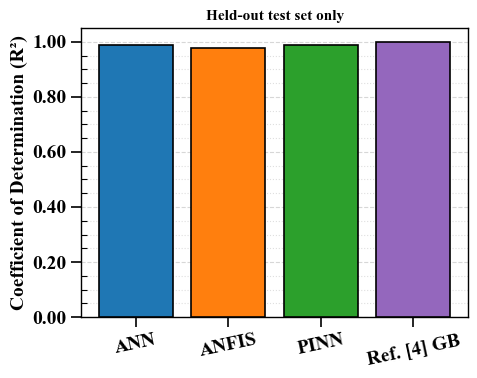

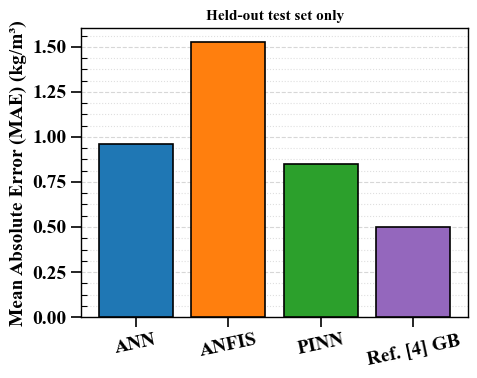

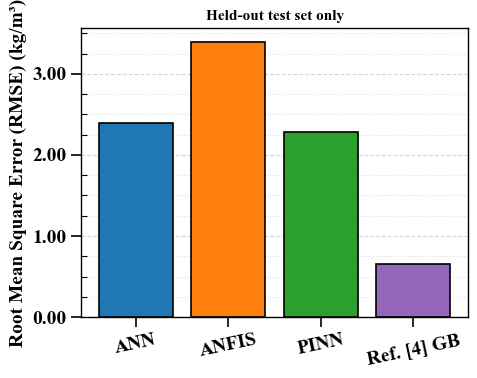

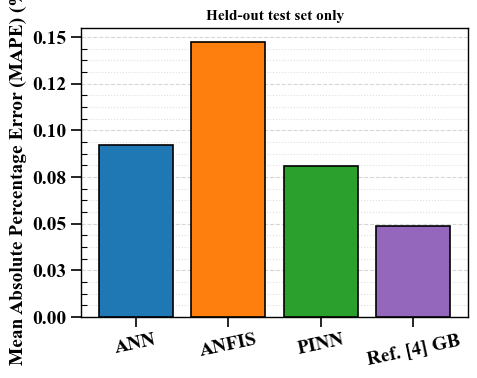

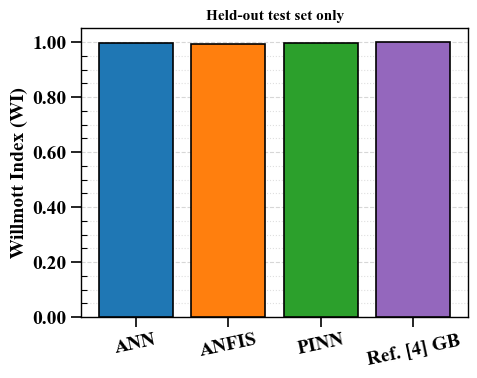

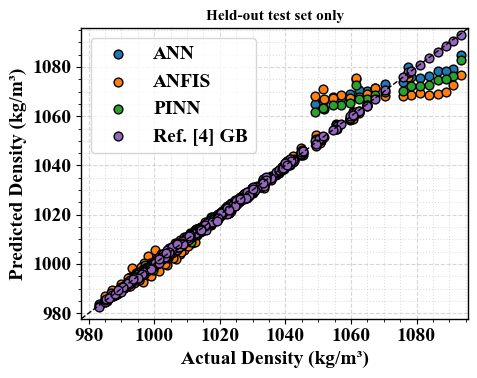


All reported performance metrics use TRAINING rows only; these are in-sample scores, NOT generalization scores.
Done. Results saved in: C:\Users\masal\Desktop\ANN_ANFIS_PINN_Ref4_Training_Comparison


In [33]:
# TRAINING-SET-ONLY evaluation: ANN vs ANFIS vs PINN vs Ref. [4] GB
# Hybrid nanofluid density prediction; Jupyter compatible.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from matplotlib.ticker import AutoMinorLocator, FormatStrFormatter
from sklearn.model_selection import train_test_split, KFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingRegressor
from scipy.stats import randint, uniform
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

SEED = 42
EPOCHS = 1500
LEARNING_RATE = 0.001
LAMBDA_PHY = 0.001  # Physics regularization weight
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass
plt.rcParams.update({'font.family':'Times New Roman','font.weight':'bold',
                     'axes.labelweight':'bold','axes.titleweight':'bold'})
output_dir = os.path.join(os.path.expanduser('~'), 'Desktop', 'ANN_ANFIS_PINN_Ref4_Training_Comparison')
try:
    os.makedirs(output_dir, exist_ok=True)
except OSError:
    output_dir = os.path.join(os.getcwd(), 'ANN_ANFIS_PINN_Corrected')
    os.makedirs(output_dir, exist_ok=True)

file_path = 'Density_Prediction_Dataset.csv'
if not os.path.isfile(file_path):
    raise FileNotFoundError(f'Place {file_path} in the current working directory: {os.getcwd()}')
df = pd.read_csv(file_path)
columns = ['NanoParticle','BaseFluid','Temperature','VolumeConcentration',
           'rho_np1','rho_np2','rho_bf','phi1','phi2','Density']
if len(df.columns) != len(columns):
    raise ValueError(f'Expected {len(columns)} columns, found {len(df.columns)}')
df.columns = columns
numeric_cols = ['Temperature','VolumeConcentration','rho_np1','rho_np2',
                'rho_bf','phi1','phi2','Density']
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df = df.dropna(subset=columns).reset_index(drop=True)
# The supplied dataset records phi1 and phi2 in percent.
df['phi1'] /= 100.0
df['phi2'] /= 100.0
if (df[['phi1','phi2']].lt(0).any().any() or
    (df['phi1']+df['phi2'] > 1).any()):
    raise ValueError('Invalid phi1/phi2 values after percent-to-fraction conversion.')
df['rho_physics'] = (df['phi1']*df['rho_np1'] + df['phi2']*df['rho_np2']
                     + (1-df['phi1']-df['phi2'])*df['rho_bf'])
features = ['NanoParticle','BaseFluid','Temperature','VolumeConcentration','phi1','phi2']
X = df[features]
y = df['Density'].to_numpy(dtype=np.float64).reshape(-1,1)
physics = df['rho_physics'].to_numpy(dtype=np.float64).reshape(-1,1)
indices = np.arange(len(df))
train_idx, test_idx = train_test_split(indices, test_size=0.2, random_state=SEED)
assert len(np.intersect1d(train_idx, test_idx)) == 0, 'Data leakage: overlapping rows'
print(f'TRAIN: {len(train_idx)} rows | HELD-OUT TEST: {len(test_idx)} rows (evaluation below uses TRAIN only)')
try:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)
preprocessor = ColumnTransformer([
    ('num',StandardScaler(),['Temperature','VolumeConcentration','phi1','phi2']),
    ('cat',encoder,['NanoParticle','BaseFluid'])
])
X_train = np.asarray(preprocessor.fit_transform(X.iloc[train_idx]),dtype=np.float32)
X_test = np.asarray(preprocessor.transform(X.iloc[test_idx]),dtype=np.float32)
y_scaler = StandardScaler().fit(y[train_idx])
y_train = y_scaler.transform(y[train_idx]).astype(np.float32)
y_test_true = y[test_idx]
phy_train = y_scaler.transform(physics[train_idx]).astype(np.float32)
X_train_tf = tf.convert_to_tensor(X_train)
y_train_tf = tf.convert_to_tensor(y_train)
phy_train_tf = tf.convert_to_tensor(phy_train)

# ANN and PINN have precisely the same architecture (64-32-16).
# Their only possible difference is the physics term in the loss.
def make_network(input_dim):
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(input_dim,)),
        tf.keras.layers.Dense(64, activation='tanh'),
        tf.keras.layers.Dense(32, activation='tanh'),
        tf.keras.layers.Dense(16, activation='tanh'),
        tf.keras.layers.Dense(1)
    ])

class ANFIS(tf.keras.Model):
    def __init__(self, input_dim, n_rules=12):
        super().__init__()
        self.centers = self.add_weight(name='centers',shape=(input_dim,n_rules),initializer='random_normal',trainable=True)
        self.sigmas = self.add_weight(name='sigmas',shape=(input_dim,n_rules),initializer='ones',trainable=True)
        self.consequents = self.add_weight(name='consequents',shape=(n_rules,input_dim),initializer='random_normal',trainable=True)
        self.bias = self.add_weight(name='bias',shape=(n_rules,),initializer='zeros',trainable=True)
    def call(self,x,training=False):
        x_exp = tf.expand_dims(x,axis=2)
        centers = tf.expand_dims(self.centers,axis=0)
        sigmas = tf.expand_dims(tf.nn.softplus(self.sigmas)+1e-6,axis=0)
        membership = tf.exp(-0.5*tf.square((x_exp-centers)/sigmas))
        firing = tf.reduce_prod(membership,axis=1)
        normalized = firing/(tf.reduce_sum(firing,axis=1,keepdims=True)+1e-6)
        rules = tf.matmul(x,self.consequents,transpose_b=True)+self.bias
        return tf.reduce_sum(normalized*rules,axis=1,keepdims=True)

huber = tf.keras.losses.Huber()

def train_model(model, name, lambda_phy=0.0):
    optimizer = tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE)
    history = []
    # Exactly the same training algorithm for ANN and PINN at lambda=0.
    @tf.function
    def step(x, target, rho):
        with tf.GradientTape() as tape:
            pred = model(x,training=True)
            data_loss = huber(target,pred)
            if lambda_phy == 0.0:
                loss = data_loss
            else:
                loss = data_loss + tf.cast(lambda_phy,tf.float32)*huber(rho,pred)
        gradients = tape.gradient(loss,model.trainable_variables)
        optimizer.apply_gradients(zip(gradients,model.trainable_variables))
        return loss
    for epoch in range(EPOCHS):
        loss = step(X_train_tf,y_train_tf,phy_train_tf)
        history.append(float(loss.numpy()))
        if epoch % 300 == 0 or epoch == EPOCHS-1:
            print(f'{name}: epoch {epoch+1}/{EPOCHS}, loss={history[-1]:.6f}')
    return history

input_dim = X_train.shape[1]
ann = make_network(input_dim)
initial_weights = ann.get_weights()
pinn = make_network(input_dim)
pinn.set_weights(initial_weights)
anfis = ANFIS(input_dim, n_rules=12)
_ = anfis(X_train_tf[:1])  # Build variables before training
history_ann = train_model(ann,'ANN',lambda_phy=0.0)
history_anfis = train_model(anfis,'ANFIS',lambda_phy=0.0)
history_pinn = train_model(pinn,f'PINN lambda={LAMBDA_PHY:g}',lambda_phy=LAMBDA_PHY)

def predict(model, x):
    return y_scaler.inverse_transform(model(x,training=False).numpy()).ravel()

predictions = {
    'ANN':predict(ann,X_train),
    'ANFIS':predict(anfis,X_train),
    'PINN':predict(pinn,X_train)
}
# ------------------------------------------------------------
# REF. [4] GRADIENT BOOSTING: FAIR REIMPLEMENTATION
# Same original train/test indices. CV and preprocessing use
# training rows only; no augmentation/GWO is claimed here.
# Note: reference [4] published model is NOT exactly replicated.
# ------------------------------------------------------------
GB_SEARCH_ITER = 35  # Change to 10 for a quicker preliminary run
try:
    gb_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    gb_encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)

# Use the SAME predictors as ANN/ANFIS/PINN for a controlled
# algorithm comparison. The physical density inputs are NOT
# added to GB because they are not inputs to the neural models.
gb_preprocessor = ColumnTransformer([
    ('num', StandardScaler(), ['Temperature','VolumeConcentration','phi1','phi2']),
    ('cat', gb_encoder, ['NanoParticle','BaseFluid'])
])
gb_pipeline = Pipeline([
    ('preprocess', gb_preprocessor),
    ('model', GradientBoostingRegressor(random_state=SEED))
])
gb_space = {
    'model__n_estimators': randint(100, 601),
    'model__learning_rate': uniform(0.015, 0.135),
    'model__max_depth': randint(2, 6),
    'model__min_samples_leaf': randint(1, 7),
    'model__subsample': uniform(0.70, 0.30),
    'model__max_features': [None, 0.8, 1.0]
}
gb_search = RandomizedSearchCV(
    estimator=gb_pipeline,
    param_distributions=gb_space,
    n_iter=GB_SEARCH_ITER,
    scoring='neg_root_mean_squared_error',
    cv=KFold(n_splits=5, shuffle=True, random_state=SEED),
    n_jobs=-1,
    random_state=SEED,
    refit=True,
    verbose=1
)
print('\nTraining Ref. [4] Gradient Boosting baseline on TRAINING data only...')
gb_search.fit(X.iloc[train_idx], y[train_idx].ravel())
predictions['Ref. [4] GB'] = gb_search.predict(X.iloc[train_idx]).ravel()
print('Best GB CV RMSE:', -gb_search.best_score_)
print('Best GB parameters:', gb_search.best_params_)

actual = y[train_idx].ravel()

def metrics(true, pred):
    """R2, MAE, RMSE (kg/m3), MAPE (%), and Willmott index."""
    true = np.asarray(true, dtype=np.float64).ravel()
    pred = np.asarray(pred, dtype=np.float64).ravel()
    r2 = r2_score(true, pred)
    mae = mean_absolute_error(true, pred)
    rmse = np.sqrt(mean_squared_error(true, pred))
    # MAPE is undefined for a zero actual value: explicitly report NaN.
    mape = (100.0 * np.mean(np.abs((true - pred) / true))
            if np.all(true != 0) else np.nan)
    mean_true = np.mean(true)
    wi_denominator = np.sum((np.abs(pred - mean_true) + np.abs(true - mean_true)) ** 2)
    wi_numerator = np.sum((true - pred) ** 2)
    wi = (1.0 - wi_numerator / wi_denominator if wi_denominator > 0
          else (1.0 if wi_numerator == 0 else np.nan))
    return [r2, mae, rmse, mape, wi]

results_df = pd.DataFrame([
    [name, *metrics(actual, pred)] for name, pred in predictions.items()
], columns=['Model', 'R2', 'MAE', 'RMSE', 'MAPE', 'WI'])
print('\nTRAINING SET ONLY — In-Sample Comparison Results')
results_df.insert(1, 'Dataset', 'Training only')
results_df.insert(2, 'N_train', len(train_idx))
print(results_df.to_string(index=False,float_format=lambda v:f'{v:.6f}'))
if LAMBDA_PHY == 0.0:
    max_difference = float(np.max(np.abs(predictions['ANN']-predictions['PINN'])))
    print(f'\nANN vs PINN(lambda=0) max absolute prediction difference: {max_difference:.12g} kg/m³')
    np.testing.assert_allclose(predictions['ANN'],predictions['PINN'],rtol=1e-5,atol=1e-4,
        err_msg='ANN and PINN(lambda=0) should match: check environment determinism.')
    print('PASS: ANN and PINN(lambda=0) match within numerical tolerance.')

with pd.ExcelWriter(os.path.join(output_dir,'ANN_ANFIS_PINN_Ref4_Training_Comparison.xlsx')) as writer:
    results_df.to_excel(writer, sheet_name='Training_Only', index=False)
    pd.DataFrame([{'Parameter': k, 'Selected Value': str(v)}
                  for k,v in gb_search.best_params_.items()]).to_excel(
        writer, sheet_name='GB_Best_Parameters', index=False)
    pd.DataFrame({'Interpretation': [
        'All metrics and figures are calculated EXCLUSIVELY from identical training rows (in-sample).',
        'Gradient Boosting is retrained on training rows only with 5-fold CV tuning.',
        'Same six input features used for ANN, ANFIS, PINN and Gradient Boosting.',
        'This is an algorithm-family benchmark, NOT a reproduction of the full ref. [4] workflow.',
        'Reference [4] used augmentation and metaheuristic optimization not reproduced here.',
        'Training scores are optimistic and must not be compared to published test scores or used to claim generalization.'
    ]}).to_excel(writer, sheet_name='Method_Notes', index=False)
predictions_df = pd.DataFrame({'Dataset':['TRAIN']*len(train_idx), 'Original_Row_Index':train_idx, 'NanoParticle':df.iloc[train_idx]['NanoParticle'].to_numpy(), 'Actual Density':actual,
                               **{f'{k} Prediction':v for k,v in predictions.items()}})
predictions_df.to_excel(os.path.join(output_dir,'ANN_ANFIS_PINN_Ref4_Training_Predictions.xlsx'),index=False)
pd.DataFrame({'Epoch':np.arange(1,EPOCHS+1),'ANN':history_ann,
              'ANFIS':history_anfis,'PINN':history_pinn}).to_csv(
                  os.path.join(output_dir,'Training_History.csv'),index=False)
colors={'ANN':'#1f77b4','ANFIS':'#ff7f0e','PINN':'#2ca02c',
        'Ref. [4] GB':'#9467bd'}

# Five metric bar charts including the Ref. [4] GB baseline.
metric_labels = {
    'R2': 'Coefficient of Determination (R²)',
    'MAE': 'Mean Absolute Error (MAE) (kg/m³)',
    'RMSE': 'Root Mean Square Error (RMSE) (kg/m³)',
    'MAPE': 'Mean Absolute Percentage Error (MAPE) (%)',
    'WI': 'Willmott Index (WI)'
}
for metric, ylabel in metric_labels.items():
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.set_axisbelow(True)
    ax.bar(results_df['Model'], results_df[metric],
           color=[colors[k] for k in results_df['Model']],
           edgecolor='black', linewidth=1.2, zorder=3)
    ax.set_ylabel(ylabel, fontweight='bold')
    ax.set_title('Held-out test set only', fontweight='bold', fontsize=11)
    ax.tick_params(axis='x', labelrotation=12)
    ax.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))
    ax.yaxis.set_minor_locator(AutoMinorLocator(4))
    ax.grid(True, which='major', axis='y', linestyle='--', alpha=.5, zorder=0)
    ax.grid(True, which='minor', axis='y', linestyle=':', alpha=.4, zorder=0)
    ax.tick_params(axis='both', which='major', direction='out', length=7, width=1.2)
    ax.tick_params(axis='y', which='minor', direction='in', length=4, width=.8)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight('bold')
    fig.tight_layout()
    filename = f'ANN_ANFIS_PINN_Ref4_TRAIN_{metric}_Comparison.png'
    fig.savefig(os.path.join(output_dir, filename), dpi=300,
                bbox_inches='tight', pad_inches=.1)
    plt.show()

fig,ax=plt.subplots(figsize=(5,4))
ax.set_axisbelow(True)
for name,pred in predictions.items():
    ax.scatter(actual,pred,color=colors[name],edgecolor='black',label=name,s=40,zorder=3)
y_min = min(980.0,float(np.min(actual)),*(float(np.min(v)) for v in predictions.values()))
y_max = max(float(np.max(actual)),*(float(np.max(v)) for v in predictions.values()))
margin = max((y_max-y_min)*.02,1.0)
y_min -= margin
y_max += margin
ax.set_xlim(y_min,y_max)
ax.set_ylim(y_min,y_max)
ax.plot([y_min,y_max],[y_min,y_max],'k--',linewidth=1,zorder=3)
ax.set_title('Held-out test set only', fontweight='bold', fontsize=11)
ax.set_xlabel('Actual Density (kg/m³)',fontweight='bold')
ax.set_ylabel('Predicted Density (kg/m³)',fontweight='bold')
ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))
ax.yaxis.set_major_formatter(FormatStrFormatter('%.0f'))
ax.xaxis.set_minor_locator(AutoMinorLocator(4))
ax.yaxis.set_minor_locator(AutoMinorLocator(4))
ax.grid(True,which='major',linestyle='--',alpha=.5,zorder=0)
ax.grid(True,which='minor',linestyle=':',alpha=.4,zorder=0)
ax.legend(prop={'weight':'bold','family':'Times New Roman'})
fig.tight_layout()
fig.savefig(os.path.join(output_dir,'ANN_ANFIS_PINN_Ref4_TRAIN_Actual_vs_Predicted.png'),dpi=300,bbox_inches='tight')
plt.show()
print('\nAll reported performance metrics use TRAINING rows only; these are in-sample scores, NOT generalization scores.')
print('Done. Results saved in:',output_dir)
